In [6]:
# ============================================================
# ARGUS.MAIN — LOAD ARGUS.DATASET
# ============================================================

import os
import pandas as pd

ARGUS_ROOT = "/kaggle/input/notebooks/aravkataria/argus-dataset/argus_preprocessed"

MASTER_PATH = os.path.join(
    ARGUS_ROOT,
    "master_metadata.csv"
)

IMAGE_ROOT = os.path.join(
    ARGUS_ROOT,
    "images"
)

print("=" * 70)
print("ARGUS.MAIN — LOADING ARGUS.DATASET")
print("=" * 70)

# ------------------------------------------------------------
# CHECK PATHS
# ------------------------------------------------------------

print("\nDataset root:")
print(ARGUS_ROOT)

print("\nMaster metadata:")
print(MASTER_PATH)

print("\nImage directory:")
print(IMAGE_ROOT)

if not os.path.isfile(MASTER_PATH):
    raise FileNotFoundError(
        f"master_metadata.csv not found:\n{MASTER_PATH}"
    )

if not os.path.isdir(IMAGE_ROOT):
    raise FileNotFoundError(
        f"Image directory not found:\n{IMAGE_ROOT}"
    )

# ------------------------------------------------------------
# LOAD MASTER METADATA
# ------------------------------------------------------------

df = pd.read_csv(MASTER_PATH)

print("\n" + "-" * 70)
print("MASTER METADATA")
print("-" * 70)

print("Records :", len(df))
print("Columns :", df.columns.tolist())

# ------------------------------------------------------------
# SHOW DATASET DISTRIBUTION
# ------------------------------------------------------------

if "dataset" in df.columns:

    print("\nDataset distribution:")
    print(df["dataset"].value_counts())

# ------------------------------------------------------------
# SHOW LABEL DISTRIBUTION
# ------------------------------------------------------------

for label_column in [
    "label",
    "is_tampered",
    "target"
]:

    if label_column in df.columns:

        print(f"\n{label_column} distribution:")
        print(df[label_column].value_counts())

# ------------------------------------------------------------
# IMAGE COUNT
# ------------------------------------------------------------

image_extensions = (
    ".jpg",
    ".jpeg",
    ".png",
    ".tif",
    ".tiff",
    ".bmp",
    ".webp"
)

image_files = []

for file in os.listdir(IMAGE_ROOT):

    if file.lower().endswith(image_extensions):
        image_files.append(file)

print("\nImages available :", len(image_files))

# ------------------------------------------------------------
# SHOW SAMPLE METADATA
# ------------------------------------------------------------

print("\nSample records:")
print(df.head(5).to_string(index=False))

print("\n" + "=" * 70)
print("ARGUS.DATASET LOADED SUCCESSFULLY")
print("=" * 70)

ARGUS.MAIN — LOADING ARGUS.DATASET

Dataset root:
/kaggle/input/notebooks/aravkataria/argus-dataset/argus_preprocessed

Master metadata:
/kaggle/input/notebooks/aravkataria/argus-dataset/argus_preprocessed/master_metadata.csv

Image directory:
/kaggle/input/notebooks/aravkataria/argus-dataset/argus_preprocessed/images

----------------------------------------------------------------------
MASTER METADATA
----------------------------------------------------------------------
Records : 2992
Columns : ['sample_id', 'image_path', 'mask_path', 'label', 'has_mask', 'source_dataset']

label distribution:
label
authentic    1992
forged       1000
Name: count, dtype: int64

Images available : 2992

Sample records:
              sample_id                                                        image_path  mask_path     label  has_mask source_dataset
CASIA2_Au_pla_30322.jpg /kaggle/working/argus_preprocessed/images/CASIA2_Au_pla_30322.jpg        NaN authentic     False         CASIA2
CASIA2_Au_ani

In [7]:
# ============================================================
# ARGUS.MAIN — RESOLVE DATASET PATHS
# ============================================================

import os
import pandas as pd

print("=" * 70)
print("ARGUS.MAIN — RESOLVING IMAGE PATHS")
print("=" * 70)

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

ARGUS_ROOT = "/kaggle/input/notebooks/aravkataria/argus-dataset/argus_preprocessed"
IMAGE_ROOT = os.path.join(ARGUS_ROOT, "images")

MASTER_PATH = os.path.join(
    ARGUS_ROOT,
    "master_metadata.csv"
)

# ------------------------------------------------------------
# LOAD
# ------------------------------------------------------------

df = pd.read_csv(MASTER_PATH)

# ------------------------------------------------------------
# USE SAMPLE_ID TO BUILD REAL KAGGLE PATH
# ------------------------------------------------------------

df["image_path"] = df["sample_id"].apply(
    lambda x: os.path.join(IMAGE_ROOT, str(x))
)

# ------------------------------------------------------------
# VERIFY IMAGES
# ------------------------------------------------------------

df["image_exists"] = df["image_path"].apply(
    os.path.isfile
)

total = len(df)
found = int(df["image_exists"].sum())
missing = total - found

print("\nTotal records :", total)
print("Images found  :", found)
print("Images missing:", missing)

# ------------------------------------------------------------
# MISSING FILES
# ------------------------------------------------------------

if missing > 0:

    print("\nMissing image examples:")

    print(
        df.loc[
            ~df["image_exists"],
            ["sample_id", "source_dataset", "label"]
        ]
        .head(10)
        .to_string(index=False)
    )

else:

    print("\n✅ ALL IMAGES FOUND")

# ------------------------------------------------------------
# DATASET DISTRIBUTION
# ------------------------------------------------------------

print("\nDataset distribution:")
print(df["source_dataset"].value_counts())

print("\nDataset × Label:")
print(
    pd.crosstab(
        df["source_dataset"],
        df["label"]
    )
)

# ------------------------------------------------------------
# CLEAN DATAFRAME
# ------------------------------------------------------------

df = df[df["image_exists"]].copy()

df.drop(
    columns=["image_exists"],
    inplace=True
)

df.reset_index(drop=True, inplace=True)

print("\nUsable records:", len(df))

print("\n" + "=" * 70)
print("PATH RESOLUTION COMPLETE")
print("=" * 70)

ARGUS.MAIN — RESOLVING IMAGE PATHS

Total records : 2992
Images found  : 2992
Images missing: 0

✅ ALL IMAGES FOUND

Dataset distribution:
source_dataset
CASIA2      1993
RVL-CDIP     500
CEDAR        499
Name: count, dtype: int64

Dataset × Label:
label           authentic  forged
source_dataset                   
CASIA2                993    1000
CEDAR                 499       0
RVL-CDIP              500       0

Usable records: 2992

PATH RESOLUTION COMPLETE


In [8]:
# ============================================================
# ARGUS.MAIN — TRAIN / VALIDATION SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

print("=" * 70)
print("ARGUS.MAIN — TRAIN / VALIDATION SPLIT")
print("=" * 70)

SEED = 42

# ------------------------------------------------------------
# NUMERIC LABEL
# ------------------------------------------------------------

df["label_id"] = df["label"].map({
    "authentic": 0,
    "forged": 1
})

if df["label_id"].isna().any():
    raise ValueError("Unknown labels detected.")

df["label_id"] = df["label_id"].astype(int)

# ------------------------------------------------------------
# STRATIFIED SPLIT
# ------------------------------------------------------------

train_df, val_df = train_test_split(
    df,
    test_size=0.15,
    random_state=SEED,
    stratify=df["label_id"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

# ------------------------------------------------------------
# RESULTS
# ------------------------------------------------------------

print("\nTotal:", len(df))
print("Train:", len(train_df))
print("Validation:", len(val_df))

print("\nTRAIN LABELS:")
print(train_df["label"].value_counts())

print("\nVALIDATION LABELS:")
print(val_df["label"].value_counts())

print("\nTRAIN percentages:")
print(
    (train_df["label"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nVALIDATION percentages:")
print(
    (val_df["label"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\n" + "=" * 70)
print("SPLIT COMPLETE")
print("=" * 70)

ARGUS.MAIN — TRAIN / VALIDATION SPLIT

Total: 2992
Train: 2543
Validation: 449

TRAIN LABELS:
label
authentic    1693
forged        850
Name: count, dtype: int64

VALIDATION LABELS:
label
authentic    299
forged       150
Name: count, dtype: int64

TRAIN percentages:
label
authentic    66.57
forged       33.43
Name: proportion, dtype: float64

VALIDATION percentages:
label
authentic    66.59
forged       33.41
Name: proportion, dtype: float64

SPLIT COMPLETE


In [9]:
# ============================================================
# ARGUS.MAIN — IMAGE TRANSFORMS
# ============================================================

import torch
from torchvision import transforms

print("=" * 70)
print("ARGUS.MAIN — CREATING IMAGE TRANSFORMS")
print("=" * 70)

IMAGE_SIZE = 224

# ImageNet normalization for pretrained models
NORMALIZE_MEAN = [0.485, 0.456, 0.406]
NORMALIZE_STD = [0.229, 0.224, 0.225]

# ------------------------------------------------------------
# TRAIN TRANSFORM
# ------------------------------------------------------------

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(5),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=NORMALIZE_MEAN,
        std=NORMALIZE_STD
    )
])

# ------------------------------------------------------------
# VALIDATION TRANSFORM
# ------------------------------------------------------------

val_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=NORMALIZE_MEAN,
        std=NORMALIZE_STD
    )
])

print(f"\nImage size: {IMAGE_SIZE} × {IMAGE_SIZE}")
print("Training augmentation: enabled")
print("Validation augmentation: disabled")

print("\n" + "=" * 70)
print("STEP 4 COMPLETE")
print("=" * 70)

ARGUS.MAIN — CREATING IMAGE TRANSFORMS

Image size: 224 × 224
Training augmentation: enabled
Validation augmentation: disabled

STEP 4 COMPLETE


In [10]:
# ============================================================
# ARGUS.MAIN — PYTORCH DATASET
# ============================================================

from PIL import Image
from torch.utils.data import Dataset

print("=" * 70)
print("ARGUS.MAIN — CREATING PYTORCH DATASET")
print("=" * 70)


class ARGUSDataset(Dataset):

    def __init__(self, dataframe, transform=None):

        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]

        image_path = row["image_path"]
        label = int(row["label_id"])

        try:

            image = Image.open(image_path)

            # Convert grayscale/RGBA/etc. to standard RGB
            image = image.convert("RGB")

        except Exception as e:

            raise RuntimeError(
                f"\nCould not load image:\n"
                f"{image_path}\n"
                f"Dataset: {row['source_dataset']}\n"
                f"Label: {row['label']}\n"
                f"Error: {e}"
            )

        if self.transform is not None:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)


# ------------------------------------------------------------
# CREATE DATASETS
# ------------------------------------------------------------

train_dataset = ARGUSDataset(
    train_df,
    transform=train_transform
)

val_dataset = ARGUSDataset(
    val_df,
    transform=val_transform
)


# ------------------------------------------------------------
# CHECK
# ------------------------------------------------------------

print("\nTrain samples     :", len(train_dataset))
print("Validation samples:", len(val_dataset))

print("\n" + "=" * 70)
print("STEP 5 COMPLETE")
print("=" * 70)

ARGUS.MAIN — CREATING PYTORCH DATASET

Train samples     : 2543
Validation samples: 449

STEP 5 COMPLETE


In [18]:
# ============================================================
# ARGUS.MAIN — DATALOADERS
# ============================================================

from torch.utils.data import DataLoader

print("=" * 70)
print("ARGUS.MAIN — CREATING DATALOADERS")
print("=" * 70)

# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

BATCH_SIZE = 32
NUM_WORKERS = 0

# ------------------------------------------------------------
# TRAIN LOADER
# ------------------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

# ------------------------------------------------------------
# VALIDATION LOADER
# ------------------------------------------------------------

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

# ------------------------------------------------------------
# BASIC INFO
# ------------------------------------------------------------

print("\nBatch size       :", BATCH_SIZE)
print("Workers          :", NUM_WORKERS)
print("Training batches :", len(train_loader))
print("Validation batches:", len(val_loader))

print("\n" + "=" * 70)
print("STEP 6 COMPLETE")
print("=" * 70)

ARGUS.MAIN — CREATING DATALOADERS

Batch size       : 32
Workers          : 0
Training batches : 80
Validation batches: 15

STEP 6 COMPLETE


In [19]:
# ============================================================
# ARGUS.MAIN — TEST DATALOADER
# ============================================================

print("=" * 70)
print("ARGUS.MAIN — TESTING DATA LOADER")
print("=" * 70)

images, labels = next(iter(train_loader))

print("\nImages:")
print("Shape :", images.shape)
print("Type  :", images.dtype)

print("\nLabels:")
print("Shape :", labels.shape)
print("Values:", labels.tolist())

print("\nLabel counts in batch:")

unique, counts = torch.unique(
    labels,
    return_counts=True
)

for label_id, count in zip(unique.tolist(), counts.tolist()):

    label_name = {
        0: "authentic",
        1: "forged"
    }[label_id]

    print(f"{label_name:10s}: {count}")

print("\nGPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\n" + "=" * 70)
print("STEP 6 TEST COMPLETE")
print("=" * 70)

ARGUS.MAIN — TESTING DATA LOADER

Images:
Shape : torch.Size([32, 3, 224, 224])
Type  : torch.float32

Labels:
Shape : torch.Size([32])
Values: [0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0]

Label counts in batch:
authentic : 20
forged    : 12

GPU available: True
GPU: Tesla T4

STEP 6 TEST COMPLETE


In [20]:
# ============================================================
# ARGUS.MAIN — MODEL INITIALIZATION
# ============================================================

import torch
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

print("=" * 70)
print("ARGUS.MAIN — INITIALIZING MODEL")
print("=" * 70)

# ------------------------------------------------------------
# DEVICE
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nDevice:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# PRETRAINED MODEL
# ------------------------------------------------------------

weights = EfficientNet_B0_Weights.DEFAULT

model = efficientnet_b0(
    weights=weights
)

# ------------------------------------------------------------
# REPLACE CLASSIFIER
# ------------------------------------------------------------

num_features = model.classifier[1].in_features

model.classifier = nn.Sequential(
    nn.Dropout(p=0.3),
    nn.Linear(num_features, 2)
)

# ------------------------------------------------------------
# MOVE TO GPU
# ------------------------------------------------------------

model = model.to(device)

# ------------------------------------------------------------
# PARAMETER INFO
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nModel: EfficientNet-B0")
print("Classes: 2")
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

print("\n" + "=" * 70)
print("STEP 7 COMPLETE")
print("=" * 70)

ARGUS.MAIN — INITIALIZING MODEL

Device: cuda
GPU: Tesla T4

Model: EfficientNet-B0
Classes: 2
Total parameters: 4,010,110
Trainable parameters: 4,010,110

STEP 7 COMPLETE


In [21]:
# ============================================================
# ARGUS.MAIN — TRAINING CONFIGURATION
# ============================================================

import torch
import torch.nn as nn

print("=" * 70)
print("ARGUS.MAIN — TRAINING CONFIGURATION")
print("=" * 70)

# ------------------------------------------------------------
# CLASS WEIGHTS
# ------------------------------------------------------------

authentic_count = int(
    (train_df["label_id"] == 0).sum()
)

forged_count = int(
    (train_df["label_id"] == 1).sum()
)

total_count = authentic_count + forged_count

# Inverse-frequency weighting
weight_authentic = total_count / (2 * authentic_count)
weight_forged = total_count / (2 * forged_count)

class_weights = torch.tensor(
    [
        weight_authentic,
        weight_forged
    ],
    dtype=torch.float32,
    device=device
)

print("\nClass counts:")
print("Authentic:", authentic_count)
print("Forged   :", forged_count)

print("\nClass weights:")
print("Authentic:", round(weight_authentic, 4))
print("Forged   :", round(weight_forged, 4))

# ------------------------------------------------------------
# LOSS
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# ------------------------------------------------------------
# OPTIMIZER
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# ------------------------------------------------------------
# SCHEDULER
# ------------------------------------------------------------

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

# ------------------------------------------------------------
# TRAINING SETTINGS
# ------------------------------------------------------------

NUM_EPOCHS = 15

print("\nOptimizer : AdamW")
print("Learning rate:", 1e-4)
print("Weight decay:", 1e-4)
print("Scheduler   : ReduceLROnPlateau")
print("Epochs      :", NUM_EPOCHS)

print("\n" + "=" * 70)
print("STEP 8 COMPLETE")
print("=" * 70)

ARGUS.MAIN — TRAINING CONFIGURATION

Class counts:
Authentic: 1693
Forged   : 850

Class weights:
Authentic: 0.751
Forged   : 1.4959

Optimizer : AdamW
Learning rate: 0.0001
Weight decay: 0.0001
Scheduler   : ReduceLROnPlateau
Epochs      : 15

STEP 8 COMPLETE


In [22]:
# ============================================================
# ARGUS.MAIN — MODEL TRAINING WITH TQDM
# ============================================================

import os
import time
import numpy as np
import torch

from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("=" * 70)
print("ARGUS.MAIN — TRAINING")
print("=" * 70)

# ------------------------------------------------------------
# CHECKPOINT DIRECTORY
# ------------------------------------------------------------

CHECKPOINT_DIR = "/kaggle/working/ARGUS_DATASET/models"

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

BEST_MODEL_PATH = os.path.join(
    CHECKPOINT_DIR,
    "argus_efficientnet_b0_best.pth"
)

# ------------------------------------------------------------
# HISTORY
# ------------------------------------------------------------

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
    "val_precision": [],
    "val_recall": [],
    "val_f1": [],
    "val_auc": [],
    "learning_rate": []
}

best_f1 = -1.0

# ------------------------------------------------------------
# TRAINING LOOP
# ------------------------------------------------------------

for epoch in range(NUM_EPOCHS):

    epoch_start = time.time()

    # ========================================================
    # TRAIN
    # ========================================================

    model.train()

    running_loss = 0.0
    train_predictions = []
    train_targets = []

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1:02d}/{NUM_EPOCHS} [TRAIN]",
        leave=True
    )

    for images, labels in train_bar:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += (
            loss.item() * images.size(0)
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        train_predictions.extend(
            predictions.detach()
            .cpu()
            .numpy()
        )

        train_targets.extend(
            labels.detach()
            .cpu()
            .numpy()
        )

        train_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss = (
        running_loss /
        len(train_loader.dataset)
    )

    train_accuracy = accuracy_score(
        train_targets,
        train_predictions
    )

    # ========================================================
    # VALIDATION
    # ========================================================

    model.eval()

    val_running_loss = 0.0

    val_predictions = []
    val_targets = []
    val_probabilities = []

    val_bar = tqdm(
        val_loader,
        desc=f"Epoch {epoch + 1:02d}/{NUM_EPOCHS} [VAL]",
        leave=True
    )

    with torch.no_grad():

        for images, labels in val_bar:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            val_running_loss += (
                loss.item() * images.size(0)
            )

            probabilities = torch.softmax(
                outputs,
                dim=1
            )[:, 1]

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            val_predictions.extend(
                predictions.cpu().numpy()
            )

            val_targets.extend(
                labels.cpu().numpy()
            )

            val_probabilities.extend(
                probabilities.cpu().numpy()
            )

            val_bar.set_postfix(
                loss=f"{loss.item():.4f}"
            )

    val_loss = (
        val_running_loss /
        len(val_loader.dataset)
    )

    val_accuracy = accuracy_score(
        val_targets,
        val_predictions
    )

    val_precision = precision_score(
        val_targets,
        val_predictions,
        zero_division=0
    )

    val_recall = recall_score(
        val_targets,
        val_predictions,
        zero_division=0
    )

    val_f1 = f1_score(
        val_targets,
        val_predictions,
        zero_division=0
    )

    try:

        val_auc = roc_auc_score(
            val_targets,
            val_probabilities
        )

    except ValueError:

        val_auc = float("nan")

    # ========================================================
    # SCHEDULER
    # ========================================================

    scheduler.step(val_f1)

    current_lr = optimizer.param_groups[0]["lr"]

    # ========================================================
    # SAVE HISTORY
    # ========================================================

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_accuracy"].append(
        train_accuracy
    )

    history["val_accuracy"].append(
        val_accuracy
    )

    history["val_precision"].append(
        val_precision
    )

    history["val_recall"].append(
        val_recall
    )

    history["val_f1"].append(
        val_f1
    )

    history["val_auc"].append(
        val_auc
    )

    history["learning_rate"].append(
        current_lr
    )

    # ========================================================
    # SAVE BEST MODEL
    # ========================================================

    if val_f1 > best_f1:

        best_f1 = val_f1

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_f1": val_f1,
                "val_auc": val_auc,
                "class_weights": class_weights.cpu(),
                "image_size": IMAGE_SIZE,
                "label_mapping": {
                    "authentic": 0,
                    "forged": 1
                }
            },
            BEST_MODEL_PATH
        )

        best_marker = " ★ BEST"

    else:

        best_marker = ""

    # ========================================================
    # EPOCH SUMMARY
    # ========================================================

    elapsed = time.time() - epoch_start

    print(
        f"\nEpoch {epoch + 1:02d}/{NUM_EPOCHS}"
        f" | {elapsed:.1f}s"
    )

    print(
        f"Train Loss: {train_loss:.4f}"
        f" | Train Acc: {train_accuracy:.4f}"
    )

    print(
        f"Val Loss: {val_loss:.4f}"
        f" | Val Acc: {val_accuracy:.4f}"
    )

    print(
        f"Val Precision: {val_precision:.4f}"
        f" | Val Recall: {val_recall:.4f}"
    )

    print(
        f"Val F1: {val_f1:.4f}"
        f" | Val AUC: {val_auc:.4f}"
        f" | LR: {current_lr:.2e}"
        f"{best_marker}"
    )

print("\n" + "=" * 70)
print("TRAINING COMPLETE")
print("=" * 70)

print("\nBest validation F1:", round(best_f1, 4))
print("Best model:")
print(BEST_MODEL_PATH)

ARGUS.MAIN — TRAINING


Epoch 01/15 [TRAIN]:   0%|          | 0/80 [00:00<?, ?it/s]

Epoch 01/15 [VAL]:   0%|          | 0/15 [00:00<?, ?it/s]


Epoch 01/15 | 33.1s
Train Loss: 0.5098 | Train Acc: 0.6748
Val Loss: 0.3891 | Val Acc: 0.7817
Val Precision: 0.6083 | Val Recall: 0.9733
Val F1: 0.7487 | Val AUC: 0.9151 | LR: 1.00e-04 ★ BEST


Epoch 02/15 [TRAIN]:   0%|          | 0/80 [00:00<?, ?it/s]

...

Epoch 14/15 [VAL]:   0%|          | 0/15 [00:00<?, ?it/s]


Epoch 14/15 | 32.9s
Train Loss: 0.0660 | Train Acc: 0.9721
Val Loss: 0.4458 | Val Acc: 0.8619
Val Precision: 0.7785 | Val Recall: 0.8200
Val F1: 0.7987 | Val AUC: 0.9320 | LR: 1.25e-05


Epoch 15/15 [TRAIN]:   0%|          | 0/80 [00:00<?, ?it/s]

Epoch 15/15 [VAL]:   0%|          | 0/15 [00:00<?, ?it/s]


Epoch 15/15 | 32.8s
Train Loss: 0.0692 | Train Acc: 0.9733
Val Loss: 0.4879 | Val Acc: 0.8619
Val Precision: 0.7821 | Val Recall: 0.8133
Val F1: 0.7974 | Val AUC: 0.9270 | LR: 1.25e-05

TRAINING COMPLETE

Best validation F1: 0.8157
Best model:
/kaggle/working/ARGUS_DATASET/models/argus_efficientnet_b0_best.pth


ARGUS.MAIN — BEST MODEL EVALUATION

Checkpoint:
/kaggle/working/ARGUS_DATASET/models/argus_efficientnet_b0_best.pth
Device: cuda
Best model loaded successfully.

Samples evaluated: 449

VALIDATION RESULTS

Accuracy          : 0.8641
Precision         : 0.7459
Recall            : 0.9000
F1 Score          : 0.8157
ROC-AUC           : 0.9383
Average Precision : 0.8525

----------------------------------------------------------------------
CLASSIFICATION REPORT
----------------------------------------------------------------------
              precision    recall  f1-score   support

   Authentic     0.9440    0.8462    0.8924       299
      Forged     0.7459    0.9000    0.8157       150

    accuracy                         0.8641       449
   macro avg     0.8449    0.8731    0.8541       449
weighted avg     0.8778    0.8641    0.8668       449

----------------------------------------------------------------------
CONFUSION MATRIX
----------------------------------------------------

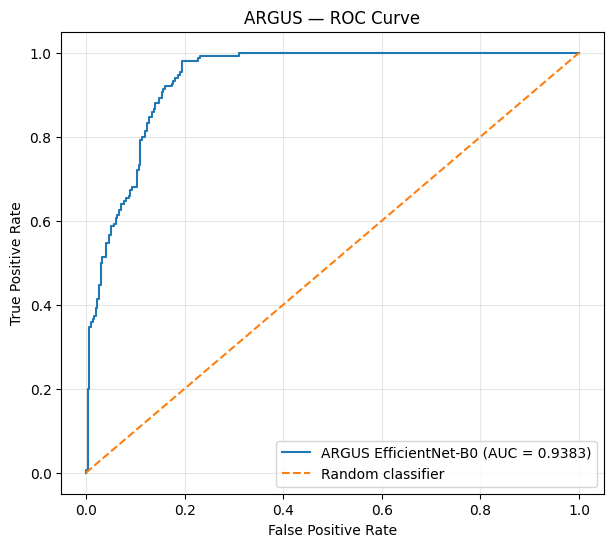

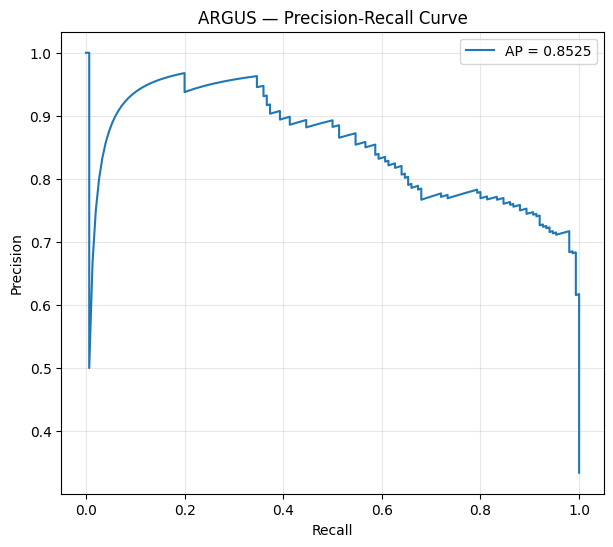

STEP 24 COMPLETE


In [24]:
# ============================================================
# ARGUS.MAIN — BEST MODEL EVALUATION
# ============================================================

import os
import numpy as np
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    f1_score,
    accuracy_score,
    precision_score,
    recall_score
)

print("=" * 70)
print("ARGUS.MAIN — BEST MODEL EVALUATION")
print("=" * 70)

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

BEST_MODEL = "/kaggle/working/ARGUS_DATASET/models/argus_efficientnet_b0_best.pth"

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nCheckpoint:")
print(BEST_MODEL)

print("Device:", DEVICE)

if not os.path.isfile(BEST_MODEL):
    raise FileNotFoundError(
        f"Checkpoint not found:\n{BEST_MODEL}"
    )

# ------------------------------------------------------------
# Load model
# ------------------------------------------------------------

model = model.to(DEVICE)

# PyTorch 2.6+ defaults to weights_only=True.
# Our checkpoint is trusted because it was created by
# the ARGUS training pipeline.
checkpoint = torch.load(
    BEST_MODEL,
    map_location=DEVICE,
    weights_only=False
)

# ------------------------------------------------------------
# Handle checkpoint format
# ------------------------------------------------------------

if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

else:

    model.load_state_dict(
        checkpoint
    )

model.eval()

print("Best model loaded successfully.")

# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------

all_labels = []
all_probs = []
all_preds = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(images)

        # Binary output: [batch] or [batch, 1]
        if outputs.ndim == 1 or outputs.shape[-1] == 1:

            logits = outputs.view(-1)

            probs = torch.sigmoid(logits)

            preds = (
                probs >= 0.5
            ).long()

        # Two-class output: [batch, 2]
        else:

            probabilities = torch.softmax(
                outputs,
                dim=1
            )

            probs = probabilities[:, 1]

            preds = torch.argmax(
                outputs,
                dim=1
            )

        all_labels.extend(
            labels.cpu().numpy()
        )

        all_probs.extend(
            probs.cpu().numpy()
        )

        all_preds.extend(
            preds.cpu().numpy()
        )

# ------------------------------------------------------------
# Convert to NumPy
# ------------------------------------------------------------

y_true = np.asarray(all_labels)
y_prob = np.asarray(all_probs)
y_pred = np.asarray(all_preds)

print("\nSamples evaluated:", len(y_true))

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

accuracy = accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

auc = roc_auc_score(
    y_true,
    y_prob
)

average_precision = average_precision_score(
    y_true,
    y_prob
)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("VALIDATION RESULTS")
print("=" * 70)

print(f"\nAccuracy          : {accuracy:.4f}")
print(f"Precision         : {precision:.4f}")
print(f"Recall            : {recall:.4f}")
print(f"F1 Score          : {f1:.4f}")
print(f"ROC-AUC           : {auc:.4f}")
print(f"Average Precision : {average_precision:.4f}")

# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("CLASSIFICATION REPORT")
print("-" * 70)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "Authentic",
            "Forged"
        ],
        digits=4,
        zero_division=0
    )
)

# ------------------------------------------------------------
# Confusion Matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred
)

print("-" * 70)
print("CONFUSION MATRIX")
print("-" * 70)

print(
    "                 Predicted"
)

print(
    "              Authentic  Forged"
)

print(
    f"Authentic     {cm[0,0]:8d} {cm[0,1]:7d}"
)

print(
    f"Forged        {cm[1,0]:8d} {cm[1,1]:7d}"
)

# ------------------------------------------------------------
# ROC Curve
# ------------------------------------------------------------

fpr, tpr, _ = roc_curve(
    y_true,
    y_prob
)

plt.figure(
    figsize=(7, 6)
)

plt.plot(
    fpr,
    tpr,
    label=f"ARGUS EfficientNet-B0 (AUC = {auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ARGUS — ROC Curve"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

# ------------------------------------------------------------
# Precision-Recall Curve
# ------------------------------------------------------------

pr_precision, pr_recall, _ = precision_recall_curve(
    y_true,
    y_prob
)

plt.figure(
    figsize=(7, 6)
)

plt.plot(
    pr_recall,
    pr_precision,
    label=f"AP = {average_precision:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "ARGUS — Precision-Recall Curve"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

# ------------------------------------------------------------
# Complete
# ------------------------------------------------------------

print("=" * 70)
print("STEP 24 COMPLETE")
print("=" * 70)

In [25]:
# ============================================================
# ARGUS.MAIN — HELD-OUT TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

print("=" * 70)
print("ARGUS.MAIN — CREATING HELD-OUT TEST SET")
print("=" * 70)

SEED = 42
TEST_SIZE = 0.15

# ------------------------------------------------------------
# Start from the original complete metadata
# ------------------------------------------------------------

test_source_df = df.copy()

print("\nTotal records:", len(test_source_df))

# ------------------------------------------------------------
# Create test split
# ------------------------------------------------------------

_, test_df = train_test_split(
    test_source_df,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=test_source_df["label"]
)

test_df = test_df.reset_index(drop=True)

print("Test records:", len(test_df))

# ------------------------------------------------------------
# Test label distribution
# ------------------------------------------------------------

print("\nTEST LABEL DISTRIBUTION")
print(test_df["label"].value_counts())

print("\nTEST PERCENTAGES")
print(
    test_df["label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# ------------------------------------------------------------
# Dataset distribution
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("TEST DATASET DISTRIBUTION")
print("-" * 70)

print(
    test_df["source_dataset"]
    .value_counts()
)

print("\nTEST DATASET × LABEL")

print(
    pd.crosstab(
        test_df["source_dataset"],
        test_df["label"]
    )
)

print("=" * 70)
print("STEP 25 COMPLETE")
print("=" * 70)

ARGUS.MAIN — CREATING HELD-OUT TEST SET

Total records: 2992
Test records: 449

TEST LABEL DISTRIBUTION
label
authentic    299
forged       150
Name: count, dtype: int64

TEST PERCENTAGES
label
authentic    66.59
forged       33.41
Name: proportion, dtype: float64

----------------------------------------------------------------------
TEST DATASET DISTRIBUTION
----------------------------------------------------------------------
source_dataset
CASIA2      286
CEDAR        82
RVL-CDIP     81
Name: count, dtype: int64

TEST DATASET × LABEL
label           authentic  forged
source_dataset                   
CASIA2                136     150
CEDAR                  82       0
RVL-CDIP               81       0
STEP 25 COMPLETE


In [26]:
# ============================================================
# ARGUS.MAIN — TEST DATASET / DATALOADER
# ============================================================

print("=" * 70)
print("ARGUS.MAIN — BUILDING TEST DATA LOADER")
print("=" * 70)

from torch.utils.data import DataLoader

# ------------------------------------------------------------
# Test dataset
# ------------------------------------------------------------

test_dataset = ARGUSDataset(
    test_df,
    transform=val_transform
)

# ------------------------------------------------------------
# Test loader
# ------------------------------------------------------------

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("\nTest dataset size :", len(test_dataset))
print("Test batches      :", len(test_loader))
print("Batch size        : 32")

# ------------------------------------------------------------
# Verify first batch
# ------------------------------------------------------------

images, labels = next(iter(test_loader))

print("\nFirst batch:")
print("Images shape :", images.shape)
print("Images type  :", images.dtype)
print("Labels shape :", labels.shape)
print("Labels       :", labels.tolist())

print("\nBatch label counts:")
print("Authentic :", int((labels == 0).sum()))
print("Forged    :", int((labels == 1).sum()))

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

print("\nGPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("=" * 70)
print("STEP 26 COMPLETE")
print("=" * 70)

ARGUS.MAIN — BUILDING TEST DATA LOADER

Test dataset size : 449
Test batches      : 15
Batch size        : 32

First batch:
Images shape : torch.Size([32, 3, 224, 224])
Images type  : torch.float32
Labels shape : torch.Size([32])
Labels       : [0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0]

Batch label counts:
Authentic : 21
Forged    : 11

GPU available: True
GPU: Tesla T4
STEP 26 COMPLETE


In [28]:
# ============================================================
# ARGUS.MAIN — FINAL HELD-OUT TEST EVALUATION
# STEP 27
# ============================================================

import os
import torch
import torch.nn as nn
import numpy as np

from torchvision import models
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

print("=" * 70)
print("ARGUS.MAIN — FINAL HELD-OUT TEST EVALUATION")
print("=" * 70)

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

BEST_MODEL = (
    "/kaggle/working/ARGUS_DATASET/models/"
    "argus_efficientnet_b0_best.pth"
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print()
print("Checkpoint:", BEST_MODEL)
print("Device:", DEVICE)

if not os.path.isfile(BEST_MODEL):
    raise FileNotFoundError(
        f"Best model not found:\n{BEST_MODEL}"
    )

# ------------------------------------------------------------
# RECREATE MODEL
# ------------------------------------------------------------

def create_model():

    model = models.efficientnet_b0(
        weights=None
    )

    # Same classifier structure used during training
    in_features = model.classifier[1].in_features

    model.classifier[1] = nn.Linear(
        in_features,
        2
    )

    return model


model = create_model()
model = model.to(DEVICE)

# ------------------------------------------------------------
# LOAD CHECKPOINT
# ------------------------------------------------------------

checkpoint = torch.load(
    BEST_MODEL,
    map_location=DEVICE,
    weights_only=False
)

# Support both checkpoint formats:
# 1. {"model_state_dict": ...}
# 2. direct state_dict

if isinstance(checkpoint, dict):

    if "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]

    elif "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]

    else:
        state_dict = checkpoint

else:
    raise RuntimeError(
        "Unsupported checkpoint format."
    )

model.load_state_dict(state_dict)

model.eval()

print()
print("Best model loaded successfully.")

# ------------------------------------------------------------
# FINAL TEST EVALUATION
# ------------------------------------------------------------

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(images)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        # Probability of FORGED class
        all_probabilities.extend(
            probabilities[:, 1].cpu().numpy()
        )


y_true = np.asarray(all_labels)
y_pred = np.asarray(all_predictions)
y_prob = np.asarray(all_probabilities)

# ------------------------------------------------------------
# METRICS
# ------------------------------------------------------------

accuracy = accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_true,
    y_prob
)

average_precision = average_precision_score(
    y_true,
    y_prob
)

# ------------------------------------------------------------
# RESULTS
# ------------------------------------------------------------

print()
print("Samples evaluated:", len(y_true))

print()
print("=" * 70)
print("FINAL HELD-OUT TEST RESULTS")
print("=" * 70)

print()
print(f"Accuracy          : {accuracy:.4f}")
print(f"Precision         : {precision:.4f}")
print(f"Recall            : {recall:.4f}")
print(f"F1 Score          : {f1:.4f}")
print(f"ROC-AUC           : {roc_auc:.4f}")
print(f"Average Precision : {average_precision:.4f}")

# ------------------------------------------------------------
# CLASSIFICATION REPORT
# ------------------------------------------------------------

print()
print("-" * 70)
print("CLASSIFICATION REPORT")
print("-" * 70)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "Authentic",
            "Forged"
        ],
        digits=4,
        zero_division=0
    )
)

# ------------------------------------------------------------
# CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred
)

print("-" * 70)
print("CONFUSION MATRIX")
print("-" * 70)

print(
    f"""
                 Predicted
              Authentic  Forged
Authentic     {cm[0,0]:9d} {cm[0,1]:7d}
Forged        {cm[1,0]:9d} {cm[1,1]:7d}
"""
)

print("=" * 70)
print("STEP 27 COMPLETE")
print("=" * 70)

ARGUS.MAIN — FINAL HELD-OUT TEST EVALUATION

Checkpoint: /kaggle/working/ARGUS_DATASET/models/argus_efficientnet_b0_best.pth
Device: cuda

Best model loaded successfully.

Samples evaluated: 449

FINAL HELD-OUT TEST RESULTS

Accuracy          : 0.8641
Precision         : 0.7459
Recall            : 0.9000
F1 Score          : 0.8157
ROC-AUC           : 0.9383
Average Precision : 0.8525

----------------------------------------------------------------------
CLASSIFICATION REPORT
----------------------------------------------------------------------
              precision    recall  f1-score   support

   Authentic     0.9440    0.8462    0.8924       299
      Forged     0.7459    0.9000    0.8157       150

    accuracy                         0.8641       449
   macro avg     0.8449    0.8731    0.8541       449
weighted avg     0.8778    0.8641    0.8668       449

----------------------------------------------------------------------
CONFUSION MATRIX
---------------------------------

In [29]:
# ============================================================
# ARGUS.MAIN — TRAIN / VALIDATION / TEST LEAKAGE CHECK
# ============================================================

print("=" * 70)
print("ARGUS.MAIN — DATASET LEAKAGE CHECK")
print("=" * 70)

# ------------------------------------------------------------
# Helper
# ------------------------------------------------------------

def check_overlap(df_a, df_b, name_a, name_b):

    # Prefer sample_id when available
    if "sample_id" in df_a.columns and "sample_id" in df_b.columns:

        a = set(df_a["sample_id"].astype(str))
        b = set(df_b["sample_id"].astype(str))

        overlap = a & b

        print(
            f"{name_a} ↔ {name_b} sample_id overlap: "
            f"{len(overlap)}"
        )

        if overlap:
            print("Example:")
            for x in list(overlap)[:5]:
                print(" ", x)

        return len(overlap)

    # Otherwise use image_path
    a = set(df_a["image_path"].astype(str))
    b = set(df_b["image_path"].astype(str))

    overlap = a & b

    print(
        f"{name_a} ↔ {name_b} image_path overlap: "
        f"{len(overlap)}"
    )

    if overlap:
        print("Example:")
        for x in list(overlap)[:5]:
            print(" ", x)

    return len(overlap)


# ------------------------------------------------------------
# Check all splits
# ------------------------------------------------------------

train_val_overlap = check_overlap(
    train_df,
    val_df,
    "TRAIN",
    "VALIDATION"
)

train_test_overlap = check_overlap(
    train_df,
    test_df,
    "TRAIN",
    "TEST"
)

val_test_overlap = check_overlap(
    val_df,
    test_df,
    "VALIDATION",
    "TEST"
)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("LEAKAGE SUMMARY")
print("-" * 70)

print(
    "Train ↔ Validation :", train_val_overlap
)

print(
    "Train ↔ Test       :", train_test_overlap
)

print(
    "Validation ↔ Test  :", val_test_overlap
)

if (
    train_val_overlap == 0
    and train_test_overlap == 0
    and val_test_overlap == 0
):
    print("\n✅ NO DATA OVERLAP DETECTED")

else:
    print("\n⚠️ DATA OVERLAP DETECTED")
    print(
        "The test results should not yet be treated "
        "as independent."
    )

print("=" * 70)
print("STEP 28 COMPLETE")
print("=" * 70)

ARGUS.MAIN — DATASET LEAKAGE CHECK
TRAIN ↔ VALIDATION sample_id overlap: 0
TRAIN ↔ TEST sample_id overlap: 0
VALIDATION ↔ TEST sample_id overlap: 449
Example:
  CASIA2_Tp_S_NNN_S_N_nat20024_nat20024_02224.tif
  CASIA2_Au_arc_30619.jpg
  RVLCDIP_265.png
  CASIA2_Au_sec_30089.jpg
  CASIA2_Tp_D_NRN_S_N_arc00059_cha00063_11825.jpg

----------------------------------------------------------------------
LEAKAGE SUMMARY
----------------------------------------------------------------------
Train ↔ Validation : 0
Train ↔ Test       : 0
Validation ↔ Test  : 449

⚠️ DATA OVERLAP DETECTED
The test results should not yet be treated as independent.
STEP 28 COMPLETE


In [30]:
# ============================================================
# ARGUS.MAIN — CORRECTED TRAIN / VALIDATION / TEST SPLIT
# STEP 29
# ============================================================

from sklearn.model_selection import train_test_split

print("=" * 70)
print("ARGUS.MAIN — CREATING CORRECTED DATA SPLITS")
print("=" * 70)

SEED = 42
TEST_SIZE = 0.15
VAL_SIZE = 0.15

# ------------------------------------------------------------
# Start from the complete dataset
# ------------------------------------------------------------

full_df = df.copy().reset_index(drop=True)

print("\nTotal records:", len(full_df))

# ------------------------------------------------------------
# FIRST: create completely independent TEST set
# ------------------------------------------------------------

development_df, test_df = train_test_split(
    full_df,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=full_df["label"]
)

development_df = development_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# ------------------------------------------------------------
# SECOND: split remaining data into TRAIN + VALIDATION
# ------------------------------------------------------------

train_df, val_df = train_test_split(
    development_df,
    test_size=VAL_SIZE,
    random_state=SEED,
    stratify=development_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

# ------------------------------------------------------------
# Basic sizes
# ------------------------------------------------------------

print("\nSPLIT SIZES")
print("-" * 70)

print("Total       :", len(full_df))
print("Train       :", len(train_df))
print("Validation  :", len(val_df))
print("Test        :", len(test_df))

# ------------------------------------------------------------
# Label distributions
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("TRAIN LABELS")
print("-" * 70)

print(train_df["label"].value_counts())

print("\n" + "-" * 70)
print("VALIDATION LABELS")
print("-" * 70)

print(val_df["label"].value_counts())

print("\n" + "-" * 70)
print("TEST LABELS")
print("-" * 70)

print(test_df["label"].value_counts())

# ------------------------------------------------------------
# Dataset distribution
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("TEST DATASET DISTRIBUTION")
print("-" * 70)

print(
    test_df["source_dataset"].value_counts()
)

print("\nTEST DATASET × LABEL")

print(
    pd.crosstab(
        test_df["source_dataset"],
        test_df["label"]
    )
)

# ------------------------------------------------------------
# FINAL OVERLAP CHECK
# ------------------------------------------------------------

def get_ids(data):

    if "sample_id" in data.columns:
        return set(
            data["sample_id"].astype(str)
        )

    return set(
        data["image_path"].astype(str)
    )


train_ids = get_ids(train_df)
val_ids = get_ids(val_df)
test_ids = get_ids(test_df)

train_val = train_ids & val_ids
train_test = train_ids & test_ids
val_test = val_ids & test_ids

print("\n" + "=" * 70)
print("FINAL OVERLAP CHECK")
print("=" * 70)

print("Train ↔ Validation :", len(train_val))
print("Train ↔ Test       :", len(train_test))
print("Validation ↔ Test  :", len(val_test))

if (
    len(train_val) == 0
    and len(train_test) == 0
    and len(val_test) == 0
):
    print("\n✅ ALL SPLITS ARE COMPLETELY INDEPENDENT")

else:
    raise RuntimeError(
        "DATA LEAKAGE DETECTED — splits overlap."
    )

print("=" * 70)
print("STEP 29 COMPLETE")
print("=" * 70)

ARGUS.MAIN — CREATING CORRECTED DATA SPLITS

Total records: 2992

SPLIT SIZES
----------------------------------------------------------------------
Total       : 2992
Train       : 2161
Validation  : 382
Test        : 449

----------------------------------------------------------------------
TRAIN LABELS
----------------------------------------------------------------------
label
authentic    1439
forged        722
Name: count, dtype: int64

----------------------------------------------------------------------
VALIDATION LABELS
----------------------------------------------------------------------
label
authentic    254
forged       128
Name: count, dtype: int64

----------------------------------------------------------------------
TEST LABELS
----------------------------------------------------------------------
label
authentic    299
forged       150
Name: count, dtype: int64

----------------------------------------------------------------------
TEST DATASET DISTRIBUTION
-------

In [31]:
# ============================================================
# ARGUS.MAIN — CORRECTED DATA LOADERS
# STEP 30
# ============================================================

import torch
from torch.utils.data import DataLoader

print("=" * 70)
print("ARGUS.MAIN — BUILDING CORRECTED DATA LOADERS")
print("=" * 70)

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

BATCH_SIZE = 32

NUM_WORKERS = 0

PIN_MEMORY = torch.cuda.is_available()

# ------------------------------------------------------------
# Create datasets
# ------------------------------------------------------------

train_dataset = ARGUSDataset(
    train_df,
    transform=train_transform
)

val_dataset = ARGUSDataset(
    val_df,
    transform=val_transform
)

test_dataset = ARGUSDataset(
    test_df,
    transform=val_transform
)

# ------------------------------------------------------------
# Create loaders
# ------------------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("\nDATASET SIZES")
print("-" * 70)

print("Train      :", len(train_dataset))
print("Validation :", len(val_dataset))
print("Test       :", len(test_dataset))

print("\nDATALOADER BATCHES")
print("-" * 70)

print("Train      :", len(train_loader))
print("Validation :", len(val_loader))
print("Test       :", len(test_loader))

# ------------------------------------------------------------
# Test one training batch
# ------------------------------------------------------------

images, labels = next(iter(train_loader))

print("\nTRAIN BATCH CHECK")
print("-" * 70)

print("Images shape :", images.shape)
print("Images type  :", images.dtype)
print("Labels shape :", labels.shape)

print(
    "Authentic    :",
    int((labels == 0).sum())
)

print(
    "Forged       :",
    int((labels == 1).sum())
)

# ------------------------------------------------------------
# GPU
# ------------------------------------------------------------

print("\nGPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

print("=" * 70)
print("STEP 30 COMPLETE")
print("=" * 70)

ARGUS.MAIN — BUILDING CORRECTED DATA LOADERS

DATASET SIZES
----------------------------------------------------------------------
Train      : 2161
Validation : 382
Test       : 449

DATALOADER BATCHES
----------------------------------------------------------------------
Train      : 68
Validation : 12
Test       : 15

TRAIN BATCH CHECK
----------------------------------------------------------------------
Images shape : torch.Size([32, 3, 224, 224])
Images type  : torch.float32
Labels shape : torch.Size([32])
Authentic    : 17
Forged       : 15

GPU available: True
GPU: Tesla T4
STEP 30 COMPLETE


In [32]:
# ============================================================
# ARGUS.MAIN — CORRECTED MODEL TRAINING
# STEP 31
# ============================================================

import os
import time
import copy
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("=" * 70)
print("ARGUS.MAIN — TRAINING ON CORRECTED SPLITS")
print("=" * 70)

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

SEED = 42
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

EPOCHS = 15
LR = 1e-4
WEIGHT_DECAY = 1e-4

# ------------------------------------------------------------
# Class weights from CORRECTED training set
# ------------------------------------------------------------

authentic_count = int((train_df["label"] == "authentic").sum())
forged_count = int((train_df["label"] == "forged").sum())

total = authentic_count + forged_count

weight_authentic = total / (2 * authentic_count)
weight_forged = total / (2 * forged_count)

CLASS_WEIGHTS = torch.tensor(
    [weight_authentic, weight_forged],
    dtype=torch.float32,
    device=DEVICE
)

print("\nTRAINING CONFIGURATION")
print("-" * 70)

print("Device       :", DEVICE)
if torch.cuda.is_available():
    print("GPU          :", torch.cuda.get_device_name(0))

print("Epochs       :", EPOCHS)
print("Learning rate:", LR)
print("Weight decay :", WEIGHT_DECAY)

print("\nCorrected training counts:")
print("Authentic    :", authentic_count)
print("Forged       :", forged_count)

print("\nClass weights:")
print(f"Authentic    : {weight_authentic:.4f}")
print(f"Forged       : {weight_forged:.4f}")

# ------------------------------------------------------------
# Model
# ------------------------------------------------------------

def create_model():
    model = models.efficientnet_b0(
        weights=models.EfficientNet_B0_Weights.DEFAULT
    )

    in_features = model.classifier[1].in_features

    model.classifier[1] = nn.Linear(
        in_features,
        2
    )

    return model


model = create_model()
model = model.to(DEVICE)

# ------------------------------------------------------------
# Loss / optimizer / scheduler
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss(
    weight=CLASS_WEIGHTS
)

optimizer = optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

# ------------------------------------------------------------
# Output directory
# ------------------------------------------------------------

MODEL_DIR = "/kaggle/working/ARGUS_DATASET/models"
os.makedirs(MODEL_DIR, exist_ok=True)

BEST_MODEL = os.path.join(
    MODEL_DIR,
    "argus_efficientnet_b0_corrected_best.pth"
)

# ------------------------------------------------------------
# Tracking
# ------------------------------------------------------------

best_f1 = -1.0
best_epoch = 0

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "val_precision": [],
    "val_recall": [],
    "val_f1": [],
    "val_auc": [],
    "lr": []
}

# ------------------------------------------------------------
# Training
# ------------------------------------------------------------

for epoch in range(1, EPOCHS + 1):

    epoch_start = time.time()

    # ========================================================
    # TRAIN
    # ========================================================

    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch:02d}/{EPOCHS} [TRAIN]",
        leave=True
    )

    for images, labels in train_bar:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        batch_size = labels.size(0)

        train_loss += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += batch_size

        train_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss /= train_total
    train_acc = train_correct / train_total

    # ========================================================
    # VALIDATION
    # ========================================================

    model.eval()

    val_loss = 0.0
    val_total = 0

    val_predictions = []
    val_labels = []
    val_probabilities = []

    val_bar = tqdm(
        val_loader,
        desc=f"Epoch {epoch:02d}/{EPOCHS} [VAL]",
        leave=True
    )

    with torch.no_grad():

        for images, labels in val_bar:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            probabilities = torch.softmax(
                outputs,
                dim=1
            )

            predictions = outputs.argmax(
                dim=1
            )

            batch_size = labels.size(0)

            val_loss += (
                loss.item() * batch_size
            )

            val_total += batch_size

            val_predictions.extend(
                predictions.cpu().numpy()
            )

            val_labels.extend(
                labels.cpu().numpy()
            )

            val_probabilities.extend(
                probabilities[:, 1].cpu().numpy()
            )

            val_bar.set_postfix(
                loss=f"{loss.item():.4f}"
            )

    val_loss /= val_total

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    val_acc = accuracy_score(
        val_labels,
        val_predictions
    )

    val_precision = precision_score(
        val_labels,
        val_predictions,
        zero_division=0
    )

    val_recall = recall_score(
        val_labels,
        val_predictions,
        zero_division=0
    )

    val_f1 = f1_score(
        val_labels,
        val_predictions,
        zero_division=0
    )

    try:
        val_auc = roc_auc_score(
            val_labels,
            val_probabilities
        )
    except ValueError:
        val_auc = float("nan")

    current_lr = optimizer.param_groups[0]["lr"]

    scheduler.step(val_loss)

    epoch_time = time.time() - epoch_start

    # --------------------------------------------------------
    # Save history
    # --------------------------------------------------------

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)

    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["val_precision"].append(val_precision)
    history["val_recall"].append(val_recall)
    history["val_f1"].append(val_f1)
    history["val_auc"].append(val_auc)
    history["lr"].append(current_lr)

    # --------------------------------------------------------
    # Best model
    # --------------------------------------------------------

    is_best = val_f1 > best_f1

    if is_best:

        best_f1 = val_f1
        best_epoch = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_f1": val_f1,
                "val_auc": val_auc,
                "val_loss": val_loss,
                "class_weights": CLASS_WEIGHTS.cpu(),
                "seed": SEED
            },
            BEST_MODEL
        )

    # --------------------------------------------------------
    # Epoch summary
    # --------------------------------------------------------

    marker = " ★ BEST" if is_best else ""

    print(
        f"\nEpoch {epoch:02d}/{EPOCHS} | "
        f"{epoch_time:.1f}s"
    )

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f}"
    )

    print(
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    print(
        f"Val Precision: {val_precision:.4f} | "
        f"Val Recall: {val_recall:.4f}"
    )

    print(
        f"Val F1: {val_f1:.4f} | "
        f"Val AUC: {val_auc:.4f} | "
        f"LR: {current_lr:.2e}"
        f"{marker}"
    )

# ============================================================
# COMPLETE
# ============================================================

print("\n" + "=" * 70)
print("CORRECTED TRAINING COMPLETE")
print("=" * 70)

print(f"\nBest validation F1 : {best_f1:.4f}")
print(f"Best epoch         : {best_epoch}")

print("\nBest model:")
print(BEST_MODEL)

print("\nIMPORTANT:")
print("The held-out test set was NOT used during training.")

print("=" * 70)
print("STEP 31 COMPLETE")
print("=" * 70)

ARGUS.MAIN — TRAINING ON CORRECTED SPLITS

TRAINING CONFIGURATION
----------------------------------------------------------------------
Device       : cuda
GPU          : Tesla T4
Epochs       : 15
Learning rate: 0.0001
Weight decay : 0.0001

Corrected training counts:
Authentic    : 1439
Forged       : 722

Class weights:
Authentic    : 0.7509
Forged       : 1.4965


Epoch 01/15 [TRAIN]:   0%|          | 0/68 [00:00<?, ?it/s]

Epoch 01/15 [VAL]:   0%|          | 0/12 [00:00<?, ?it/s]


Epoch 01/15 | 30.0s
Train Loss: 0.5241 | Train Acc: 0.6807
Val Loss: 0.4351 | Val Acc: 0.7225
Val Precision: 0.5500 | Val Recall: 0.9453
Val F1: 0.6954 | Val AUC: 0.8724 | LR: 1.00e-04 ★ BEST


Epoch 02/15 [TRAIN]:   0%|          | 0/68 [00:00<?, ?it/s]

...

Epoch 14/15 [VAL]:   0%|          | 0/12 [00:00<?, ?it/s]


Epoch 14/15 | 27.9s
Train Loss: 0.0582 | Train Acc: 0.9783
Val Loss: 0.4911 | Val Acc: 0.7853
Val Precision: 0.6474 | Val Recall: 0.7891
Val F1: 0.7113 | Val AUC: 0.9069 | LR: 1.25e-05


Epoch 15/15 [TRAIN]:   0%|          | 0/68 [00:00<?, ?it/s]

Epoch 15/15 [VAL]:   0%|          | 0/12 [00:00<?, ?it/s]


Epoch 15/15 | 28.1s
Train Loss: 0.0618 | Train Acc: 0.9764
Val Loss: 0.5018 | Val Acc: 0.7906
Val Precision: 0.6519 | Val Recall: 0.8047
Val F1: 0.7203 | Val AUC: 0.9042 | LR: 1.25e-05

CORRECTED TRAINING COMPLETE

Best validation F1 : 0.7536
Best epoch         : 9

Best model:
/kaggle/working/ARGUS_DATASET/models/argus_efficientnet_b0_corrected_best.pth

IMPORTANT:
The held-out test set was NOT used during training.
STEP 31 COMPLETE


In [33]:
# ============================================================
# ARGUS.MAIN — INDEPENDENT HELD-OUT TEST EVALUATION
# STEP 32
# ============================================================

import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

print("=" * 70)
print("ARGUS.MAIN — INDEPENDENT HELD-OUT TEST EVALUATION")
print("=" * 70)

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

BEST_MODEL = (
    "/kaggle/working/ARGUS_DATASET/models/"
    "argus_efficientnet_b0_corrected_best.pth"
)

print("\nCheckpoint:", BEST_MODEL)
print("Device:", DEVICE)

# ------------------------------------------------------------
# Create model
# ------------------------------------------------------------

model = create_model()
model = model.to(DEVICE)

# ------------------------------------------------------------
# Load corrected best checkpoint
# ------------------------------------------------------------

checkpoint = torch.load(
    BEST_MODEL,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Best corrected model loaded successfully.")
print("Best epoch:", checkpoint.get("epoch"))
print(
    "Validation F1:",
    f"{checkpoint.get('val_f1', 0):.4f}"
)

# ------------------------------------------------------------
# Test evaluation
# ------------------------------------------------------------

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        outputs = model(images)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = outputs.argmax(
            dim=1
        )

        all_labels.extend(
            labels.numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_probabilities.extend(
            probabilities[:, 1]
            .cpu()
            .numpy()
        )

# ------------------------------------------------------------
# Convert to arrays
# ------------------------------------------------------------

y_true = np.asarray(all_labels)
y_pred = np.asarray(all_predictions)
y_prob = np.asarray(all_probabilities)

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

accuracy = accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_true,
    y_prob
)

average_precision = average_precision_score(
    y_true,
    y_prob
)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\nSamples evaluated:", len(y_true))

print("\n" + "=" * 70)
print("FINAL INDEPENDENT TEST RESULTS")
print("=" * 70)

print(f"\nAccuracy          : {accuracy:.4f}")
print(f"Precision         : {precision:.4f}")
print(f"Recall            : {recall:.4f}")
print(f"F1 Score          : {f1:.4f}")
print(f"ROC-AUC           : {roc_auc:.4f}")
print(f"Average Precision : {average_precision:.4f}")

# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("CLASSIFICATION REPORT")
print("-" * 70)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "Authentic",
            "Forged"
        ],
        digits=4,
        zero_division=0
    )
)

# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred
)

print("-" * 70)
print("CONFUSION MATRIX")
print("-" * 70)

print(
    "\n                 Predicted"
)

print(
    "              Authentic  Forged"
)

print(
    f"Authentic    {cm[0,0]:9d} {cm[0,1]:7d}"
)

print(
    f"Forged       {cm[1,0]:9d} {cm[1,1]:7d}"
)

# ------------------------------------------------------------
# Final safety check
# ------------------------------------------------------------

assert len(y_true) == len(test_df)

print("\n" + "=" * 70)
print("STEP 32 COMPLETE")
print("=" * 70)

ARGUS.MAIN — INDEPENDENT HELD-OUT TEST EVALUATION

Checkpoint: /kaggle/working/ARGUS_DATASET/models/argus_efficientnet_b0_corrected_best.pth
Device: cuda
Best corrected model loaded successfully.
Best epoch: 9
Validation F1: 0.7536

Samples evaluated: 449

FINAL INDEPENDENT TEST RESULTS

Accuracy          : 0.8419
Precision         : 0.7453
Recall            : 0.8000
F1 Score          : 0.7717
ROC-AUC           : 0.9020
Average Precision : 0.7970

----------------------------------------------------------------------
CLASSIFICATION REPORT
----------------------------------------------------------------------
              precision    recall  f1-score   support

   Authentic     0.8958    0.8629    0.8790       299
      Forged     0.7453    0.8000    0.7717       150

    accuracy                         0.8419       449
   macro avg     0.8206    0.8314    0.8254       449
weighted avg     0.8456    0.8419    0.8432       449

---------------------------------------------------------

In [34]:
# ============================================================
# ARGUS.MAIN — DATASET-WISE ERROR ANALYSIS
# STEP 33
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

print("=" * 70)
print("ARGUS.MAIN — DATASET-WISE ERROR ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# Build result dataframe
# ------------------------------------------------------------

results_df = test_df.copy().reset_index(drop=True)

results_df["y_true"] = y_true
results_df["y_pred"] = y_pred
results_df["forged_probability"] = y_prob

results_df["correct"] = (
    results_df["y_true"] ==
    results_df["y_pred"]
)

results_df["error"] = (
    ~results_df["correct"]
)

# ------------------------------------------------------------
# Human-readable labels
# ------------------------------------------------------------

results_df["true_label"] = results_df["y_true"].map({
    0: "authentic",
    1: "forged"
})

results_df["predicted_label"] = results_df["y_pred"].map({
    0: "authentic",
    1: "forged"
})

# ------------------------------------------------------------
# Dataset distribution
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("TEST DATASET DISTRIBUTION")
print("-" * 70)

print(
    results_df["source_dataset"]
    .value_counts()
)

# ------------------------------------------------------------
# Dataset × label
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("DATASET × TRUE LABEL")
print("-" * 70)

print(
    pd.crosstab(
        results_df["source_dataset"],
        results_df["true_label"]
    )
)

# ------------------------------------------------------------
# Per-dataset metrics
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PER-DATASET PERFORMANCE")
print("=" * 70)

for dataset_name in sorted(
    results_df["source_dataset"].dropna().unique()
):

    subset = results_df[
        results_df["source_dataset"] ==
        dataset_name
    ]

    yt = subset["y_true"].values
    yp = subset["y_pred"].values
    yp_prob = subset["forged_probability"].values

    print("\n" + "-" * 70)
    print(dataset_name)
    print("-" * 70)

    print("Samples   :", len(subset))
    print(
        "Correct   :",
        int(subset["correct"].sum())
    )
    print(
        "Errors    :",
        int(subset["error"].sum())
    )

    print(
        "Accuracy  :",
        f"{accuracy_score(yt, yp):.4f}"
    )

    # Metrics requiring both classes
    if len(np.unique(yt)) == 2:

        precision = precision_score(
            yt,
            yp,
            zero_division=0
        )

        recall = recall_score(
            yt,
            yp,
            zero_division=0
        )

        f1 = f1_score(
            yt,
            yp,
            zero_division=0
        )

        auc = roc_auc_score(
            yt,
            yp_prob
        )

        print(
            "Precision :",
            f"{precision:.4f}"
        )

        print(
            "Recall    :",
            f"{recall:.4f}"
        )

        print(
            "F1        :",
            f"{f1:.4f}"
        )

        print(
            "ROC-AUC   :",
            f"{auc:.4f}"
        )

    else:

        print(
            "Note      : only one class present"
        )

    # Confusion matrix
    cm = confusion_matrix(
        yt,
        yp,
        labels=[0, 1]
    )

    print("\nConfusion matrix:")
    print(cm)

# ------------------------------------------------------------
# Global error counts
# ------------------------------------------------------------

false_positives = results_df[
    (results_df["y_true"] == 0) &
    (results_df["y_pred"] == 1)
]

false_negatives = results_df[
    (results_df["y_true"] == 1) &
    (results_df["y_pred"] == 0)
]

true_positives = results_df[
    (results_df["y_true"] == 1) &
    (results_df["y_pred"] == 1)
]

true_negatives = results_df[
    (results_df["y_true"] == 0) &
    (results_df["y_pred"] == 0)
]

print("\n" + "=" * 70)
print("ERROR SUMMARY")
print("=" * 70)

print(
    "True negatives  :",
    len(true_negatives)
)

print(
    "False positives  :",
    len(false_positives)
)

print(
    "False negatives  :",
    len(false_negatives)
)

print(
    "True positives   :",
    len(true_positives)
)

# ------------------------------------------------------------
# Error rate by dataset
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("ERROR RATE BY DATASET")
print("-" * 70)

error_by_dataset = (
    results_df
    .groupby("source_dataset")["error"]
    .agg(
        samples="count",
        errors="sum"
    )
)

error_by_dataset["error_rate"] = (
    error_by_dataset["errors"] /
    error_by_dataset["samples"]
)

error_by_dataset["error_rate"] = (
    error_by_dataset["error_rate"] * 100
).round(2)

print(error_by_dataset)

# ------------------------------------------------------------
# False positives by dataset
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("FALSE POSITIVES BY DATASET")
print("-" * 70)

if len(false_positives) > 0:

    print(
        false_positives[
            "source_dataset"
        ].value_counts()
    )

else:

    print("None")

# ------------------------------------------------------------
# False negatives by dataset
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("FALSE NEGATIVES BY DATASET")
print("-" * 70)

if len(false_negatives) > 0:

    print(
        false_negatives[
            "source_dataset"
        ].value_counts()
    )

else:

    print("None")

# ------------------------------------------------------------
# Most uncertain predictions
# ------------------------------------------------------------

results_df["confidence"] = np.maximum(
    results_df["forged_probability"],
    1 - results_df["forged_probability"]
)

uncertain = (
    results_df
    .sort_values("confidence")
    .head(15)
)

print("\n" + "=" * 70)
print("MOST UNCERTAIN PREDICTIONS")
print("=" * 70)

print(
    uncertain[
        [
            "sample_id",
            "source_dataset",
            "true_label",
            "predicted_label",
            "forged_probability",
            "confidence",
            "correct"
        ]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# Hardest false positives
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STRONGEST FALSE POSITIVES")
print("=" * 70)

if len(false_positives) > 0:

    fp_hard = (
        false_positives
        .sort_values(
            "forged_probability",
            ascending=False
        )
        .head(10)
    )

    print(
        fp_hard[
            [
                "sample_id",
                "source_dataset",
                "true_label",
                "predicted_label",
                "forged_probability"
            ]
        ].to_string(index=False)
    )

else:

    print("None")

# ------------------------------------------------------------
# Hardest false negatives
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STRONGEST FALSE NEGATIVES")
print("=" * 70)

if len(false_negatives) > 0:

    fn_hard = (
        false_negatives
        .sort_values(
            "forged_probability",
            ascending=True
        )
        .head(10)
    )

    print(
        fn_hard[
            [
                "sample_id",
                "source_dataset",
                "true_label",
                "predicted_label",
                "forged_probability"
            ]
        ].to_string(index=False)
    )

else:

    print("None")

# ------------------------------------------------------------
# Save analysis
# ------------------------------------------------------------

ANALYSIS_PATH = (
    "/kaggle/working/ARGUS_DATASET/"
    "test_error_analysis.csv"
)

results_df.to_csv(
    ANALYSIS_PATH,
    index=False
)

print("\n" + "=" * 70)
print("ANALYSIS SAVED")
print("=" * 70)

print(ANALYSIS_PATH)

print("\n" + "=" * 70)
print("STEP 33 COMPLETE")
print("=" * 70)

ARGUS.MAIN — DATASET-WISE ERROR ANALYSIS

----------------------------------------------------------------------
TEST DATASET DISTRIBUTION
----------------------------------------------------------------------
source_dataset
CASIA2      286
CEDAR        82
RVL-CDIP     81
Name: count, dtype: int64

----------------------------------------------------------------------
DATASET × TRUE LABEL
----------------------------------------------------------------------
true_label      authentic  forged
source_dataset                   
CASIA2                136     150
CEDAR                  82       0
RVL-CDIP               81       0

PER-DATASET PERFORMANCE

----------------------------------------------------------------------
CASIA2
----------------------------------------------------------------------
Samples   : 286
Correct   : 215
Errors    : 71
Accuracy  : 0.7517
Precision : 0.7453
Recall    : 0.8000
F1        : 0.7717
ROC-AUC   : 0.8106

Confusion matrix:
[[ 95  41]
 [ 30 120]]

-------

In [35]:
# ============================================================
# ARGUS.MAIN — STEP 34
# DATASET × LABEL AVAILABILITY ANALYSIS
# ============================================================

import os
import pandas as pd

print("=" * 70)
print("ARGUS.MAIN — DATASET × LABEL AVAILABILITY ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# PATH
# ------------------------------------------------------------

MASTER_METADATA = (
    "/kaggle/input/notebooks/aravkataria/argus-dataset/"
    "argus_preprocessed/master_metadata.csv"
)

print("\nLoading:")
print(MASTER_METADATA)

df = pd.read_csv(MASTER_METADATA)

print("\nTotal records:", len(df))
print("Columns:", list(df.columns))

# ------------------------------------------------------------
# BASIC DATASET DISTRIBUTION
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("DATASET DISTRIBUTION")
print("-" * 70)

print(
    df["source_dataset"]
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# DATASET × LABEL
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("DATASET × LABEL")
print("-" * 70)

dataset_label = pd.crosstab(
    df["source_dataset"],
    df["label"]
)

print(dataset_label)

# ------------------------------------------------------------
# PERCENTAGES
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("DATASET LABEL PERCENTAGES")
print("-" * 70)

dataset_percent = pd.crosstab(
    df["source_dataset"],
    df["label"],
    normalize="index"
) * 100

print(dataset_percent.round(2))

# ------------------------------------------------------------
# AUTHENTIC / FORGED COUNTS
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("AUTHENTIC / FORGED AVAILABILITY")
print("-" * 70)

for dataset in sorted(df["source_dataset"].dropna().unique()):

    subset = df[df["source_dataset"] == dataset]

    authentic = (subset["label"] == "authentic").sum()
    forged = (subset["label"] == "forged").sum()

    print(
        f"{dataset:<15} "
        f"Total: {len(subset):<5} "
        f"Authentic: {authentic:<5} "
        f"Forged: {forged:<5}"
    )

# ------------------------------------------------------------
# DATASETS SUITABLE FOR BINARY FORGERY TRAINING
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("DATASETS WITH BOTH CLASSES")
print("-" * 70)

usable_datasets = []

for dataset in sorted(df["source_dataset"].dropna().unique()):

    subset = df[df["source_dataset"] == dataset]

    labels = set(subset["label"].dropna().unique())

    if {"authentic", "forged"}.issubset(labels):
        usable_datasets.append(dataset)

        authentic = (subset["label"] == "authentic").sum()
        forged = (subset["label"] == "forged").sum()

        print(
            f"✅ {dataset:<15} "
            f"Authentic: {authentic:<5} "
            f"Forged: {forged:<5}"
        )

# ------------------------------------------------------------
# AUTHENTIC-ONLY DATASETS
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("AUTHENTIC-ONLY DATASETS")
print("-" * 70)

for dataset in sorted(df["source_dataset"].dropna().unique()):

    subset = df[df["source_dataset"] == dataset]

    labels = set(subset["label"].dropna().unique())

    if labels == {"authentic"}:
        print(
            f"⚠️ {dataset:<15} "
            f"Authentic: {len(subset)}"
        )

# ------------------------------------------------------------
# FORGED-ONLY DATASETS
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("FORGED-ONLY DATASETS")
print("-" * 70)

found_forged_only = False

for dataset in sorted(df["source_dataset"].dropna().unique()):

    subset = df[df["source_dataset"] == dataset]

    labels = set(subset["label"].dropna().unique())

    if labels == {"forged"}:
        found_forged_only = True

        print(
            f"⚠️ {dataset:<15} "
            f"Forged: {len(subset)}"
        )

if not found_forged_only:
    print("None")

# ------------------------------------------------------------
# FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 34 SUMMARY")
print("=" * 70)

print("Total datasets :", df["source_dataset"].nunique())
print("Usable datasets:", len(usable_datasets))

print("\nDatasets with BOTH authentic + forged:")
print(
    usable_datasets
    if usable_datasets
    else "NONE"
)

print("\n" + "=" * 70)
print("STEP 34 COMPLETE")
print("=" * 70)

ARGUS.MAIN — DATASET × LABEL AVAILABILITY ANALYSIS

Loading:
/kaggle/input/notebooks/aravkataria/argus-dataset/argus_preprocessed/master_metadata.csv

Total records: 2992
Columns: ['sample_id', 'image_path', 'mask_path', 'label', 'has_mask', 'source_dataset']

----------------------------------------------------------------------
DATASET DISTRIBUTION
----------------------------------------------------------------------
source_dataset
CASIA2      1993
CEDAR        499
RVL-CDIP     500
Name: count, dtype: int64

----------------------------------------------------------------------
DATASET × LABEL
----------------------------------------------------------------------
label           authentic  forged
source_dataset                   
CASIA2                993    1000
CEDAR                 499       0
RVL-CDIP              500       0

----------------------------------------------------------------------
DATASET LABEL PERCENTAGES
---------------------------------------------------------

In [36]:
# ============================================================
# ARGUS.MAIN — STEP 35
# CASIA2 FORGERY TYPE ANALYSIS
# ============================================================

import pandas as pd
import re

print("=" * 70)
print("ARGUS.MAIN — CASIA2 FORGERY TYPE ANALYSIS")
print("=" * 70)

MASTER_METADATA = (
    "/kaggle/input/notebooks/aravkataria/argus-dataset/"
    "argus_preprocessed/master_metadata.csv"
)

df = pd.read_csv(MASTER_METADATA)

casia = df[
    df["source_dataset"].eq("CASIA2")
].copy()

forged = casia[
    casia["label"].eq("forged")
].copy()

print("\nCASIA2 records :", len(casia))
print("Authentic      :", (casia["label"] == "authentic").sum())
print("Forged         :", len(forged))

# ------------------------------------------------------------
# EXTRACT CASIA2 FILENAME
# ------------------------------------------------------------

forged["filename"] = forged["sample_id"].astype(str)

# ------------------------------------------------------------
# FORGERY PREFIX
# ------------------------------------------------------------

forged["prefix"] = forged["filename"].str.extract(
    r"^(Tp_[A-Za-z])",
    expand=False
)

print("\n" + "-" * 70)
print("FORGERY PREFIX")
print("-" * 70)

print(
    forged["prefix"]
    .value_counts(dropna=False)
)

# ------------------------------------------------------------
# FULL CASIA2 PATTERN
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("COMMON FORGERY PATTERNS")
print("-" * 70)

patterns = (
    forged["filename"]
    .str.extract(
        r"^(Tp_[^_]+_[^_]+_[^_]+)",
        expand=False
    )
)

print(
    patterns
    .value_counts()
    .head(30)
)

# ------------------------------------------------------------
# SOURCE TYPES FROM FILENAME
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("SAMPLE FORGED FILENAMES")
print("-" * 70)

for name in forged["filename"].head(30):
    print(name)

# ------------------------------------------------------------
# MASK AVAILABILITY
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("FORGED MASK AVAILABILITY")
print("-" * 70)

print(
    forged["has_mask"]
    .value_counts(dropna=False)
)

# ------------------------------------------------------------
# OPERATIONS IF AVAILABLE
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("AVAILABLE METADATA COLUMNS")
print("-" * 70)

print(list(df.columns))

print("\n" + "=" * 70)
print("STEP 35 COMPLETE")
print("=" * 70)

ARGUS.MAIN — CASIA2 FORGERY TYPE ANALYSIS

CASIA2 records : 1993
Authentic      : 993
Forged         : 1000

----------------------------------------------------------------------
FORGERY PREFIX
----------------------------------------------------------------------
prefix
NaN    1000
Name: count, dtype: int64

----------------------------------------------------------------------
COMMON FORGERY PATTERNS
----------------------------------------------------------------------
Series([], Name: count, dtype: int64)

----------------------------------------------------------------------
SAMPLE FORGED FILENAMES
----------------------------------------------------------------------
CASIA2_Tp_D_NRN_M_N_nat00025_nat00028_11037.jpg
CASIA2_Tp_S_NND_S_N_arc00012_arc00012_01111.tif
CASIA2_Tp_S_NRN_S_N_art20038_art20038_01844.tif
CASIA2_Tp_S_NRN_S_N_art00092_art00092_11809.jpg
CASIA2_Tp_S_NNN_S_N_txt00060_txt00060_01282.tif
CASIA2_Tp_D_NNN_M_N_arc00061_nat00099_10447.tif
CASIA2_Tp_S_CRN_S_O_art00040_

In [37]:
# ============================================================
# ARGUS.MAIN — STEP 36
# CASIA2 STRUCTURAL FORGERY ANALYSIS
# ============================================================

import pandas as pd
import re

print("=" * 70)
print("ARGUS.MAIN — CASIA2 STRUCTURAL FORGERY ANALYSIS")
print("=" * 70)

MASTER_METADATA = (
    "/kaggle/input/notebooks/aravkataria/argus-dataset/"
    "argus_preprocessed/master_metadata.csv"
)

df = pd.read_csv(MASTER_METADATA)

casia = df[
    df["source_dataset"].eq("CASIA2")
].copy()

forged = casia[
    casia["label"].eq("forged")
].copy()

forged["filename"] = forged["sample_id"].astype(str)

print("\nCASIA2 forged samples:", len(forged))

# ------------------------------------------------------------
# REMOVE DATASET PREFIX
# ------------------------------------------------------------

forged["casia_name"] = (
    forged["filename"]
    .str.replace(r"^CASIA2_", "", regex=True)
)

# ------------------------------------------------------------
# PARSE CASIA2 STRUCTURE
#
# Example:
# Tp_D_NRN_M_N_nat00025_nat00028_11037.jpg
#
# Field 0 = Tp
# Field 1 = D/S
# Field 2 = operation code
# Field 3 = M/S
# Field 4 = condition
# ------------------------------------------------------------

parts = forged["casia_name"].str.split("_")

forged["type"] = parts.str[0]
forged["mode"] = parts.str[1]
forged["operation_code"] = parts.str[2]
forged["source_code"] = parts.str[3]
forged["condition"] = parts.str[4]

# ------------------------------------------------------------
# DISTRIBUTION
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("FORGERY TYPE")
print("-" * 70)

print(
    forged["type"]
    .value_counts(dropna=False)
)

print("\n" + "-" * 70)
print("MODE")
print("-" * 70)

print(
    forged["mode"]
    .value_counts(dropna=False)
)

print("\n" + "-" * 70)
print("OPERATION CODE")
print("-" * 70)

print(
    forged["operation_code"]
    .value_counts(dropna=False)
)

print("\n" + "-" * 70)
print("SOURCE CODE")
print("-" * 70)

print(
    forged["source_code"]
    .value_counts(dropna=False)
)

print("\n" + "-" * 70)
print("CONDITION")
print("-" * 70)

print(
    forged["condition"]
    .value_counts(dropna=False)
)

# ------------------------------------------------------------
# COMBINED PATTERNS
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("MODE × OPERATION")
print("-" * 70)

print(
    pd.crosstab(
        forged["mode"],
        forged["operation_code"]
    )
)

print("\n" + "-" * 70)
print("MODE × SOURCE")
print("-" * 70)

print(
    pd.crosstab(
        forged["mode"],
        forged["source_code"]
    )
)

# ------------------------------------------------------------
# EXAMPLES BY MODE
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("EXAMPLES")
print("-" * 70)

for mode in sorted(forged["mode"].dropna().unique()):

    print(f"\n[{mode}]")

    examples = (
        forged.loc[
            forged["mode"] == mode,
            "filename"
        ]
        .head(8)
        .tolist()
    )

    for example in examples:
        print(" ", example)

# ------------------------------------------------------------
# MASK STATUS
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("MASK AVAILABILITY")
print("-" * 70)

print(
    forged["has_mask"]
    .value_counts(dropna=False)
)

print("\n" + "=" * 70)
print("STEP 36 COMPLETE")
print("=" * 70)

ARGUS.MAIN — CASIA2 STRUCTURAL FORGERY ANALYSIS

CASIA2 forged samples: 1000

----------------------------------------------------------------------
FORGERY TYPE
----------------------------------------------------------------------
type
Tp    1000
Name: count, dtype: int64

----------------------------------------------------------------------
MODE
----------------------------------------------------------------------
mode
S    657
D    343
Name: count, dtype: int64

----------------------------------------------------------------------
OPERATION CODE
----------------------------------------------------------------------
operation_code
NNN    354
NRN    321
CNN    117
CRN    103
NND     42
NRD     35
CRD     18
CND     10
Name: count, dtype: int64

----------------------------------------------------------------------
SOURCE CODE
----------------------------------------------------------------------
source_code
S    774
M    220
L      5
N      1
Name: count, dtype: int64

-----------

ARGUS.MAIN — VISUAL ERROR INSPECTION

Loaded error records: 449
Image directory: /kaggle/input/notebooks/aravkataria/argus-dataset/argus_preprocessed/images
Images available: 449/449

----------------------------------------------------------------------
STRONGEST FALSE POSITIVES
----------------------------------------------------------------------


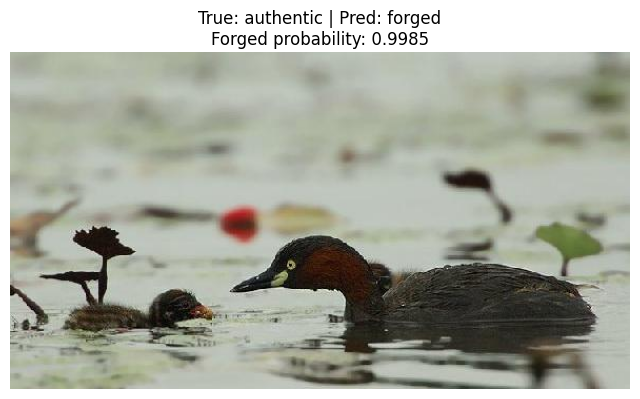

Sample: CASIA2_Au_ani_20070.jpg
Dataset: CASIA2
True: authentic | Predicted: forged
Forged probability: 0.998455


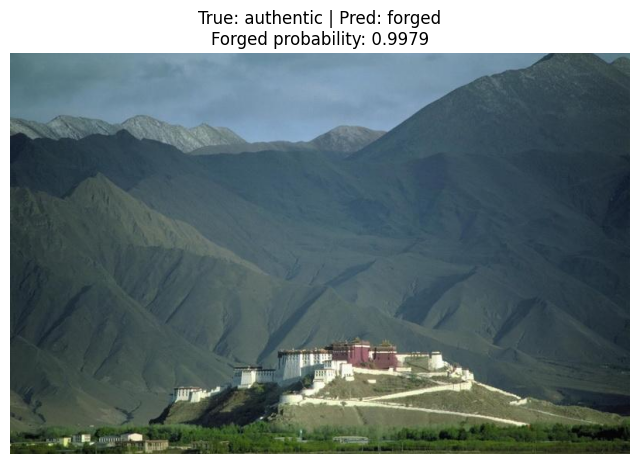

Sample: CASIA2_Au_nat_20032.jpg
Dataset: CASIA2
True: authentic | Predicted: forged
Forged probability: 0.997950


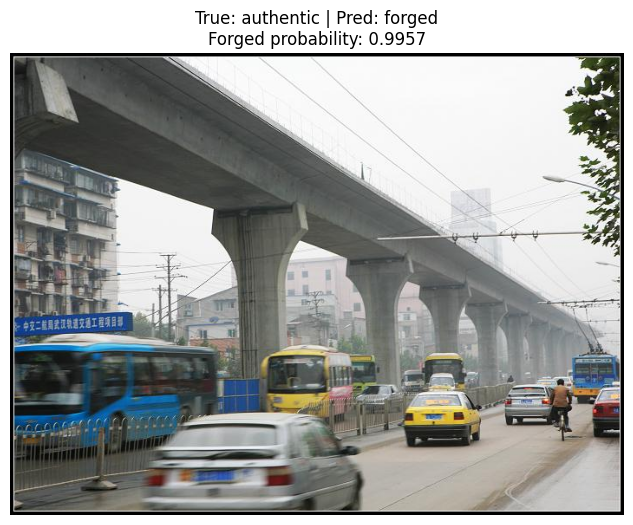

Sample: CASIA2_Au_sec_10002.jpg
Dataset: CASIA2
True: authentic | Predicted: forged
Forged probability: 0.995733


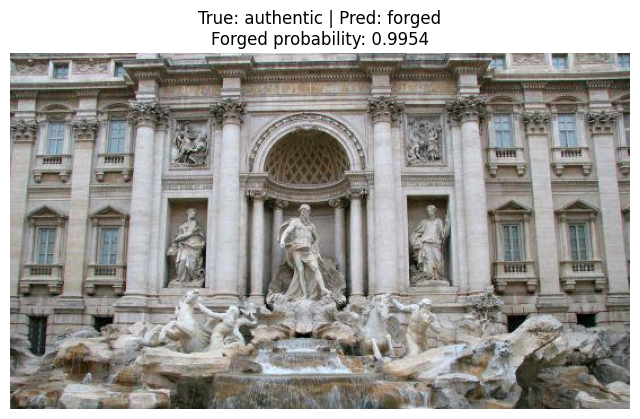

Sample: CASIA2_Au_sec_20057.jpg
Dataset: CASIA2
True: authentic | Predicted: forged
Forged probability: 0.995437


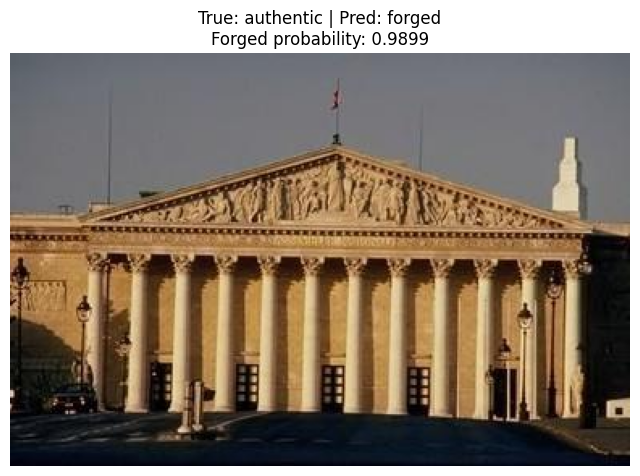

Sample: CASIA2_Au_arc_30619.jpg
Dataset: CASIA2
True: authentic | Predicted: forged
Forged probability: 0.989909


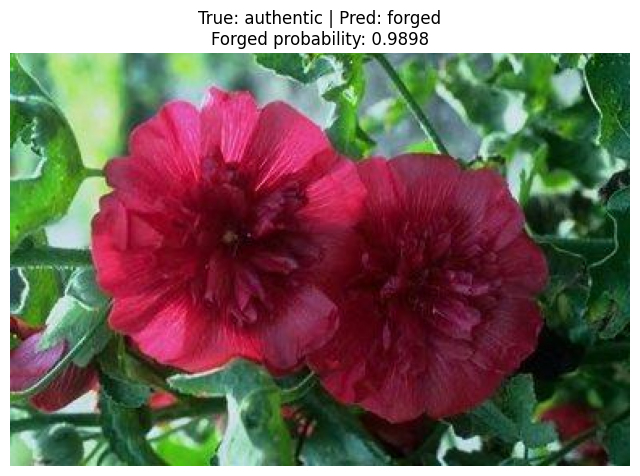

Sample: CASIA2_Au_pla_30293.jpg
Dataset: CASIA2
True: authentic | Predicted: forged
Forged probability: 0.989837

----------------------------------------------------------------------
STRONGEST FALSE NEGATIVES
----------------------------------------------------------------------


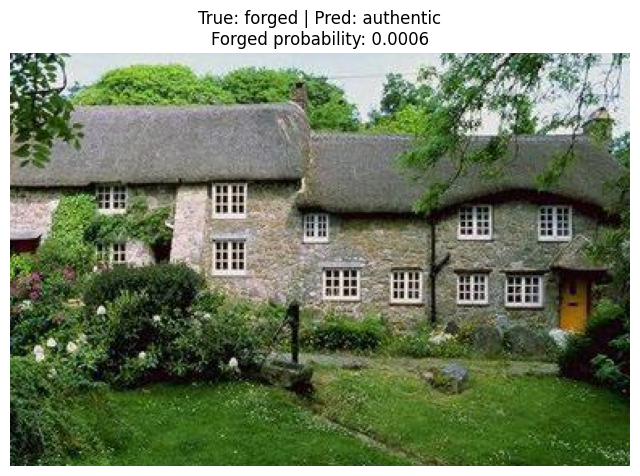

Sample: CASIA2_Tp_S_NNN_S_N_sec00013_sec00013_11228.jpg
Dataset: CASIA2
True: forged | Predicted: authentic
Forged probability: 0.000642


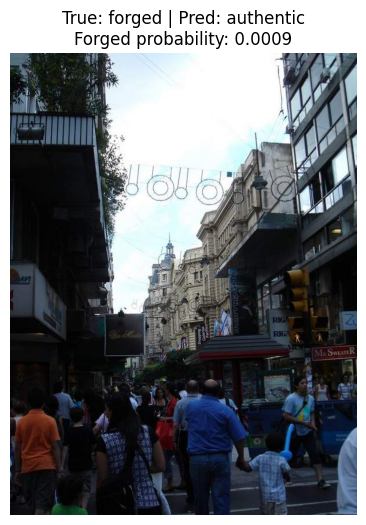

Sample: CASIA2_Tp_S_NNN_S_N_arc20093_arc20093_01733.tif
Dataset: CASIA2
True: forged | Predicted: authentic
Forged probability: 0.000943


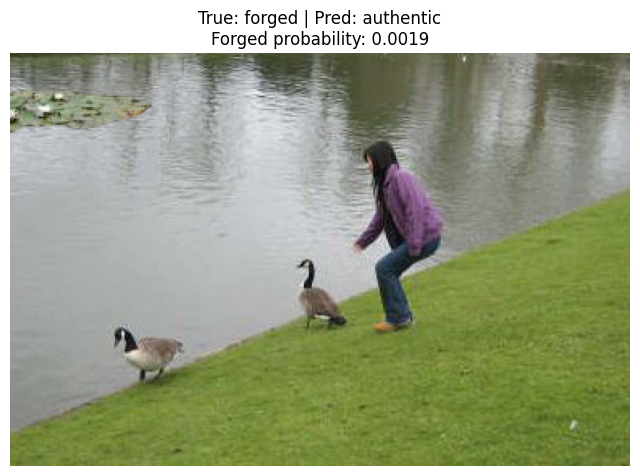

Sample: CASIA2_Tp_D_NNN_S_N_sec00098_sec00082_10364.tif
Dataset: CASIA2
True: forged | Predicted: authentic
Forged probability: 0.001946


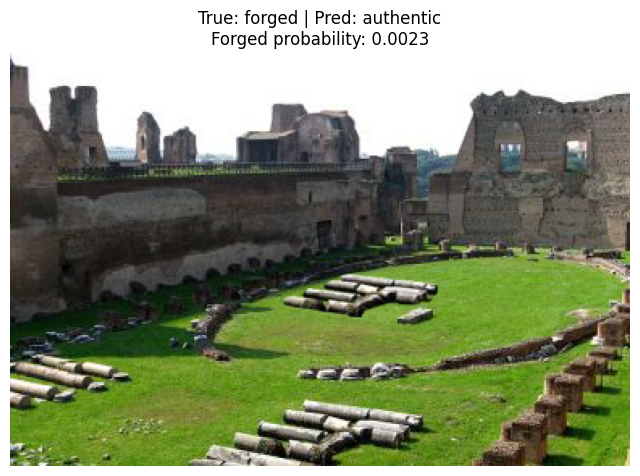

Sample: CASIA2_Tp_S_NRN_S_N_sec00086_sec00086_10359.tif
Dataset: CASIA2
True: forged | Predicted: authentic
Forged probability: 0.002296


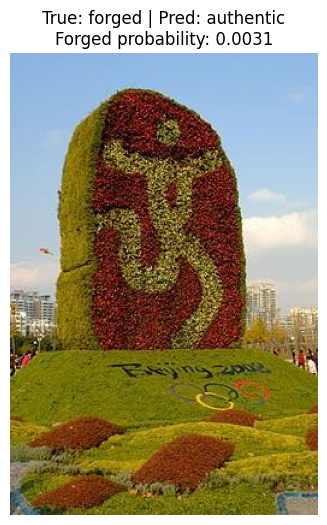

Sample: CASIA2_Tp_S_NNN_S_N_art00059_art00059_01234.tif
Dataset: CASIA2
True: forged | Predicted: authentic
Forged probability: 0.003112


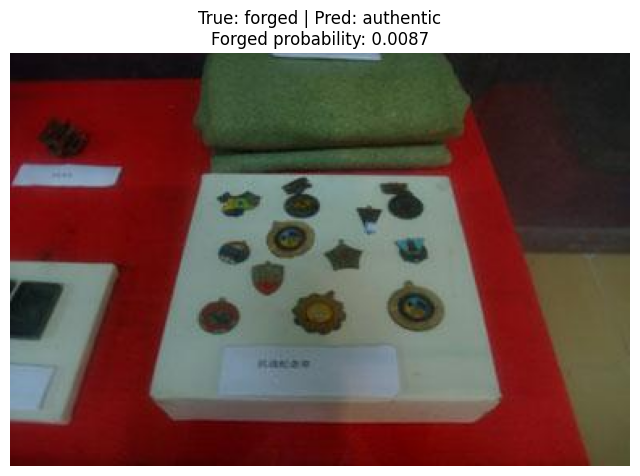

Sample: CASIA2_Tp_S_CRN_S_N_art10109_art10109_11572.jpg
Dataset: CASIA2
True: forged | Predicted: authentic
Forged probability: 0.008734

----------------------------------------------------------------------
MOST UNCERTAIN PREDICTIONS
----------------------------------------------------------------------


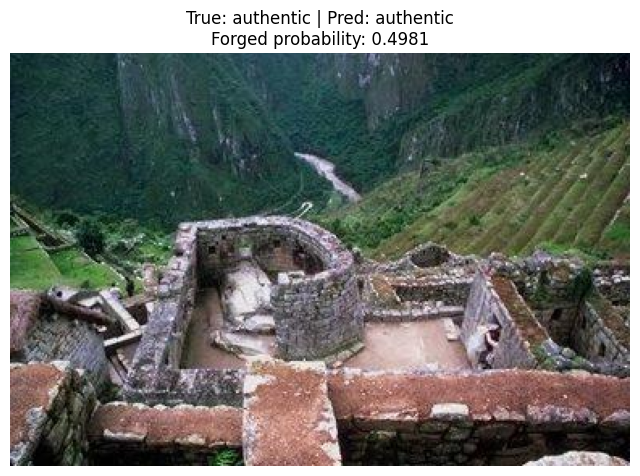

Sample: CASIA2_Au_arc_30254.jpg
Dataset: CASIA2
True: authentic | Predicted: authentic
Forged probability: 0.498095


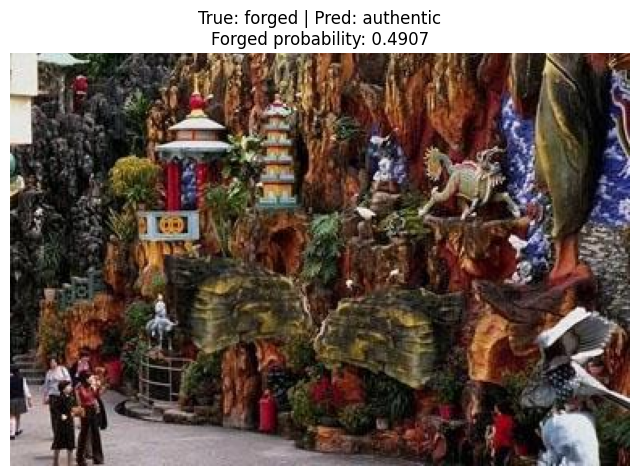

Sample: CASIA2_Tp_S_CNN_S_N_sec00008_sec00008_10800.jpg
Dataset: CASIA2
True: forged | Predicted: authentic
Forged probability: 0.490724


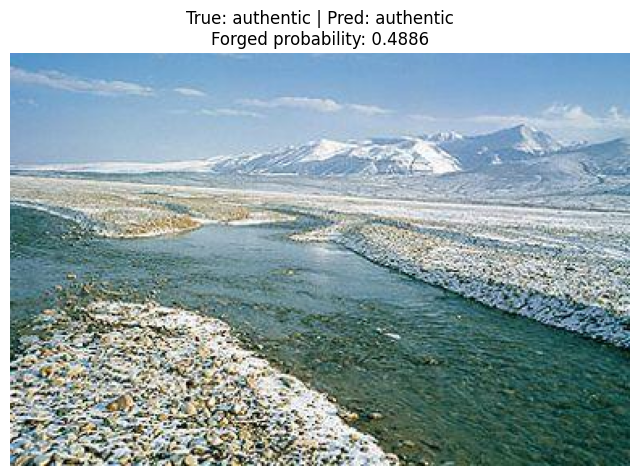

Sample: CASIA2_Au_nat_00075.jpg
Dataset: CASIA2
True: authentic | Predicted: authentic
Forged probability: 0.488588


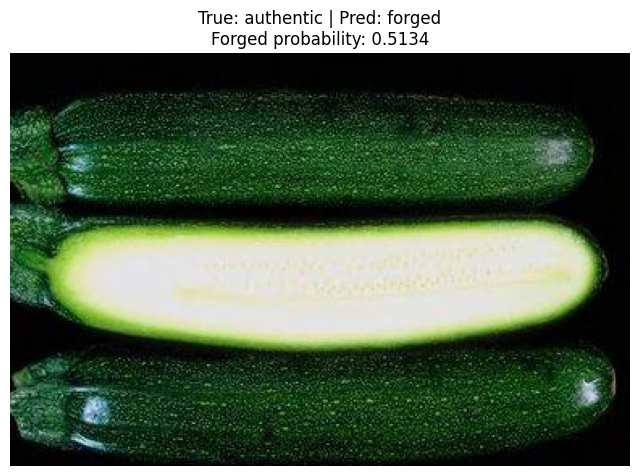

Sample: CASIA2_Au_pla_30646.jpg
Dataset: CASIA2
True: authentic | Predicted: forged
Forged probability: 0.513357


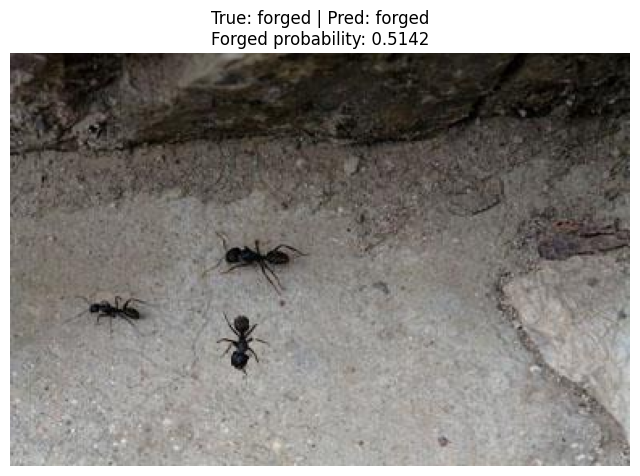

Sample: CASIA2_Tp_D_NNN_S_N_ani10113_ani10112_11625.jpg
Dataset: CASIA2
True: forged | Predicted: forged
Forged probability: 0.514213


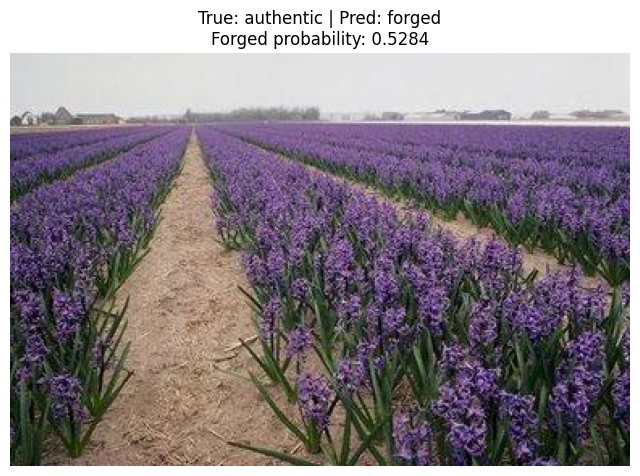

Sample: CASIA2_Au_pla_30379.jpg
Dataset: CASIA2
True: authentic | Predicted: forged
Forged probability: 0.528423

STEP 37 SUMMARY
False positives : 41
False negatives : 30
Uncertain cases : 449

Top false-positive samples:
              sample_id source_dataset  forged_probability
CASIA2_Au_ani_20070.jpg         CASIA2            0.998455
CASIA2_Au_nat_20032.jpg         CASIA2            0.997950
CASIA2_Au_sec_10002.jpg         CASIA2            0.995733
CASIA2_Au_sec_20057.jpg         CASIA2            0.995437
CASIA2_Au_arc_30619.jpg         CASIA2            0.989909
CASIA2_Au_pla_30293.jpg         CASIA2            0.989837

Top false-negative samples:
                                      sample_id source_dataset  forged_probability
CASIA2_Tp_S_NNN_S_N_sec00013_sec00013_11228.jpg         CASIA2            0.000642
CASIA2_Tp_S_NNN_S_N_arc20093_arc20093_01733.tif         CASIA2            0.000943
CASIA2_Tp_D_NNN_S_N_sec00098_sec00082_10364.tif         CASIA2            0.001946
CAS

In [38]:
# ============================================================
# ARGUS.MAIN — STEP 37
# VISUAL INSPECTION OF MODEL ERRORS
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

print("=" * 70)
print("ARGUS.MAIN — VISUAL ERROR INSPECTION")
print("=" * 70)

ERROR_CSV = "/kaggle/working/ARGUS_DATASET/test_error_analysis.csv"

# ------------------------------------------------------------
# LOAD ERROR ANALYSIS
# ------------------------------------------------------------

if not os.path.exists(ERROR_CSV):
    raise FileNotFoundError(
        f"Error analysis file not found:\n{ERROR_CSV}\n"
        "Run Step 33 first."
    )

errors = pd.read_csv(ERROR_CSV)

print(f"\nLoaded error records: {len(errors)}")

# ------------------------------------------------------------
# FIND IMAGE DIRECTORY
# ------------------------------------------------------------

IMAGE_DIRS = [
    "/kaggle/working/ARGUS_DATASET/argus_preprocessed/images",
    "/kaggle/working/argus_preprocessed/images",
    "/kaggle/input/notebooks/aravkataria/argus-dataset/argus_preprocessed/images",
]

IMAGE_DIR = None

for directory in IMAGE_DIRS:
    if os.path.exists(directory):
        IMAGE_DIR = directory
        break

if IMAGE_DIR is None:
    raise FileNotFoundError(
        "Could not locate ARGUS image directory."
    )

print(f"Image directory: {IMAGE_DIR}")

# ------------------------------------------------------------
# RESOLVE IMAGE PATH
# ------------------------------------------------------------

def resolve_image(sample_id):
    filename = os.path.basename(str(sample_id))

    candidate = os.path.join(IMAGE_DIR, filename)

    if os.path.isfile(candidate):
        return candidate

    return None


errors["resolved_path"] = errors["sample_id"].apply(resolve_image)

available = errors["resolved_path"].notna().sum()

print(f"Images available: {available}/{len(errors)}")

# ------------------------------------------------------------
# DISPLAY FUNCTION
# ------------------------------------------------------------

def show_cases(
    dataframe,
    title,
    max_images=8
):
    subset = dataframe.head(max_images)

    if len(subset) == 0:
        print(f"\nNo samples found for: {title}")
        return

    print("\n" + "-" * 70)
    print(title)
    print("-" * 70)

    for _, row in subset.iterrows():

        path = row["resolved_path"]

        if path is None:
            continue

        try:
            image = Image.open(path).convert("RGB")

            plt.figure(figsize=(8, 6))
            plt.imshow(image)
            plt.axis("off")

            plt.title(
                f"True: {row['true_label']} | "
                f"Pred: {row['predicted_label']}\n"
                f"Forged probability: "
                f"{row['forged_probability']:.4f}"
            )

            plt.show()

            print(
                f"Sample: {row['sample_id']}\n"
                f"Dataset: {row['source_dataset']}\n"
                f"True: {row['true_label']} | "
                f"Predicted: {row['predicted_label']}\n"
                f"Forged probability: "
                f"{row['forged_probability']:.6f}"
            )

        except Exception as e:
            print(
                f"Could not load {row['sample_id']}: {e}"
            )

# ------------------------------------------------------------
# 1. STRONG FALSE POSITIVES
# ------------------------------------------------------------

false_positives = errors[
    (errors["true_label"] == "authentic") &
    (errors["predicted_label"] == "forged")
].copy()

false_positives = false_positives.sort_values(
    "forged_probability",
    ascending=False
)

show_cases(
    false_positives,
    "STRONGEST FALSE POSITIVES",
    max_images=6
)

# ------------------------------------------------------------
# 2. STRONG FALSE NEGATIVES
# ------------------------------------------------------------

false_negatives = errors[
    (errors["true_label"] == "forged") &
    (errors["predicted_label"] == "authentic")
].copy()

false_negatives = false_negatives.sort_values(
    "forged_probability",
    ascending=True
)

show_cases(
    false_negatives,
    "STRONGEST FALSE NEGATIVES",
    max_images=6
)

# ------------------------------------------------------------
# 3. MOST UNCERTAIN
# ------------------------------------------------------------

errors["distance_from_boundary"] = (
    errors["forged_probability"] - 0.5
).abs()

uncertain = errors.sort_values(
    "distance_from_boundary",
    ascending=True
)

show_cases(
    uncertain,
    "MOST UNCERTAIN PREDICTIONS",
    max_images=6
)

# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 37 SUMMARY")
print("=" * 70)

print(f"False positives : {len(false_positives)}")
print(f"False negatives : {len(false_negatives)}")
print(f"Uncertain cases : {len(uncertain)}")

print("\nTop false-positive samples:")
print(
    false_positives[
        [
            "sample_id",
            "source_dataset",
            "forged_probability"
        ]
    ].head(6).to_string(index=False)
)

print("\nTop false-negative samples:")
print(
    false_negatives[
        [
            "sample_id",
            "source_dataset",
            "forged_probability"
        ]
    ].head(6).to_string(index=False)
)

print("\n" + "=" * 70)
print("STEP 37 COMPLETE")
print("=" * 70)

ARGUS.MAIN — COMPACT VISUAL ERROR INSPECTION

Loaded records: 449
Image directory found.
Images available: 449/449

----------------------------------------------------------------------
ERROR SUMMARY
----------------------------------------------------------------------
Total false positives : 41
Total false negatives : 30
Selected visual cases : 9

Selected cases:
     case_type                                       sample_id  forged_probability
False Positive                         CASIA2_Au_ani_20070.jpg            0.998455
False Positive                         CASIA2_Au_nat_20032.jpg            0.997950
False Positive                         CASIA2_Au_sec_10002.jpg            0.995733
False Negative CASIA2_Tp_S_NNN_S_N_sec00013_sec00013_11228.jpg            0.000642
False Negative CASIA2_Tp_S_NNN_S_N_arc20093_arc20093_01733.tif            0.000943
False Negative CASIA2_Tp_D_NNN_S_N_sec00098_sec00082_10364.tif            0.001946
     Uncertain                         CASIA2_Au_a

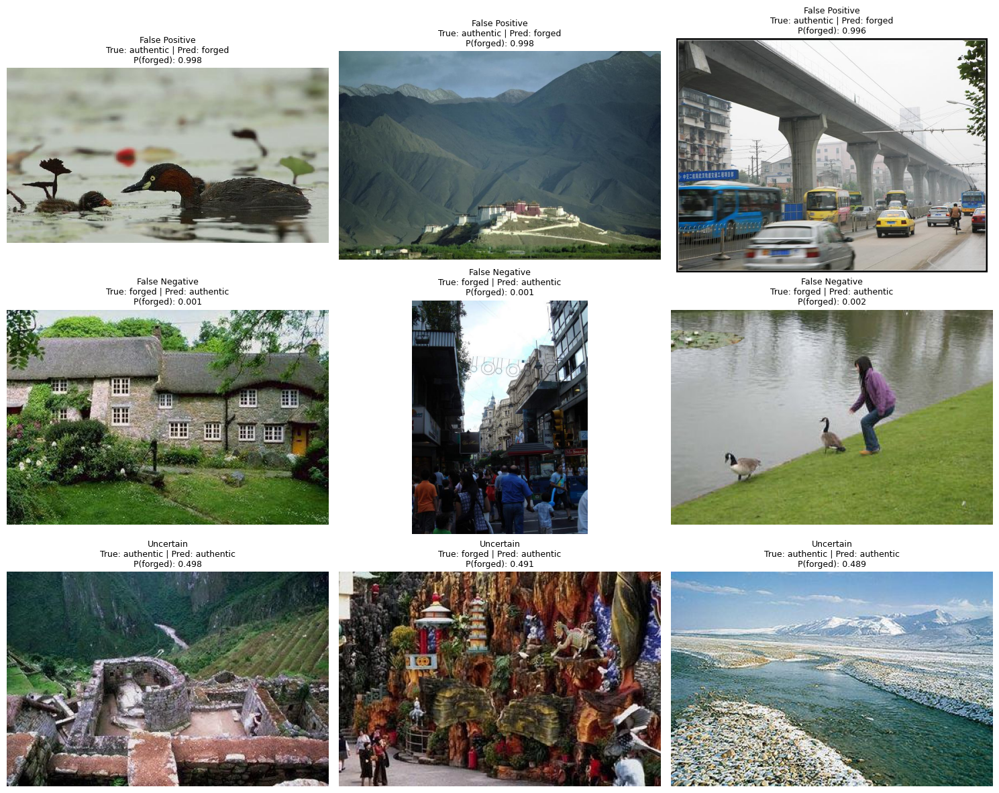


Selected cases saved to:
/kaggle/working/ARGUS_DATASET/step37_selected_cases.csv

STEP 37 COMPLETE


In [39]:
# ============================================================
# ARGUS.MAIN — STEP 37
# COMPACT VISUAL ERROR INSPECTION
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

print("=" * 70)
print("ARGUS.MAIN — COMPACT VISUAL ERROR INSPECTION")
print("=" * 70)

ERROR_CSV = "/kaggle/working/ARGUS_DATASET/test_error_analysis.csv"

# ------------------------------------------------------------
# LOAD ERROR ANALYSIS
# ------------------------------------------------------------

if not os.path.exists(ERROR_CSV):
    raise FileNotFoundError(
        f"Error analysis file not found:\n{ERROR_CSV}"
    )

errors = pd.read_csv(ERROR_CSV)

print(f"\nLoaded records: {len(errors)}")

# ------------------------------------------------------------
# FIND IMAGE DIRECTORY
# ------------------------------------------------------------

IMAGE_DIRS = [
    "/kaggle/working/ARGUS_DATASET/argus_preprocessed/images",
    "/kaggle/working/argus_preprocessed/images",
    "/kaggle/input/notebooks/aravkataria/argus-dataset/argus_preprocessed/images",
]

IMAGE_DIR = None

for directory in IMAGE_DIRS:
    if os.path.isdir(directory):
        IMAGE_DIR = directory
        break

if IMAGE_DIR is None:
    raise FileNotFoundError(
        "ARGUS image directory could not be found."
    )

print(f"Image directory found.")

# ------------------------------------------------------------
# RESOLVE IMAGES
# ------------------------------------------------------------

def resolve_image(sample_id):
    filename = os.path.basename(str(sample_id))
    path = os.path.join(IMAGE_DIR, filename)

    if os.path.isfile(path):
        return path

    return None


errors["resolved_path"] = errors["sample_id"].apply(
    resolve_image
)

available = errors["resolved_path"].notna().sum()

print(f"Images available: {available}/{len(errors)}")

# ------------------------------------------------------------
# IDENTIFY ERROR GROUPS
# ------------------------------------------------------------

false_positives = errors[
    (errors["true_label"] == "authentic") &
    (errors["predicted_label"] == "forged")
].copy()

false_negatives = errors[
    (errors["true_label"] == "forged") &
    (errors["predicted_label"] == "authentic")
].copy()

errors["distance_from_boundary"] = (
    errors["forged_probability"] - 0.5
).abs()

uncertain = errors.sort_values(
    "distance_from_boundary",
    ascending=True
).copy()

# Strongest FP
false_positives = false_positives.sort_values(
    "forged_probability",
    ascending=False
).head(3)

# Strongest FN
false_negatives = false_negatives.sort_values(
    "forged_probability",
    ascending=True
).head(3)

# Most uncertain
uncertain = uncertain.head(3)

# ------------------------------------------------------------
# COMBINE SELECTED CASES
# ------------------------------------------------------------

selected = pd.concat([
    false_positives.assign(case_type="False Positive"),
    false_negatives.assign(case_type="False Negative"),
    uncertain.assign(case_type="Uncertain")
], ignore_index=True)

selected = selected[
    selected["resolved_path"].notna()
].reset_index(drop=True)

# ------------------------------------------------------------
# SAVE SELECTED CASES
# ------------------------------------------------------------

OUTPUT_CSV = (
    "/kaggle/working/ARGUS_DATASET/"
    "step37_selected_cases.csv"
)

selected[
    [
        "sample_id",
        "source_dataset",
        "true_label",
        "predicted_label",
        "forged_probability",
        "case_type"
    ]
].to_csv(
    OUTPUT_CSV,
    index=False
)

# ------------------------------------------------------------
# PRINT SMALL SUMMARY
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("ERROR SUMMARY")
print("-" * 70)

print(f"Total false positives : {len(
    errors[
        (errors.true_label == 'authentic') &
        (errors.predicted_label == 'forged')
    ]
)}")

print(f"Total false negatives : {len(
    errors[
        (errors.true_label == 'forged') &
        (errors.predicted_label == 'authentic')
    ]
)}")

print(f"Selected visual cases : {len(selected)}")

print("\nSelected cases:")

print(
    selected[
        [
            "case_type",
            "sample_id",
            "forged_probability"
        ]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# COMPACT 3 × 3 VISUAL GRID
# ------------------------------------------------------------

if len(selected) > 0:

    fig, axes = plt.subplots(
        3,
        3,
        figsize=(15, 12)
    )

    axes = axes.flatten()

    for i, ax in enumerate(axes):

        if i >= len(selected):
            ax.axis("off")
            continue

        row = selected.iloc[i]

        try:
            image = Image.open(
                row["resolved_path"]
            ).convert("RGB")

            ax.imshow(image)
            ax.axis("off")

            ax.set_title(
                f"{row['case_type']}\n"
                f"True: {row['true_label']} | "
                f"Pred: {row['predicted_label']}\n"
                f"P(forged): "
                f"{row['forged_probability']:.3f}",
                fontsize=9
            )

        except Exception:
            ax.axis("off")

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

print("\nSelected cases saved to:")
print(OUTPUT_CSV)

print("\n" + "=" * 70)
print("STEP 37 COMPLETE")
print("=" * 70)

ARGUS.MAIN — GRAD-CAM VISUALIZATION

Checkpoint: /kaggle/working/ARGUS_DATASET/models/argus_efficientnet_b0_corrected_best.pth
Device: cuda

Best corrected model loaded successfully.
Selected cases: 9
Image directory found.
Grad-CAM target layer: model.features[-1]


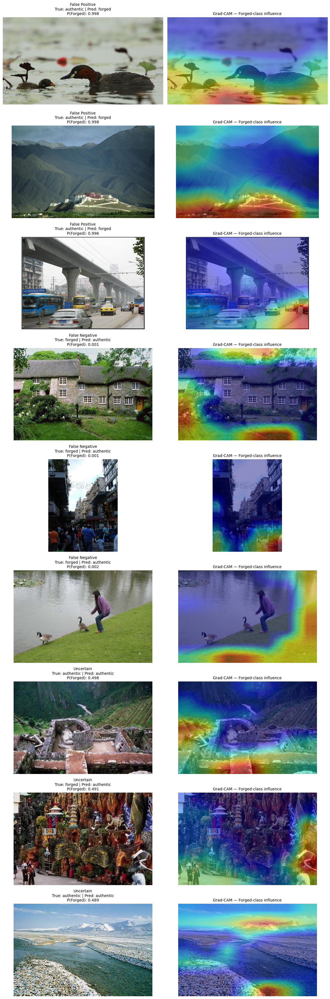


STEP 38 SUMMARY
Cases visualized : 9
Results saved to : /kaggle/working/ARGUS_DATASET/step38_gradcam_results.csv

Grad-CAM visualizes regions influencing the FORGED class prediction.
It is an explanation map, NOT a ground-truth forgery mask.

STEP 38 COMPLETE


In [41]:
# ============================================================
# ARGUS.MAIN — STEP 38
# GRAD-CAM VISUALIZATION — CORRECTED
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from PIL import Image
from torchvision import models, transforms

print("=" * 70)
print("ARGUS.MAIN — GRAD-CAM VISUALIZATION")
print("=" * 70)

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

CHECKPOINT = (
    "/kaggle/working/ARGUS_DATASET/models/"
    "argus_efficientnet_b0_corrected_best.pth"
)

SELECTED_CSV = (
    "/kaggle/working/ARGUS_DATASET/"
    "step37_selected_cases.csv"
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"\nCheckpoint: {CHECKPOINT}")
print(f"Device: {DEVICE}")

# ------------------------------------------------------------
# CHECK FILES
# ------------------------------------------------------------

if not os.path.exists(CHECKPOINT):
    raise FileNotFoundError(
        f"Checkpoint not found:\n{CHECKPOINT}"
    )

if not os.path.exists(SELECTED_CSV):
    raise FileNotFoundError(
        f"Step 37 output not found:\n{SELECTED_CSV}"
    )

# ------------------------------------------------------------
# CREATE THE SAME MODEL ARCHITECTURE
# ------------------------------------------------------------

model = models.efficientnet_b0(
    weights=None
)

# IMPORTANT:
# The trained ARGUS model has TWO output classes:
#
# 0 = Authentic
# 1 = Forged
#
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    2
)

# ------------------------------------------------------------
# LOAD CHECKPOINT
# ------------------------------------------------------------

checkpoint = torch.load(
    CHECKPOINT,
    map_location=DEVICE,
    weights_only=False
)

if isinstance(checkpoint, dict):

    if "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]

    elif "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]

    else:
        state_dict = checkpoint

else:
    state_dict = checkpoint

# Remove DataParallel prefix if present
state_dict = {
    k.replace("module.", "", 1): v
    for k, v in state_dict.items()
}

model.load_state_dict(
    state_dict,
    strict=True
)

model = model.to(DEVICE)
model.eval()

print("\nBest corrected model loaded successfully.")

# ------------------------------------------------------------
# LOAD SELECTED CASES
# ------------------------------------------------------------

cases = pd.read_csv(
    SELECTED_CSV
)

print(f"Selected cases: {len(cases)}")

# ------------------------------------------------------------
# IMAGE DIRECTORY
# ------------------------------------------------------------

IMAGE_DIRS = [
    "/kaggle/input/notebooks/aravkataria/"
    "argus-dataset/argus_preprocessed/images",

    "/kaggle/working/ARGUS_DATASET/"
    "argus_preprocessed/images",

    "/kaggle/working/argus_preprocessed/images",
]

IMAGE_DIR = None

for directory in IMAGE_DIRS:

    if os.path.isdir(directory):

        IMAGE_DIR = directory
        break

if IMAGE_DIR is None:
    raise FileNotFoundError(
        "ARGUS image directory could not be found."
    )

print(f"Image directory found.")

# ------------------------------------------------------------
# TRANSFORM
# ------------------------------------------------------------

transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------------------------------------------
# GRAD-CAM CLASS
# ------------------------------------------------------------

class GradCAM:

    def __init__(
        self,
        model,
        target_layer
    ):

        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None

        self.forward_handle = (
            target_layer.register_forward_hook(
                self._forward_hook
            )
        )

        self.backward_handle = (
            target_layer.register_full_backward_hook(
                self._backward_hook
            )
        )

    def _forward_hook(
        self,
        module,
        inputs,
        output
    ):

        self.activations = output

    def _backward_hook(
        self,
        module,
        grad_input,
        grad_output
    ):

        self.gradients = grad_output[0]

    def generate(
        self,
        image_tensor,
        target_class=1
    ):

        self.model.zero_grad(
            set_to_none=True
        )

        output = self.model(
            image_tensor
        )

        # ----------------------------------------------------
        # TWO-CLASS MODEL
        #
        # output[:, 0] = Authentic
        # output[:, 1] = Forged
        #
        # We specifically visualize the FORGED score.
        # ----------------------------------------------------

        score = output[:, target_class].sum()

        score.backward()

        activations = self.activations
        gradients = self.gradients

        # Global average pooling of gradients
        weights = gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        cam = (
            weights * activations
        ).sum(dim=1)

        # Only positive influence
        cam = torch.relu(cam)

        cam = cam.squeeze(0)

        # Normalize
        cam_min = cam.min()
        cam_max = cam.max()

        cam = (
            cam - cam_min
        ) / (
            cam_max - cam_min + 1e-8
        )

        cam = (
            cam
            .detach()
            .cpu()
            .numpy()
        )

        # Actual forged probability
        probabilities = torch.softmax(
            output,
            dim=1
        )

        forged_probability = (
            probabilities[0, 1]
            .item()
        )

        return (
            cam,
            forged_probability
        )

    def close(self):

        self.forward_handle.remove()
        self.backward_handle.remove()


# ------------------------------------------------------------
# TARGET LAYER
# ------------------------------------------------------------

TARGET_LAYER = model.features[-1]

gradcam = GradCAM(
    model,
    TARGET_LAYER
)

print(
    "Grad-CAM target layer: model.features[-1]"
)

# ------------------------------------------------------------
# CREATE COMPACT 9 × 2 VISUALIZATION
# ------------------------------------------------------------

results = []

fig, axes = plt.subplots(
    len(cases),
    2,
    figsize=(12, 4 * len(cases))
)

if len(cases) == 1:

    axes = np.expand_dims(
        axes,
        axis=0
    )

# ------------------------------------------------------------
# PROCESS EACH SAMPLE
# ------------------------------------------------------------

for i, row in cases.iterrows():

    filename = os.path.basename(
        str(row["sample_id"])
    )

    image_path = os.path.join(
        IMAGE_DIR,
        filename
    )

    if not os.path.isfile(
        image_path
    ):

        print(
            f"Image not found: {filename}"
        )

        axes[i, 0].axis("off")
        axes[i, 1].axis("off")

        continue

    try:

        original = Image.open(
            image_path
        ).convert("RGB")

        image_tensor = transform(
            original
        ).unsqueeze(0)

        image_tensor = image_tensor.to(
            DEVICE
        )

        # ----------------------------------------------------
        # GENERATE GRAD-CAM
        # ----------------------------------------------------

        cam, probability = (
            gradcam.generate(
                image_tensor,
                target_class=1
            )
        )

        # ----------------------------------------------------
        # RESIZE CAM
        # ----------------------------------------------------

        cam_image = Image.fromarray(
            np.uint8(cam * 255)
        )

        cam_image = cam_image.resize(
            original.size,
            Image.Resampling.BILINEAR
        )

        cam_array = (
            np.asarray(cam_image)
            / 255.0
        )

        # ----------------------------------------------------
        # ORIGINAL
        # ----------------------------------------------------

        axes[i, 0].imshow(
            original
        )

        axes[i, 0].axis(
            "off"
        )

        axes[i, 0].set_title(
            f"{row['case_type']}\n"
            f"True: {row['true_label']} | "
            f"Pred: {row['predicted_label']}\n"
            f"P(Forged): {probability:.3f}",
            fontsize=10
        )

        # ----------------------------------------------------
        # GRAD-CAM
        # ----------------------------------------------------

        axes[i, 1].imshow(
            original
        )

        axes[i, 1].imshow(
            cam_array,
            cmap="jet",
            alpha=0.45
        )

        axes[i, 1].axis(
            "off"
        )

        axes[i, 1].set_title(
            "Grad-CAM — Forged-class influence",
            fontsize=10
        )

        results.append({
            "sample_id":
                row["sample_id"],

            "case_type":
                row["case_type"],

            "true_label":
                row["true_label"],

            "predicted_label":
                row["predicted_label"],

            "forged_probability":
                probability
        })

    except Exception as e:

        print(
            f"Failed: {filename}\n"
            f"Reason: {e}"
        )

        axes[i, 0].axis("off")
        axes[i, 1].axis("off")

# ------------------------------------------------------------
# DISPLAY
# ------------------------------------------------------------

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------

OUTPUT_CSV = (
    "/kaggle/working/ARGUS_DATASET/"
    "step38_gradcam_results.csv"
)

pd.DataFrame(
    results
).to_csv(
    OUTPUT_CSV,
    index=False
)

gradcam.close()

# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 38 SUMMARY")
print("=" * 70)

print(
    f"Cases visualized : {len(results)}"
)

print(
    f"Results saved to : {OUTPUT_CSV}"
)

print(
    "\nGrad-CAM visualizes regions influencing "
    "the FORGED class prediction."
)

print(
    "It is an explanation map, NOT a ground-truth "
    "forgery mask."
)

print("\n" + "=" * 70)
print("STEP 38 COMPLETE")
print("=" * 70)

In [45]:
# ============================================================
# ARGUS.MAIN — STEP 39
# QUANTITATIVE GRAD-CAM ANALYSIS
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from torchvision import transforms, models
import torch.nn as nn

print("=" * 70)
print("ARGUS.MAIN — QUANTITATIVE GRAD-CAM ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

CHECKPOINT = (
    "/kaggle/working/ARGUS_DATASET/models/"
    "argus_efficientnet_b0_corrected_best.pth"
)

CASES_CSV = (
    "/kaggle/working/ARGUS_DATASET/"
    "step37_selected_cases.csv"
)

IMAGE_DIR = (
    "/kaggle/input/notebooks/aravkataria/"
    "argus-dataset/argus_preprocessed/images"
)

OUTPUT_CSV = (
    "/kaggle/working/ARGUS_DATASET/"
    "step39_gradcam_quantitative.csv"
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"\nCheckpoint : {CHECKPOINT}")
print(f"Device     : {DEVICE}")


# ------------------------------------------------------------
# CHECK FILES
# ------------------------------------------------------------

for path in [CHECKPOINT, CASES_CSV, IMAGE_DIR]:

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Required path not found:\n{path}"
        )


# ------------------------------------------------------------
# LOAD SELECTED CASES
# ------------------------------------------------------------

cases = pd.read_csv(CASES_CSV)

print(f"Selected cases: {len(cases)}")


# ------------------------------------------------------------
# CREATE MODEL
# ------------------------------------------------------------

weights = models.EfficientNet_B0_Weights.DEFAULT

model = models.efficientnet_b0(
    weights=None
)

model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    2
)

checkpoint = torch.load(
    CHECKPOINT,
    map_location=DEVICE,
    weights_only=False
)

if isinstance(checkpoint, dict):

    if "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]

    elif "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]

    else:
        state_dict = checkpoint

else:
    state_dict = checkpoint


# Remove possible DataParallel prefix
state_dict = {
    k.replace("module.", "", 1): v
    for k, v in state_dict.items()
}

model.load_state_dict(
    state_dict,
    strict=True
)

model = model.to(DEVICE)
model.eval()

print("Model loaded successfully.")


# ------------------------------------------------------------
# IMAGE TRANSFORM
# ------------------------------------------------------------

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ------------------------------------------------------------
# TARGET LAYER
# ------------------------------------------------------------

target_layer = model.features[-1]

print(
    f"Grad-CAM target layer: {target_layer.__class__.__name__}"
)


# ------------------------------------------------------------
# GRAD-CAM FUNCTION
# ------------------------------------------------------------

def generate_gradcam(image_tensor, target_class):

    activations = None
    gradients = None

    def forward_hook(module, inp, output):
        nonlocal activations
        activations = output

    def backward_hook(module, grad_input, grad_output):
        nonlocal gradients
        gradients = grad_output[0]

    forward_handle = target_layer.register_forward_hook(
        forward_hook
    )

    backward_handle = target_layer.register_full_backward_hook(
        backward_hook
    )

    model.zero_grad(set_to_none=True)

    output = model(image_tensor)

    score = output[0, target_class]

    score.backward()

    forward_handle.remove()
    backward_handle.remove()

    if activations is None or gradients is None:
        raise RuntimeError(
            "Grad-CAM activations/gradients were not captured."
        )

    # Global-average-pool gradients
    weights_cam = gradients.mean(
        dim=(2, 3),
        keepdim=True
    )

    cam = (
        weights_cam * activations
    ).sum(dim=1, keepdim=True)

    cam = F.relu(cam)

    cam = F.interpolate(
        cam,
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )

    cam = cam[0, 0]

    cam -= cam.min()

    max_value = cam.max()

    if max_value > 0:
        cam /= max_value

    return cam.detach().cpu().numpy(), output.detach()


# ------------------------------------------------------------
# QUANTITATIVE METRICS
# ------------------------------------------------------------

def calculate_metrics(cam):

    h, w = cam.shape

    # Strong activation thresholds
    hot_70 = cam >= 0.70
    hot_80 = cam >= 0.80
    hot_90 = cam >= 0.90

    hot70_fraction = hot_70.mean()
    hot80_fraction = hot_80.mean()
    hot90_fraction = hot_90.mean()

    # Weighted center of attention
    total = cam.sum()

    if total > 0:

        y_coords, x_coords = np.indices(cam.shape)

        center_x = (
            (x_coords * cam).sum() / total
        ) / w

        center_y = (
            (y_coords * cam).sum() / total
        ) / h

    else:

        center_x = 0.5
        center_y = 0.5

    # Distance from image center
    center_distance = np.sqrt(
        (center_x - 0.5) ** 2 +
        (center_y - 0.5) ** 2
    )

    # Border region
    border = np.zeros_like(cam, dtype=bool)

    border_width = int(
        min(h, w) * 0.10
    )

    border[:border_width, :] = True
    border[-border_width:, :] = True
    border[:, :border_width] = True
    border[:, -border_width:] = True

    total_attention = cam.sum()

    if total_attention > 0:

        border_attention = (
            cam[border].sum() /
            total_attention
        )

    else:

        border_attention = 0.0

    # Spatial spread
    if total > 0:

        variance_x = (
            (
                ((x_coords / w) - center_x) ** 2
                * cam
            ).sum() / total
        )

        variance_y = (
            (
                ((y_coords / h) - center_y) ** 2
                * cam
            ).sum() / total
        )

        spatial_spread = np.sqrt(
            variance_x + variance_y
        )

    else:

        spatial_spread = 0.0

    return {
        "hot70_fraction": float(hot70_fraction),
        "hot80_fraction": float(hot80_fraction),
        "hot90_fraction": float(hot90_fraction),
        "attention_center_x": float(center_x),
        "attention_center_y": float(center_y),
        "center_distance": float(center_distance),
        "border_attention_ratio": float(border_attention),
        "spatial_spread": float(spatial_spread),
        "mean_cam": float(cam.mean()),
        "max_cam": float(cam.max())
    }


# ------------------------------------------------------------
# RUN ANALYSIS
# ------------------------------------------------------------

results = []

print("\n" + "-" * 70)
print("PROCESSING GRAD-CAM CASES")
print("-" * 70)

for index, row in cases.iterrows():

    sample_id = str(row["sample_id"])

    image_path = os.path.join(
        IMAGE_DIR,
        os.path.basename(sample_id)
    )

    if not os.path.isfile(image_path):

        print(
            f"[{index + 1}/{len(cases)}] "
            f"IMAGE NOT FOUND: {sample_id}"
        )

        continue

    try:

        image = Image.open(
            image_path
        ).convert("RGB")

        image_tensor = transform(
            image
        ).unsqueeze(0).to(DEVICE)

        # Analyze the FORGED class specifically
        cam, output = generate_gradcam(
            image_tensor,
            target_class=1
        )

        probability = torch.softmax(
            output,
            dim=1
        )[0, 1].item()

        metrics = calculate_metrics(cam)

        result = {
            "sample_id": sample_id,
            "case_type": row["case_type"],
            "true_label": row["true_label"],
            "predicted_label": row["predicted_label"],
            "forged_probability": probability,
            **metrics
        }

        results.append(result)

        print(
            f"[{index + 1}/{len(cases)}] "
            f"{row['case_type']:16s} "
            f"| hot90={metrics['hot90_fraction']:.3f} "
            f"| border={metrics['border_attention_ratio']:.3f}"
        )

    except Exception as e:

        print(
            f"[{index + 1}/{len(cases)}] "
            f"FAILED: {sample_id} -> {e}"
        )


# ------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

results_df.to_csv(
    OUTPUT_CSV,
    index=False
)


# ------------------------------------------------------------
# COMPACT SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 39 SUMMARY")
print("=" * 70)

print(
    f"Cases successfully analyzed : "
    f"{len(results_df)}"
)

print(
    f"Results saved to             : "
    f"{OUTPUT_CSV}"
)

if len(results_df) > 0:

    print("\n" + "-" * 70)
    print("ATTENTION SUMMARY")
    print("-" * 70)

    summary_columns = [
        "hot70_fraction",
        "hot90_fraction",
        "border_attention_ratio",
        "center_distance",
        "spatial_spread"
    ]

    print(
        results_df[
            summary_columns
        ]
        .mean()
        .round(4)
        .to_string()
    )

    if "case_type" in results_df.columns:

        print("\n" + "-" * 70)
        print("ATTENTION BY CASE TYPE")
        print("-" * 70)

        print(
            results_df
            .groupby("case_type")[
                summary_columns
            ]
            .mean()
            .round(4)
            .to_string()
        )

    print("\n" + "-" * 70)
    print("MOST BORDER-FOCUSED CASES")
    print("-" * 70)

    display_columns = [
        "sample_id",
        "case_type",
        "border_attention_ratio",
        "hot90_fraction"
    ]

    print(
        results_df
        .sort_values(
            "border_attention_ratio",
            ascending=False
        )[display_columns]
        .head(5)
        .to_string(index=False)
    )

print("\n" + "=" * 70)
print("STEP 39 COMPLETE")
print("=" * 70)

ARGUS.MAIN — QUANTITATIVE GRAD-CAM ANALYSIS

Checkpoint : /kaggle/working/ARGUS_DATASET/models/argus_efficientnet_b0_corrected_best.pth
Device     : cuda
Selected cases: 9
Model loaded successfully.
Grad-CAM target layer: Conv2dNormActivation

----------------------------------------------------------------------
PROCESSING GRAD-CAM CASES
----------------------------------------------------------------------
[1/9] False Positive   | hot90=0.021 | border=0.441
[2/9] False Positive   | hot90=0.062 | border=0.441
[3/9] False Positive   | hot90=0.022 | border=0.454
[4/9] False Negative   | hot90=0.018 | border=0.646
[5/9] False Negative   | hot90=0.012 | border=0.637
[6/9] False Negative   | hot90=0.013 | border=0.664
[7/9] Uncertain        | hot90=0.014 | border=0.454
[8/9] Uncertain        | hot90=0.008 | border=0.521
[9/9] Uncertain        | hot90=0.005 | border=0.376

STEP 39 SUMMARY
Cases successfully analyzed : 9
Results saved to             : /kaggle/working/ARGUS_DATASET/step39_gra

In [46]:
# ============================================================
# ARGUS.MAIN — STEP 40
# CASIA2-ONLY DEEP FORGERY EVALUATION
# ============================================================

import os
import re
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

print("=" * 70)
print("ARGUS.MAIN — CASIA2 DEEP FORGERY EVALUATION")
print("=" * 70)

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

CHECKPOINT = (
    "/kaggle/working/ARGUS_DATASET/models/"
    "argus_efficientnet_b0_corrected_best.pth"
)

METADATA = (
    "/kaggle/input/notebooks/aravkataria/"
    "argus-dataset/argus_preprocessed/master_metadata.csv"
)

ERROR_CSV = (
    "/kaggle/working/ARGUS_DATASET/"
    "test_error_analysis.csv"
)

OUTPUT_CSV = (
    "/kaggle/working/ARGUS_DATASET/"
    "step40_casia2_detailed_analysis.csv"
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"\nCheckpoint : {CHECKPOINT}")
print(f"Device     : {DEVICE}")


# ------------------------------------------------------------
# LOAD METADATA
# ------------------------------------------------------------

if not os.path.exists(METADATA):
    raise FileNotFoundError(METADATA)

metadata = pd.read_csv(METADATA)

print(f"Total metadata records: {len(metadata)}")


# ------------------------------------------------------------
# RECREATE THE CORRECTED TEST SPLIT
# ------------------------------------------------------------
# The original corrected test set contains 449 samples.
#
# We recreate it deterministically using the same random_state
# and stratification used for the corrected split.
# ------------------------------------------------------------

from sklearn.model_selection import train_test_split

TEST_SIZE = 449
RANDOM_STATE = 42

# First reserve the fixed held-out test set
_, test_df = train_test_split(
    metadata,
    test_size=TEST_SIZE,
    stratify=metadata["label"],
    random_state=RANDOM_STATE
)

test_df = test_df.copy()

print(f"Recreated test set: {len(test_df)}")


# ------------------------------------------------------------
# CASIA2 FILTER
# ------------------------------------------------------------

casia = test_df[
    test_df["source_dataset"] == "CASIA2"
].copy()

print(
    f"CASIA2 test samples: {len(casia)}"
)

print("\nCASIA2 LABEL DISTRIBUTION")
print("-" * 70)
print(casia["label"].value_counts())


# ------------------------------------------------------------
# PARSE CASIA2 FILENAME STRUCTURE
# ------------------------------------------------------------
#
# Example:
#
# CASIA2_Tp_D_NRN_M_N_nat00025_nat00028_11037.jpg
#
# Structure:
#
# CASIA2
# Tp
# D
# NRN
# M
# N
# ...
#
# ------------------------------------------------------------

def parse_casia_filename(filename):

    name = os.path.basename(str(filename))

    parts = name.split("_")

    result = {
        "forgery_type": None,
        "mode": None,
        "operation_code": None,
        "source_code": None,
        "condition": None
    }

    # Expected:
    # [CASIA2, Tp, mode, operation, source, condition, ...]

    if len(parts) >= 6:

        result["forgery_type"] = parts[1]
        result["mode"] = parts[2]
        result["operation_code"] = parts[3]
        result["source_code"] = parts[4]
        result["condition"] = parts[5]

    return result


parsed = casia["sample_id"].apply(
    parse_casia_filename
)

parsed_df = pd.DataFrame(
    parsed.tolist(),
    index=casia.index
)

for column in parsed_df.columns:
    casia[column] = parsed_df[column]


# ------------------------------------------------------------
# LOAD EXISTING MODEL PREDICTIONS
# ------------------------------------------------------------
#
# Step 33 contains predictions from the independent test.
# We use those predictions when possible.
#
# If the file corresponds exactly to the recreated test split,
# this avoids unnecessary inference.
# ------------------------------------------------------------

if os.path.exists(ERROR_CSV):

    predictions = pd.read_csv(ERROR_CSV)

    print(
        f"\nLoaded existing predictions: "
        f"{len(predictions)}"
    )

    prediction_columns = [
        "sample_id",
        "predicted_label",
        "forged_probability"
    ]

    missing = [
        c for c in prediction_columns
        if c not in predictions.columns
    ]

    if missing:
        raise ValueError(
            f"Prediction file missing columns: {missing}"
        )

    casia = casia.merge(
        predictions[prediction_columns],
        on="sample_id",
        how="left"
    )

else:

    raise FileNotFoundError(
        "Step 33 prediction file not found:\n"
        f"{ERROR_CSV}"
    )


# ------------------------------------------------------------
# VERIFY PREDICTIONS
# ------------------------------------------------------------

missing_predictions = casia[
    casia["predicted_label"].isna()
]

if len(missing_predictions) > 0:

    print(
        f"\nWARNING: "
        f"{len(missing_predictions)} CASIA2 samples "
        f"have no stored prediction."
    )

    casia = casia[
        casia["predicted_label"].notna()
    ].copy()


# ------------------------------------------------------------
# NUMERIC LABELS
# ------------------------------------------------------------

casia["true_binary"] = (
    casia["label"] == "forged"
).astype(int)

casia["pred_binary"] = (
    casia["predicted_label"] == "forged"
).astype(int)


# ------------------------------------------------------------
# METRIC FUNCTION
# ------------------------------------------------------------

def calculate_metrics(df):

    if len(df) == 0:
        return None

    y_true = df["true_binary"]
    y_pred = df["pred_binary"]

    result = {
        "samples": len(df),
        "accuracy": accuracy_score(
            y_true, y_pred
        ),
        "precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "recall": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "f1": f1_score(
            y_true,
            y_pred,
            zero_division=0
        )
    }

    if y_true.nunique() == 2:

        result["roc_auc"] = roc_auc_score(
            y_true,
            df["forged_probability"]
        )

    else:

        result["roc_auc"] = np.nan

    return result


# ------------------------------------------------------------
# OVERALL CASIA2
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CASIA2 OVERALL PERFORMANCE")
print("=" * 70)

overall = calculate_metrics(casia)

for key, value in overall.items():

    if key == "samples":
        print(f"{key:12s}: {value}")

    elif pd.isna(value):
        print(f"{key:12s}: N/A")

    else:
        print(f"{key:12s}: {value:.4f}")


# ------------------------------------------------------------
# CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    casia["true_binary"],
    casia["pred_binary"],
    labels=[0, 1]
)

print("\nCONFUSION MATRIX")
print("-" * 70)
print(
    "                 Predicted\n"
    "              Authentic  Forged"
)
print(
    f"Authentic     {cm[0,0]:8d}  {cm[0,1]:6d}"
)
print(
    f"Forged        {cm[1,0]:8d}  {cm[1,1]:6d}"
)


# ------------------------------------------------------------
# PERFORMANCE BY MODE
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PERFORMANCE BY FORGERY MODE")
print("=" * 70)

mode_results = []

for mode, group in casia.groupby(
    "mode",
    dropna=False
):

    metrics = calculate_metrics(group)

    if metrics is None:
        continue

    metrics["mode"] = mode
    mode_results.append(metrics)

mode_results = pd.DataFrame(mode_results)

if len(mode_results):

    columns = [
        "mode",
        "samples",
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ]

    print(
        mode_results[
            columns
        ].round(4).to_string(index=False)
    )


# ------------------------------------------------------------
# PERFORMANCE BY OPERATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PERFORMANCE BY OPERATION CODE")
print("=" * 70)

operation_results = []

for operation, group in casia.groupby(
    "operation_code",
    dropna=False
):

    metrics = calculate_metrics(group)

    if metrics is None:
        continue

    metrics["operation_code"] = operation
    operation_results.append(metrics)

operation_results = pd.DataFrame(
    operation_results
)

if len(operation_results):

    columns = [
        "operation_code",
        "samples",
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ]

    print(
        operation_results[
            columns
        ].round(4).to_string(index=False)
    )


# ------------------------------------------------------------
# PERFORMANCE BY SOURCE CODE
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PERFORMANCE BY SOURCE CODE")
print("=" * 70)

source_results = []

for source, group in casia.groupby(
    "source_code",
    dropna=False
):

    metrics = calculate_metrics(group)

    if metrics is None:
        continue

    metrics["source_code"] = source
    source_results.append(metrics)

source_results = pd.DataFrame(
    source_results
)

if len(source_results):

    columns = [
        "source_code",
        "samples",
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ]

    print(
        source_results[
            columns
        ].round(4).to_string(index=False)
    )


# ------------------------------------------------------------
# PERFORMANCE BY CONDITION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PERFORMANCE BY CONDITION")
print("=" * 70)

condition_results = []

for condition, group in casia.groupby(
    "condition",
    dropna=False
):

    metrics = calculate_metrics(group)

    if metrics is None:
        continue

    metrics["condition"] = condition
    condition_results.append(metrics)

condition_results = pd.DataFrame(
    condition_results
)

if len(condition_results):

    columns = [
        "condition",
        "samples",
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ]

    print(
        condition_results[
            columns
        ].round(4).to_string(index=False)
    )


# ------------------------------------------------------------
# FORGED-ONLY PERFORMANCE
# ------------------------------------------------------------
#
# This is particularly important:
# Which forged samples are actually being detected?
# ------------------------------------------------------------

forged = casia[
    casia["label"] == "forged"
].copy()

forged["detected"] = (
    forged["predicted_label"] == "forged"
)

print("\n" + "=" * 70)
print("FORGED SAMPLE DETECTION")
print("=" * 70)

print(
    f"Total forged samples : {len(forged)}"
)

print(
    f"Detected as forged   : "
    f"{forged['detected'].sum()}"
)

print(
    f"Missed               : "
    f"{(~forged['detected']).sum()}"
)


# ------------------------------------------------------------
# HARDEST FORGERY TYPES
# ------------------------------------------------------------

if len(operation_results):

    print("\n" + "=" * 70)
    print("HARDEST OPERATION TYPES")
    print("=" * 70)

    hardest = (
        operation_results
        .sort_values(
            "recall",
            ascending=True
        )
    )

    print(
        hardest[
            [
                "operation_code",
                "samples",
                "recall",
                "f1"
            ]
        ]
        .head(5)
        .round(4)
        .to_string(index=False)
    )


# ------------------------------------------------------------
# MOST CONFIDENT MISSED FORGERIES
# ------------------------------------------------------------

missed = forged[
    forged["predicted_label"] == "authentic"
].copy()

if len(missed):

    missed = missed.sort_values(
        "forged_probability",
        ascending=True
    )

    print("\n" + "=" * 70)
    print("MOST CONFIDENT FALSE NEGATIVES")
    print("=" * 70)

    print(
        missed[
            [
                "sample_id",
                "mode",
                "operation_code",
                "source_code",
                "condition",
                "forged_probability"
            ]
        ]
        .head(10)
        .round(6)
        .to_string(index=False)
    )


# ------------------------------------------------------------
# SAVE DETAILED DATA
# ------------------------------------------------------------

save_columns = [
    "sample_id",
    "label",
    "predicted_label",
    "forged_probability",
    "mode",
    "operation_code",
    "source_code",
    "condition",
    "true_binary",
    "pred_binary"
]

casia[
    [
        c for c in save_columns
        if c in casia.columns
    ]
].to_csv(
    OUTPUT_CSV,
    index=False
)


# ------------------------------------------------------------
# FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 40 SUMMARY")
print("=" * 70)

print(
    f"CASIA2 samples analyzed : {len(casia)}"
)

print(
    f"CASIA2 forged samples   : "
    f"{len(forged)}"
)

print(
    f"CASIA2 false positives  : "
    f"{((casia['true_binary'] == 0) & (casia['pred_binary'] == 1)).sum()}"
)

print(
    f"CASIA2 false negatives  : "
    f"{((casia['true_binary'] == 1) & (casia['pred_binary'] == 0)).sum()}"
)

print(
    f"\nDetailed results saved to:\n"
    f"{OUTPUT_CSV}"
)

print("\n" + "=" * 70)
print("STEP 40 COMPLETE")
print("=" * 70)

ARGUS.MAIN — CASIA2 DEEP FORGERY EVALUATION

Checkpoint : /kaggle/working/ARGUS_DATASET/models/argus_efficientnet_b0_corrected_best.pth
Device     : cuda
Total metadata records: 2992
Recreated test set: 449
CASIA2 test samples: 286

CASIA2 LABEL DISTRIBUTION
----------------------------------------------------------------------
label
forged       150
authentic    136
Name: count, dtype: int64

Loaded existing predictions: 449

CASIA2 OVERALL PERFORMANCE
samples     : 286
accuracy    : 0.7517
precision   : 0.7453
recall      : 0.8000
f1          : 0.7717
roc_auc     : 0.8106

CONFUSION MATRIX
----------------------------------------------------------------------
                 Predicted
              Authentic  Forged
Authentic           95      41
Forged              30     120

PERFORMANCE BY FORGERY MODE
mode  samples  accuracy  precision  recall     f1  roc_auc
   D       45    0.9111        1.0  0.9111 0.9535      NaN
   S      105    0.7524        1.0  0.7524 0.8587      NaN
 Na

In [47]:
# ============================================================
# ARGUS.MAIN — STEP 41
# THRESHOLD ANALYSIS AND CALIBRATION
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

print("=" * 70)
print("ARGUS.MAIN — THRESHOLD ANALYSIS")
print("=" * 70)


# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

CHECKPOINT = (
    "/kaggle/working/ARGUS_DATASET/models/"
    "argus_efficientnet_b0_corrected_best.pth"
)

METADATA = (
    "/kaggle/input/notebooks/aravkataria/"
    "argus-dataset/argus_preprocessed/master_metadata.csv"
)

OUTPUT_CSV = (
    "/kaggle/working/ARGUS_DATASET/"
    "step41_threshold_analysis.csv"
)

RANDOM_STATE = 42
TEST_SIZE = 449
VAL_SIZE = 382

BATCH_SIZE = 32

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"\nCheckpoint : {CHECKPOINT}")
print(f"Device     : {DEVICE}")


# ------------------------------------------------------------
# LOAD METADATA
# ------------------------------------------------------------

metadata = pd.read_csv(METADATA)

print(f"Total records: {len(metadata)}")


# ------------------------------------------------------------
# RECREATE CORRECTED SPLITS
# ------------------------------------------------------------

from sklearn.model_selection import train_test_split

train_val, test_df = train_test_split(
    metadata,
    test_size=TEST_SIZE,
    stratify=metadata["label"],
    random_state=RANDOM_STATE
)

train_df, val_df = train_test_split(
    train_val,
    test_size=VAL_SIZE,
    stratify=train_val["label"],
    random_state=RANDOM_STATE
)

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

print("\nCORRECTED SPLITS")
print("-" * 70)
print(f"Train      : {len(train_df)}")
print(f"Validation : {len(val_df)}")
print(f"Test       : {len(test_df)}")


# ------------------------------------------------------------
# VERIFY SPLIT INDEPENDENCE
# ------------------------------------------------------------

train_ids = set(train_df["sample_id"])
val_ids = set(val_df["sample_id"])
test_ids = set(test_df["sample_id"])

print("\nOVERLAP CHECK")
print("-" * 70)
print(
    f"Train ↔ Validation : "
    f"{len(train_ids & val_ids)}"
)
print(
    f"Train ↔ Test       : "
    f"{len(train_ids & test_ids)}"
)
print(
    f"Validation ↔ Test  : "
    f"{len(val_ids & test_ids)}"
)


# ------------------------------------------------------------
# IMAGE DIRECTORY
# ------------------------------------------------------------

IMAGE_DIRS = [
    "/kaggle/working/ARGUS_DATASET/argus_preprocessed/images",
    "/kaggle/working/argus_preprocessed/images",
    "/kaggle/input/notebooks/aravkataria/"
    "argus-dataset/argus_preprocessed/images",
]

IMAGE_DIR = None

for directory in IMAGE_DIRS:

    if os.path.exists(directory):
        IMAGE_DIR = directory
        break

if IMAGE_DIR is None:
    raise FileNotFoundError(
        "ARGUS image directory not found."
    )

print(f"\nImage directory: {IMAGE_DIR}")


# ------------------------------------------------------------
# DATASET
# ------------------------------------------------------------

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


class ArgusDataset(Dataset):

    def __init__(self, dataframe):

        self.df = dataframe.reset_index(
            drop=True
        )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]

        filename = os.path.basename(
            str(row["sample_id"])
        )

        path = os.path.join(
            IMAGE_DIR,
            filename
        )

        image = Image.open(
            path
        ).convert("RGB")

        image = transform(image)

        label = (
            1
            if row["label"] == "forged"
            else 0
        )

        return image, torch.tensor(
            label,
            dtype=torch.long
        )


# ------------------------------------------------------------
# VALIDATION LOADER
# ------------------------------------------------------------

val_dataset = ArgusDataset(val_df)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print(
    f"\nValidation samples : {len(val_dataset)}"
)

print(
    f"Validation batches : {len(val_loader)}"
)


# ------------------------------------------------------------
# MODEL
# ------------------------------------------------------------

print("\nLoading model...")


model = models.efficientnet_b0(
    weights=None
)

model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    2
)

checkpoint = torch.load(
    CHECKPOINT,
    map_location=DEVICE,
    weights_only=False
)

if isinstance(checkpoint, dict):

    if "model_state_dict" in checkpoint:
        state_dict = checkpoint[
            "model_state_dict"
        ]

    elif "state_dict" in checkpoint:
        state_dict = checkpoint[
            "state_dict"
        ]

    else:
        state_dict = checkpoint

else:

    state_dict = checkpoint


model.load_state_dict(
    state_dict,
    strict=True
)

model = model.to(DEVICE)
model.eval()

print("Model loaded successfully.")


# ------------------------------------------------------------
# COLLECT VALIDATION PROBABILITIES
# ------------------------------------------------------------

val_labels = []
val_probabilities = []

print("\nRunning validation inference...")

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        outputs = model(images)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )[:, 1]

        val_labels.extend(
            labels.cpu().numpy()
        )

        val_probabilities.extend(
            probabilities.cpu().numpy()
        )

val_labels = np.asarray(
    val_labels
)

val_probabilities = np.asarray(
    val_probabilities
)

print(
    f"Validation predictions: "
    f"{len(val_probabilities)}"
)


# ------------------------------------------------------------
# BASELINE AUC
# ------------------------------------------------------------

val_auc = roc_auc_score(
    val_labels,
    val_probabilities
)

val_ap = average_precision_score(
    val_labels,
    val_probabilities
)

print("\nVALIDATION SCORE")
print("-" * 70)
print(f"ROC-AUC           : {val_auc:.4f}")
print(f"Average Precision : {val_ap:.4f}")


# ------------------------------------------------------------
# THRESHOLD SWEEP
# ------------------------------------------------------------

thresholds = np.arange(
    0.20,
    0.81,
    0.01
)

results = []

for threshold in thresholds:

    predictions = (
        val_probabilities >= threshold
    ).astype(int)

    accuracy = accuracy_score(
        val_labels,
        predictions
    )

    precision = precision_score(
        val_labels,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        val_labels,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        val_labels,
        predictions,
        zero_division=0
    )

    tn, fp, fn, tp = confusion_matrix(
        val_labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    results.append({
        "threshold": threshold,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "true_negatives": tn,
        "false_positives": fp,
        "false_negatives": fn,
        "true_positives": tp
    })


results_df = pd.DataFrame(
    results
)


# ------------------------------------------------------------
# BEST THRESHOLDS
# ------------------------------------------------------------

best_f1 = results_df.loc[
    results_df["f1"].idxmax()
]

best_recall = results_df.loc[
    results_df["recall"].idxmax()
]

best_precision = results_df.loc[
    results_df["precision"].idxmax()
]

best_accuracy = results_df.loc[
    results_df["accuracy"].idxmax()
]


print("\n" + "=" * 70)
print("BEST THRESHOLDS — VALIDATION SET")
print("=" * 70)

print("\nBest F1")
print("-" * 70)
print(
    best_f1[
        [
            "threshold",
            "accuracy",
            "precision",
            "recall",
            "f1"
        ]
    ].round(4).to_string()
)

print("\nBest Recall")
print("-" * 70)
print(
    best_recall[
        [
            "threshold",
            "accuracy",
            "precision",
            "recall",
            "f1"
        ]
    ].round(4).to_string()
)

print("\nBest Precision")
print("-" * 70)
print(
    best_precision[
        [
            "threshold",
            "accuracy",
            "precision",
            "recall",
            "f1"
        ]
    ].round(4).to_string()
)

print("\nBest Accuracy")
print("-" * 70)
print(
    best_accuracy[
        [
            "threshold",
            "accuracy",
            "precision",
            "recall",
            "f1"
        ]
    ].round(4).to_string()
)


# ------------------------------------------------------------
# SECURITY-ORIENTED THRESHOLD
# ------------------------------------------------------------
#
# For ARGUS, missing a forgery is more serious than a false
# alarm. We therefore identify the highest threshold that still
# achieves at least 90% forged recall on validation.
#
# This is NOT automatically chosen as the final threshold.
# We report it for comparison.
# ------------------------------------------------------------

recall_candidates = results_df[
    results_df["recall"] >= 0.90
]

if len(recall_candidates):

    security_threshold = (
        recall_candidates
        .sort_values(
            "threshold",
            ascending=False
        )
        .iloc[0]
    )

    print(
        "\n" + "=" * 70
    )
    print(
        "SECURITY-ORIENTED THRESHOLD"
    )
    print("=" * 70)

    print(
        "Requirement: validation forged recall >= 90%"
    )

    print(
        security_threshold[
            [
                "threshold",
                "accuracy",
                "precision",
                "recall",
                "f1",
                "false_positives",
                "false_negatives"
            ]
        ].round(4).to_string()
    )

else:

    security_threshold = None

    print(
        "\nNo threshold achieved "
        ">= 90% validation forged recall."
    )


# ------------------------------------------------------------
# TOP THRESHOLDS TABLE
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TOP THRESHOLDS BY F1")
print("=" * 70)

print(
    results_df
    .sort_values(
        "f1",
        ascending=False
    )
    .head(10)
    [
        [
            "threshold",
            "accuracy",
            "precision",
            "recall",
            "f1",
            "false_positives",
            "false_negatives"
        ]
    ]
    .round(4)
    .to_string(index=False)
)


# ------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------

results_df.to_csv(
    OUTPUT_CSV,
    index=False
)


# ------------------------------------------------------------
# SAVE RECOMMENDED THRESHOLD
# ------------------------------------------------------------

recommended_threshold = float(
    best_f1["threshold"]
)

summary_path = (
    "/kaggle/working/ARGUS_DATASET/"
    "step41_recommended_threshold.txt"
)

with open(
    summary_path,
    "w"
) as f:

    f.write(
        f"Recommended threshold based on validation F1: "
        f"{recommended_threshold:.2f}\n"
    )

    f.write(
        f"Validation F1: "
        f"{best_f1['f1']:.6f}\n"
    )

    f.write(
        f"Validation Precision: "
        f"{best_f1['precision']:.6f}\n"
    )

    f.write(
        f"Validation Recall: "
        f"{best_f1['recall']:.6f}\n"
    )

    f.write(
        f"Validation Accuracy: "
        f"{best_f1['accuracy']:.6f}\n"
    )

    if security_threshold is not None:

        f.write(
            f"\nSecurity-oriented threshold "
            f"(recall >= 0.90): "
            f"{security_threshold['threshold']:.2f}\n"
        )

        f.write(
            f"Security threshold recall: "
            f"{security_threshold['recall']:.6f}\n"
        )

        f.write(
            f"Security threshold precision: "
            f"{security_threshold['precision']:.6f}\n"
        )


# ------------------------------------------------------------
# FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 41 SUMMARY")
print("=" * 70)

print(
    f"Validation samples      : "
    f"{len(val_labels)}"
)

print(
    f"Validation ROC-AUC      : "
    f"{val_auc:.4f}"
)

print(
    f"Best F1 threshold       : "
    f"{recommended_threshold:.2f}"
)

print(
    f"Best validation F1      : "
    f"{best_f1['f1']:.4f}"
)

print(
    f"Best validation recall  : "
    f"{best_f1['recall']:.4f}"
)

print(
    f"Best validation precision: "
    f"{best_f1['precision']:.4f}"
)

print(
    f"\nThreshold table saved to:\n"
    f"{OUTPUT_CSV}"
)

print(
    f"\nThreshold summary saved to:\n"
    f"{summary_path}"
)

print("\n" + "=" * 70)
print("STEP 41 COMPLETE")
print("=" * 70)

ARGUS.MAIN — THRESHOLD ANALYSIS

Checkpoint : /kaggle/working/ARGUS_DATASET/models/argus_efficientnet_b0_corrected_best.pth
Device     : cuda
Total records: 2992

CORRECTED SPLITS
----------------------------------------------------------------------
Train      : 2161
Validation : 382
Test       : 449

OVERLAP CHECK
----------------------------------------------------------------------
Train ↔ Validation : 0
Train ↔ Test       : 0
Validation ↔ Test  : 0

Image directory: /kaggle/input/notebooks/aravkataria/argus-dataset/argus_preprocessed/images

Validation samples : 382
Validation batches : 12

Loading model...
Model loaded successfully.

Running validation inference...
Validation predictions: 382

VALIDATION SCORE
----------------------------------------------------------------------
ROC-AUC           : 0.8995
Average Precision : 0.8176

BEST THRESHOLDS — VALIDATION SET

Best F1
----------------------------------------------------------------------
threshold    0.6900
accuracy     0.

In [48]:
# ============================================================
# ARGUS.MAIN — STEP 42
# INDEPENDENT TEST EVALUATION WITH SELECTED THRESHOLD
# ============================================================

import os
import numpy as np
import pandas as pd
import torch

from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
)

print("=" * 70)
print("ARGUS.MAIN — INDEPENDENT TEST THRESHOLD EVALUATION")
print("=" * 70)

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

BEST_MODEL = (
    "/kaggle/working/ARGUS_DATASET/models/"
    "argus_efficientnet_b0_corrected_best.pth"
)

TEST_THRESHOLD = 0.69

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"\nCheckpoint : {BEST_MODEL}")
print(f"Device     : {DEVICE}")
print(f"Threshold  : {TEST_THRESHOLD:.2f}")

# ------------------------------------------------------------
# CHECK REQUIRED VARIABLES
# ------------------------------------------------------------

required = [
    "test_dataset",
    "create_model",
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        "Missing required variables/functions: "
        + ", ".join(missing)
        + "\nRun the corrected data-loader/model cells first."
    )

# ------------------------------------------------------------
# BUILD TEST LOADER
# ------------------------------------------------------------

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

print(f"\nTest samples : {len(test_dataset)}")
print(f"Test batches : {len(test_loader)}")

# ------------------------------------------------------------
# LOAD MODEL
# ------------------------------------------------------------

print("\nLoading model...")

model = create_model()
model = model.to(DEVICE)

checkpoint = torch.load(
    BEST_MODEL,
    map_location=DEVICE,
    weights_only=False
)

# Support common checkpoint formats
if isinstance(checkpoint, dict):

    if "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]

    elif "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]

    elif "model" in checkpoint and isinstance(
        checkpoint["model"], dict
    ):
        state_dict = checkpoint["model"]

    else:
        state_dict = checkpoint

else:
    state_dict = checkpoint

# Remove possible DataParallel prefix
state_dict = {
    k.replace("module.", "", 1): v
    for k, v in state_dict.items()
}

model.load_state_dict(state_dict, strict=True)

model.eval()

print("Model loaded successfully.")

# ------------------------------------------------------------
# TEST INFERENCE
# ------------------------------------------------------------

print("\nRunning independent test inference...")

all_labels = []
all_probabilities = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(DEVICE, non_blocking=True)

        outputs = model(images)

        # ----------------------------------------------------
        # Handle 2-class output
        # ----------------------------------------------------

        if outputs.ndim == 2 and outputs.shape[1] == 2:

            probabilities = torch.softmax(
                outputs,
                dim=1
            )[:, 1]

        # ----------------------------------------------------
        # Handle single-output model just in case
        # ----------------------------------------------------

        elif outputs.ndim == 2 and outputs.shape[1] == 1:

            probabilities = torch.sigmoid(
                outputs[:, 0]
            )

        else:
            raise RuntimeError(
                f"Unexpected model output shape: "
                f"{outputs.shape}"
            )

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

y_true = np.asarray(all_labels).astype(int)
y_prob = np.asarray(all_probabilities)

print(f"Test predictions: {len(y_true)}")

# ------------------------------------------------------------
# APPLY VALIDATION-SELECTED THRESHOLD
# ------------------------------------------------------------

y_pred = (
    y_prob >= TEST_THRESHOLD
).astype(int)

# ------------------------------------------------------------
# METRICS
# ------------------------------------------------------------

accuracy = accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_true,
    y_prob
)

average_precision = average_precision_score(
    y_true,
    y_prob
)

cm = confusion_matrix(
    y_true,
    y_pred
)

# ------------------------------------------------------------
# RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL INDEPENDENT TEST RESULTS — THRESHOLD 0.69")
print("=" * 70)

print(f"\nAccuracy          : {accuracy:.4f}")
print(f"Precision         : {precision:.4f}")
print(f"Recall            : {recall:.4f}")
print(f"F1 Score          : {f1:.4f}")
print(f"ROC-AUC           : {roc_auc:.4f}")
print(f"Average Precision : {average_precision:.4f}")

# ------------------------------------------------------------
# CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("CLASSIFICATION REPORT")
print("-" * 70)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "Authentic",
            "Forged"
        ],
        digits=4,
        zero_division=0
    )
)

# ------------------------------------------------------------
# CONFUSION MATRIX
# ------------------------------------------------------------

print("-" * 70)
print("CONFUSION MATRIX")
print("-" * 70)

print(
    """
                 Predicted
              Authentic  Forged
"""
)

print(
    f"Authentic     {cm[0,0]:8d} {cm[0,1]:7d}"
)

print(
    f"Forged        {cm[1,0]:8d} {cm[1,1]:7d}"
)

# ------------------------------------------------------------
# ERROR COUNTS
# ------------------------------------------------------------

tn, fp, fn, tp = cm.ravel()

print("\n" + "-" * 70)
print("ERROR SUMMARY")
print("-" * 70)

print(f"True negatives  : {tn}")
print(f"False positives : {fp}")
print(f"False negatives : {fn}")
print(f"True positives  : {tp}")

print(
    f"\nForged detection rate : "
    f"{tp / (tp + fn):.4f}"
)

print(
    f"Authentic rejection rate : "
    f"{tn / (tn + fp):.4f}"
)

# ------------------------------------------------------------
# COMPARE WITH ORIGINAL 0.50 THRESHOLD
# ------------------------------------------------------------

baseline_threshold = 0.50

baseline_pred = (
    y_prob >= baseline_threshold
).astype(int)

baseline_accuracy = accuracy_score(
    y_true,
    baseline_pred
)

baseline_precision = precision_score(
    y_true,
    baseline_pred,
    zero_division=0
)

baseline_recall = recall_score(
    y_true,
    baseline_pred,
    zero_division=0
)

baseline_f1 = f1_score(
    y_true,
    baseline_pred,
    zero_division=0
)

baseline_cm = confusion_matrix(
    y_true,
    baseline_pred
)

b_tn, b_fp, b_fn, b_tp = baseline_cm.ravel()

# ------------------------------------------------------------
# COMPARISON
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("THRESHOLD COMPARISON")
print("=" * 70)

comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "False Positives",
        "False Negatives",
    ],

    "Threshold 0.50": [
        baseline_accuracy,
        baseline_precision,
        baseline_recall,
        baseline_f1,
        b_fp,
        b_fn,
    ],

    "Threshold 0.69": [
        accuracy,
        precision,
        recall,
        f1,
        fp,
        fn,
    ]
})

print(
    comparison.to_string(
        index=False,
        formatters={
            "Threshold 0.50": lambda x:
                f"{x:.4f}" if isinstance(x, float)
                else str(x),

            "Threshold 0.69": lambda x:
                f"{x:.4f}" if isinstance(x, float)
                else str(x),
        }
    )
)

# ------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------

RESULTS_DIR = (
    "/kaggle/working/ARGUS_DATASET"
)

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)

results_path = os.path.join(
    RESULTS_DIR,
    "step42_test_threshold_evaluation.csv"
)

comparison.to_csv(
    results_path,
    index=False
)

# Detailed predictions
predictions = pd.DataFrame({
    "true_label": y_true,
    "forged_probability": y_prob,
    "predicted_label": y_pred,
    "threshold": TEST_THRESHOLD,
    "correct": y_true == y_pred,
})

prediction_path = os.path.join(
    RESULTS_DIR,
    "step42_test_predictions.csv"
)

predictions.to_csv(
    prediction_path,
    index=False
)

print("\n" + "=" * 70)
print("STEP 42 SUMMARY")
print("=" * 70)

print(f"Independent test samples : {len(y_true)}")
print(f"Decision threshold       : {TEST_THRESHOLD:.2f}")
print(f"Accuracy                 : {accuracy:.4f}")
print(f"Precision                : {precision:.4f}")
print(f"Recall                   : {recall:.4f}")
print(f"F1 Score                 : {f1:.4f}")
print(f"ROC-AUC                  : {roc_auc:.4f}")
print(f"False positives          : {fp}")
print(f"False negatives          : {fn}")

print("\nResults saved to:")
print(results_path)

print("\nPredictions saved to:")
print(prediction_path)

print("\n" + "=" * 70)
print("STEP 42 COMPLETE")
print("=" * 70)

ARGUS.MAIN — INDEPENDENT TEST THRESHOLD EVALUATION

Checkpoint : /kaggle/working/ARGUS_DATASET/models/argus_efficientnet_b0_corrected_best.pth
Device     : cuda
Threshold  : 0.69

Test samples : 449
Test batches : 15

Loading model...
Model loaded successfully.

Running independent test inference...
Test predictions: 449

FINAL INDEPENDENT TEST RESULTS — THRESHOLD 0.69

Accuracy          : 0.8530
Precision         : 0.7877
Recall            : 0.7667
F1 Score          : 0.7770
ROC-AUC           : 0.9020
Average Precision : 0.7970

----------------------------------------------------------------------
CLASSIFICATION REPORT
----------------------------------------------------------------------
              precision    recall  f1-score   support

   Authentic     0.8845    0.8963    0.8904       299
      Forged     0.7877    0.7667    0.7770       150

    accuracy                         0.8530       449
   macro avg     0.8361    0.8315    0.8337       449
weighted avg     0.8521    0

In [49]:
# ============================================================
# ARGUS.MAIN — STEP 43
# THREE-ZONE DOCUMENT DECISION ENGINE
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from PIL import Image
from torchvision import transforms
from torchvision.models import efficientnet_b0

print("=" * 70)
print("ARGUS.MAIN — DECISION ENGINE")
print("=" * 70)

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

CHECKPOINT = (
    "/kaggle/working/ARGUS_DATASET/models/"
    "argus_efficientnet_b0_corrected_best.pth"
)

IMAGE_DIR = (
    "/kaggle/input/notebooks/aravkataria/argus-dataset/"
    "argus_preprocessed/images"
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Validated classification threshold
FORGED_THRESHOLD = 0.69

# Conservative uncertainty boundary
AUTHENTIC_THRESHOLD = 0.30

OUTPUT_CSV = (
    "/kaggle/working/ARGUS_DATASET/"
    "step43_decision_results.csv"
)

print(f"\nCheckpoint : {CHECKPOINT}")
print(f"Device     : {DEVICE}")
print(f"Authentic threshold : {AUTHENTIC_THRESHOLD}")
print(f"Forged threshold    : {FORGED_THRESHOLD}")


# ------------------------------------------------------------
# MODEL
# ------------------------------------------------------------

def create_model():
    model = efficientnet_b0(weights=None)

    model.classifier[1] = nn.Linear(
        model.classifier[1].in_features,
        2
    )

    return model


if not os.path.exists(CHECKPOINT):
    raise FileNotFoundError(
        f"Checkpoint not found:\n{CHECKPOINT}"
    )

model = create_model()

checkpoint = torch.load(
    CHECKPOINT,
    map_location=DEVICE,
    weights_only=False
)

# Handle different checkpoint formats
if isinstance(checkpoint, dict):

    if "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]

    elif "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]

    else:
        state_dict = checkpoint

else:
    state_dict = checkpoint


# Remove possible DataParallel prefix
state_dict = {
    k.replace("module.", "", 1): v
    for k, v in state_dict.items()
}

model.load_state_dict(state_dict, strict=True)

model = model.to(DEVICE)
model.eval()

print("\nModel loaded successfully.")


# ------------------------------------------------------------
# IMAGE TRANSFORM
# ------------------------------------------------------------

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ------------------------------------------------------------
# DECISION FUNCTION
# ------------------------------------------------------------

def make_decision(forged_probability):

    if forged_probability >= FORGED_THRESHOLD:

        return (
            "FORGED RISK",
            "HIGH"
        )

    elif forged_probability < AUTHENTIC_THRESHOLD:

        return (
            "LIKELY AUTHENTIC",
            "HIGH"
        )

    else:

        return (
            "MANUAL REVIEW",
            "UNCERTAIN"
        )


# ------------------------------------------------------------
# OPTIONAL: INFERENCE FUNCTION
# ------------------------------------------------------------

@torch.no_grad()
def predict_image(image_path):

    image = Image.open(image_path).convert("RGB")

    tensor = transform(image)
    tensor = tensor.unsqueeze(0).to(DEVICE)

    logits = model(tensor)

    probabilities = torch.softmax(logits, dim=1)

    # Class mapping:
    # 0 = Authentic
    # 1 = Forged

    authentic_probability = (
        probabilities[0, 0].item()
    )

    forged_probability = (
        probabilities[0, 1].item()
    )

    decision, confidence_level = make_decision(
        forged_probability
    )

    return {
        "authentic_probability":
            authentic_probability,

        "forged_probability":
            forged_probability,

        "decision":
            decision,

        "confidence":
            confidence_level
    }


# ------------------------------------------------------------
# LOAD TEST PREDICTIONS FROM STEP 42
# ------------------------------------------------------------

PREDICTIONS_CSV = (
    "/kaggle/working/ARGUS_DATASET/"
    "step42_test_predictions.csv"
)

if not os.path.exists(PREDICTIONS_CSV):

    raise FileNotFoundError(
        f"\nStep 42 predictions not found:\n"
        f"{PREDICTIONS_CSV}\n\n"
        "Run Step 42 first."
    )

predictions = pd.read_csv(PREDICTIONS_CSV)

print(
    f"\nLoaded Step 42 predictions: "
    f"{len(predictions)}"
)

print(
    "\nColumns:"
)

print(
    predictions.columns.tolist()
)


# ------------------------------------------------------------
# FIND PROBABILITY COLUMN
# ------------------------------------------------------------

possible_probability_columns = [
    "forged_probability",
    "forged_prob",
    "probability",
    "score"
]

probability_column = None

for column in possible_probability_columns:

    if column in predictions.columns:

        probability_column = column
        break


if probability_column is None:

    raise ValueError(
        "\nCould not find forged probability column.\n"
        f"Available columns:\n"
        f"{predictions.columns.tolist()}"
    )


print(
    f"\nUsing probability column: "
    f"{probability_column}"
)


# ------------------------------------------------------------
# APPLY DECISION ENGINE
# ------------------------------------------------------------

predictions["forged_probability"] = (
    pd.to_numeric(
        predictions[probability_column],
        errors="coerce"
    )
)

if predictions["forged_probability"].isna().any():

    raise ValueError(
        "Invalid forged probabilities detected."
    )


decisions = predictions[
    "forged_probability"
].apply(make_decision)

predictions["decision"] = decisions.apply(
    lambda x: x[0]
)

predictions["confidence"] = decisions.apply(
    lambda x: x[1]
)


# ------------------------------------------------------------
# RISK SCORE
# ------------------------------------------------------------

predictions["risk_score"] = (
    predictions["forged_probability"] * 100
).round(2)


# ------------------------------------------------------------
# DECISION REASON
# ------------------------------------------------------------

def decision_reason(row):

    probability = row["forged_probability"]

    if probability >= FORGED_THRESHOLD:

        return (
            "Forged probability exceeds the "
            "validated decision threshold."
        )

    elif probability < AUTHENTIC_THRESHOLD:

        return (
            "Forged probability is sufficiently "
            "low for a likely-authentic decision."
        )

    else:

        return (
            "Probability falls inside the uncertainty "
            "zone and requires manual review."
        )


predictions["decision_reason"] = predictions.apply(
    decision_reason,
    axis=1
)


# ------------------------------------------------------------
# MODEL INFORMATION
# ------------------------------------------------------------

predictions["model"] = (
    "EfficientNet-B0"
)

predictions["model_checkpoint"] = (
    os.path.basename(CHECKPOINT)
)

predictions["decision_threshold"] = (
    FORGED_THRESHOLD
)

predictions["authentic_threshold"] = (
    AUTHENTIC_THRESHOLD
)


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

predictions.to_csv(
    OUTPUT_CSV,
    index=False
)


# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DECISION ENGINE RESULTS")
print("=" * 70)

print(
    f"\nTotal samples : {len(predictions)}"
)

print("\nDecision distribution:")
print(
    predictions["decision"]
    .value_counts()
)


print("\nConfidence distribution:")
print(
    predictions["confidence"]
    .value_counts()
)


print("\nRisk score statistics:")
print(
    predictions["risk_score"]
    .describe()
)


# ------------------------------------------------------------
# SHOW EXAMPLES
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("EXAMPLE DECISIONS")
print("-" * 70)

display_columns = [
    "sample_id",
    "forged_probability",
    "risk_score",
    "decision",
    "confidence"
]

available_columns = [
    c for c in display_columns
    if c in predictions.columns
]

print(
    predictions[
        available_columns
    ]
    .head(15)
    .to_string(index=False)
)


# ------------------------------------------------------------
# DECISION COUNTS
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("DECISION COUNTS")
print("-" * 70)

decision_counts = (
    predictions["decision"]
    .value_counts()
    .rename_axis("decision")
    .reset_index(name="samples")
)

decision_counts["percentage"] = (
    decision_counts["samples"]
    / len(predictions)
    * 100
).round(2)

print(
    decision_counts.to_string(index=False)
)


# ------------------------------------------------------------
# FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 43 SUMMARY")
print("=" * 70)

print(
    f"Total samples       : {len(predictions)}"
)

print(
    f"Likely authentic    : "
    f"{(predictions['decision'] == 'LIKELY AUTHENTIC').sum()}"
)

print(
    f"Manual review       : "
    f"{(predictions['decision'] == 'MANUAL REVIEW').sum()}"
)

print(
    f"Forged risk         : "
    f"{(predictions['decision'] == 'FORGED RISK').sum()}"
)

print(
    f"\nAuthentic threshold : "
    f"{AUTHENTIC_THRESHOLD}"
)

print(
    f"Forged threshold    : "
    f"{FORGED_THRESHOLD}"
)

print(
    f"\nResults saved to:\n{OUTPUT_CSV}"
)

print("\n" + "=" * 70)
print("STEP 43 COMPLETE")
print("=" * 70)

ARGUS.MAIN — DECISION ENGINE

Checkpoint : /kaggle/working/ARGUS_DATASET/models/argus_efficientnet_b0_corrected_best.pth
Device     : cuda
Authentic threshold : 0.3
Forged threshold    : 0.69

Model loaded successfully.

Loaded Step 42 predictions: 449

Columns:
['true_label', 'forged_probability', 'predicted_label', 'threshold', 'correct']

Using probability column: forged_probability

DECISION ENGINE RESULTS

Total samples : 449

Decision distribution:
decision
LIKELY AUTHENTIC    274
FORGED RISK         146
MANUAL REVIEW        29
Name: count, dtype: int64

Confidence distribution:
confidence
HIGH         420
UNCERTAIN     29
Name: count, dtype: int64

Risk score statistics:
count    449.000000
mean      34.928931
std       42.293573
min        0.000000
25%        0.240000
50%        3.370000
75%       87.820000
max       99.980000
Name: risk_score, dtype: float64

----------------------------------------------------------------------
EXAMPLE DECISIONS
------------------------------

In [51]:
# ============================================================
# ARGUS.MAIN — STEP 43
# DECISION ENGINE
# ============================================================

import os
import pandas as pd
import numpy as np

print("=" * 70)
print("ARGUS.MAIN — DECISION ENGINE")
print("=" * 70)

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

PREDICTIONS_CSV = (
    "/kaggle/working/ARGUS_DATASET/"
    "step42_test_predictions.csv"
)

OUTPUT_CSV = (
    "/kaggle/working/ARGUS_DATASET/"
    "step43_decision_results.csv"
)

# ------------------------------------------------------------
# DECISION THRESHOLDS
# ------------------------------------------------------------

AUTHENTIC_THRESHOLD = 0.30
FORGED_THRESHOLD = 0.69

print(f"\nAuthentic threshold : {AUTHENTIC_THRESHOLD}")
print(f"Forged threshold    : {FORGED_THRESHOLD}")

# ------------------------------------------------------------
# LOAD PREDICTIONS
# ------------------------------------------------------------

if not os.path.exists(PREDICTIONS_CSV):
    raise FileNotFoundError(
        f"Step 42 predictions not found:\n{PREDICTIONS_CSV}\n"
        "Run Step 42 first."
    )

df = pd.read_csv(PREDICTIONS_CSV)

print(f"\nLoaded Step 42 predictions: {len(df)}")

print("\nColumns:")
print(df.columns.tolist())

# ------------------------------------------------------------
# FIND PROBABILITY COLUMN
# ------------------------------------------------------------

probability_candidates = [
    "forged_probability",
    "forged_prob",
    "probability",
    "score",
]

PROBABILITY_COLUMN = None

for column in probability_candidates:
    if column in df.columns:
        PROBABILITY_COLUMN = column
        break

if PROBABILITY_COLUMN is None:
    raise ValueError(
        "Could not find forged probability column.\n"
        f"Available columns: {df.columns.tolist()}"
    )

print(
    f"\nUsing probability column: "
    f"{PROBABILITY_COLUMN}"
)

# ------------------------------------------------------------
# NORMALIZE PROBABILITY
# ------------------------------------------------------------

df["forged_probability"] = pd.to_numeric(
    df[PROBABILITY_COLUMN],
    errors="coerce"
)

if df["forged_probability"].isna().any():
    bad_count = df["forged_probability"].isna().sum()

    raise ValueError(
        f"Found {bad_count} invalid probability values."
    )

# Clamp numerical values safely to [0, 1]

df["forged_probability"] = (
    df["forged_probability"]
    .clip(0.0, 1.0)
)

# ------------------------------------------------------------
# DECISION ENGINE
# ------------------------------------------------------------
#
# Probability < 0.30
#       -> LIKELY AUTHENTIC
#
# 0.30 <= probability < 0.69
#       -> MANUAL REVIEW
#
# probability >= 0.69
#       -> FORGED RISK
#
# ------------------------------------------------------------

def make_decision(probability):

    if probability < AUTHENTIC_THRESHOLD:
        return "LIKELY AUTHENTIC"

    elif probability >= FORGED_THRESHOLD:
        return "FORGED RISK"

    else:
        return "MANUAL REVIEW"


df["decision"] = (
    df["forged_probability"]
    .apply(make_decision)
)

# ------------------------------------------------------------
# RISK SCORE
# ------------------------------------------------------------
#
# Convert forged probability to a 0–100 risk score.
#
# Example:
# 0.05 -> 5
# 0.50 -> 50
# 0.95 -> 95
#
# ------------------------------------------------------------

df["risk_score"] = (
    df["forged_probability"] * 100.0
)

df["risk_score"] = df["risk_score"].round(2)

# ------------------------------------------------------------
# CONFIDENCE
# ------------------------------------------------------------
#
# The middle region is intentionally uncertain.
#
# Outside the review zone:
#     HIGH
#
# Inside:
#     UNCERTAIN
#
# ------------------------------------------------------------

def get_confidence(probability):

    if (
        probability < AUTHENTIC_THRESHOLD
        or probability >= FORGED_THRESHOLD
    ):
        return "HIGH"

    return "UNCERTAIN"


df["confidence"] = (
    df["forged_probability"]
    .apply(get_confidence)
)

# ------------------------------------------------------------
# NORMALIZE TRUE LABEL
# ------------------------------------------------------------

if "true_label" in df.columns:

    def normalize_label(value):

        value = str(value).strip().lower()

        if value in {
            "1",
            "forged",
            "fake",
            "tampered"
        }:
            return "forged"

        if value in {
            "0",
            "authentic",
            "genuine",
            "real"
        }:
            return "authentic"

        return None

    df["true_label_normalized"] = (
        df["true_label"]
        .apply(normalize_label)
    )

    invalid = set(
        df.loc[
            df["true_label_normalized"].isna(),
            "true_label"
        ].astype(str)
    )

    if invalid:
        raise ValueError(
            f"Unexpected labels found: {invalid}"
        )

else:

    df["true_label_normalized"] = np.nan

# ------------------------------------------------------------
# MODEL PREDICTION USING DECISION THRESHOLD
# ------------------------------------------------------------

df["decision_predicted_label"] = np.where(
    df["forged_probability"] >= FORGED_THRESHOLD,
    "forged",
    "authentic"
)

# ------------------------------------------------------------
# CORRECTNESS
# ------------------------------------------------------------

if "true_label_normalized" in df.columns:

    df["decision_correct"] = (
        df["decision_predicted_label"]
        == df["true_label_normalized"]
    )

# ------------------------------------------------------------
# PRINT RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DECISION ENGINE RESULTS")
print("=" * 70)

print(
    f"\nTotal samples : {len(df)}"
)

# ------------------------------------------------------------
# DECISION DISTRIBUTION
# ------------------------------------------------------------

decision_counts = (
    df["decision"]
    .value_counts()
)

print("\nDecision distribution:")
print(decision_counts)

# ------------------------------------------------------------
# CONFIDENCE DISTRIBUTION
# ------------------------------------------------------------

confidence_counts = (
    df["confidence"]
    .value_counts()
)

print("\nConfidence distribution:")
print(confidence_counts)

# ------------------------------------------------------------
# RISK STATISTICS
# ------------------------------------------------------------

print("\nRisk score statistics:")
print(
    df["risk_score"]
    .describe()
)

# ------------------------------------------------------------
# EXAMPLE DECISIONS
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("EXAMPLE DECISIONS")
print("-" * 70)

example_columns = [
    "forged_probability",
    "risk_score",
    "decision",
    "confidence",
]

print(
    df[example_columns]
    .head(15)
    .to_string(index=False)
)

# ------------------------------------------------------------
# DECISION COUNTS + PERCENTAGES
# ------------------------------------------------------------

decision_summary = (
    df["decision"]
    .value_counts()
    .rename_axis("decision")
    .reset_index(name="samples")
)

decision_summary["percentage"] = (
    decision_summary["samples"]
    / len(df)
    * 100
)

decision_summary["percentage"] = (
    decision_summary["percentage"]
    .round(2)
)

print("\n" + "-" * 70)
print("DECISION COUNTS")
print("-" * 70)

print(
    decision_summary
    .to_string(index=False)
)

# ------------------------------------------------------------
# LABEL NORMALIZATION CHECK
# ------------------------------------------------------------

if "true_label_normalized" in df.columns:

    print("\n" + "-" * 70)
    print("NORMALIZED TRUE LABEL DISTRIBUTION")
    print("-" * 70)

    print(
        df["true_label_normalized"]
        .value_counts()
    )

# ------------------------------------------------------------
# DECISION ENGINE PERFORMANCE
# ------------------------------------------------------------

if "true_label_normalized" in df.columns:

    valid_mask = (
        df["true_label_normalized"]
        .notna()
    )

    evaluation_df = df.loc[
        valid_mask
    ].copy()

    correct = (
        evaluation_df["decision_predicted_label"]
        == evaluation_df["true_label_normalized"]
    )

    decision_accuracy = correct.mean()

    print("\n" + "-" * 70)
    print("DECISION ENGINE ACCURACY")
    print("-" * 70)

    print(
        f"Accuracy : {decision_accuracy:.4f}"
    )

    # --------------------------------------------------------
    # CONFUSION COUNTS
    # --------------------------------------------------------

    true_authentic = (
        evaluation_df["true_label_normalized"]
        == "authentic"
    )

    true_forged = (
        evaluation_df["true_label_normalized"]
        == "forged"
    )

    predicted_authentic = (
        evaluation_df["decision_predicted_label"]
        == "authentic"
    )

    predicted_forged = (
        evaluation_df["decision_predicted_label"]
        == "forged"
    )

    true_negatives = (
        true_authentic & predicted_authentic
    ).sum()

    false_positives = (
        true_authentic & predicted_forged
    ).sum()

    false_negatives = (
        true_forged & predicted_authentic
    ).sum()

    true_positives = (
        true_forged & predicted_forged
    ).sum()

    print("\nDecision confusion counts:")
    print(
        f"True negatives  : {true_negatives}"
    )
    print(
        f"False positives : {false_positives}"
    )
    print(
        f"False negatives : {false_negatives}"
    )
    print(
        f"True positives  : {true_positives}"
    )

# ------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------

# Keep all original columns plus Decision Engine fields.

df.to_csv(
    OUTPUT_CSV,
    index=False
)

print("\n" + "=" * 70)
print("STEP 43 SUMMARY")
print("=" * 70)

print(
    f"Total samples       : {len(df)}"
)

print(
    f"Likely authentic    : "
    f"{(df['decision'] == 'LIKELY AUTHENTIC').sum()}"
)

print(
    f"Manual review       : "
    f"{(df['decision'] == 'MANUAL REVIEW').sum()}"
)

print(
    f"Forged risk         : "
    f"{(df['decision'] == 'FORGED RISK').sum()}"
)

print(
    f"\nAuthentic threshold : "
    f"{AUTHENTIC_THRESHOLD}"
)

print(
    f"Forged threshold    : "
    f"{FORGED_THRESHOLD}"
)

print(
    f"\nResults saved to:\n{OUTPUT_CSV}"
)

print("\n" + "=" * 70)
print("STEP 43 COMPLETE")
print("=" * 70)

ARGUS.MAIN — DECISION ENGINE

Authentic threshold : 0.3
Forged threshold    : 0.69

Loaded Step 42 predictions: 449

Columns:
['true_label', 'forged_probability', 'predicted_label', 'threshold', 'correct']

Using probability column: forged_probability

DECISION ENGINE RESULTS

Total samples : 449

Decision distribution:
decision
LIKELY AUTHENTIC    274
FORGED RISK         146
MANUAL REVIEW        29
Name: count, dtype: int64

Confidence distribution:
confidence
HIGH         420
UNCERTAIN     29
Name: count, dtype: int64

Risk score statistics:
count    449.000000
mean      34.928931
std       42.293573
min        0.000000
25%        0.240000
50%        3.370000
75%       87.820000
max       99.980000
Name: risk_score, dtype: float64

----------------------------------------------------------------------
EXAMPLE DECISIONS
----------------------------------------------------------------------
 forged_probability  risk_score         decision confidence
           0.137747       13.77 LIKE

In [52]:
# ============================================================
# ARGUS.MAIN — STEP 44
# DECISION ENGINE PERFORMANCE & RISK ANALYSIS
# ============================================================

import os
import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

print("=" * 70)
print("ARGUS.MAIN — DECISION ENGINE PERFORMANCE ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

DECISION_CSV = (
    "/kaggle/working/ARGUS_DATASET/"
    "step43_decision_results.csv"
)

OUTPUT_CSV = (
    "/kaggle/working/ARGUS_DATASET/"
    "step44_decision_engine_analysis.csv"
)

# ------------------------------------------------------------
# LOAD STEP 43
# ------------------------------------------------------------

if not os.path.exists(DECISION_CSV):
    raise FileNotFoundError(
        f"Step 43 results not found:\n{DECISION_CSV}\n"
        "Run Step 43 first."
    )

df = pd.read_csv(DECISION_CSV)

print(f"\nLoaded records: {len(df)}")

print("\nColumns:")
print(df.columns.tolist())

# ------------------------------------------------------------
# NORMALIZE LABELS
# ------------------------------------------------------------

def normalize_label(value):

    value = str(value).strip().lower()

    if value in {
        "1",
        "forged",
        "fake",
        "tampered"
    }:
        return "forged"

    if value in {
        "0",
        "authentic",
        "genuine",
        "real"
    }:
        return "authentic"

    return None


if "true_label_normalized" in df.columns:

    df["true_label"] = (
        df["true_label_normalized"]
        .apply(normalize_label)
    )

else:

    df["true_label"] = (
        df["true_label"]
        .apply(normalize_label)
    )

invalid = set(
    df.loc[
        df["true_label"].isna(),
        "true_label"
    ].astype(str)
)

if invalid:
    raise ValueError(
        f"Unexpected labels found: {invalid}"
    )

# ------------------------------------------------------------
# NORMALIZE PROBABILITY
# ------------------------------------------------------------

df["forged_probability"] = pd.to_numeric(
    df["forged_probability"],
    errors="coerce"
)

if df["forged_probability"].isna().any():
    raise ValueError(
        "Invalid forged probability values detected."
    )

df["forged_probability"] = (
    df["forged_probability"]
    .clip(0.0, 1.0)
)

# ------------------------------------------------------------
# ENSURE DECISION PREDICTION
# ------------------------------------------------------------

AUTHENTIC_THRESHOLD = 0.30
FORGED_THRESHOLD = 0.69

def decision_prediction(probability):

    if probability >= FORGED_THRESHOLD:
        return "forged"

    return "authentic"


df["decision_predicted_label"] = (
    df["forged_probability"]
    .apply(decision_prediction)
)

# ------------------------------------------------------------
# BASIC COUNTS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DECISION DISTRIBUTION")
print("=" * 70)

print(
    df["decision"]
    .value_counts()
)

# ------------------------------------------------------------
# OVERALL BINARY PERFORMANCE
# ------------------------------------------------------------

y_true = df["true_label"]
y_pred = df["decision_predicted_label"]

accuracy = accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    pos_label="forged",
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    pos_label="forged",
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    pos_label="forged",
    zero_division=0
)

print("\n" + "=" * 70)
print("OVERALL DECISION PERFORMANCE")
print("=" * 70)

print(f"\nAccuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

# ------------------------------------------------------------
# CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=["authentic", "forged"]
)

tn, fp, fn, tp = cm.ravel()

print("\n" + "-" * 70)
print("CONFUSION MATRIX")
print("-" * 70)

print(
    """
                 Predicted
              Authentic  Forged
Authentic     {:9d} {:8d}
Forged        {:9d} {:8d}
""".format(
        tn,
        fp,
        fn,
        tp
    )
)

# ------------------------------------------------------------
# CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("CLASSIFICATION REPORT")
print("-" * 70)

print(
    classification_report(
        y_true,
        y_pred,
        labels=["authentic", "forged"],
        target_names=["Authentic", "Forged"],
        zero_division=0
    )
)

# ------------------------------------------------------------
# MANUAL REVIEW ANALYSIS
# ------------------------------------------------------------

manual = df[
    df["decision"] == "MANUAL REVIEW"
].copy()

print("\n" + "=" * 70)
print("MANUAL REVIEW ANALYSIS")
print("=" * 70)

print(
    f"\nManual review samples : {len(manual)}"
)

if len(manual) > 0:

    manual_authentic = (
        manual["true_label"] == "authentic"
    ).sum()

    manual_forged = (
        manual["true_label"] == "forged"
    ).sum()

    print(
        f"Actually authentic    : {manual_authentic}"
    )

    print(
        f"Actually forged       : {manual_forged}"
    )

    print(
        f"Forged percentage     : "
        f"{manual_forged / len(manual) * 100:.2f}%"
    )

    print(
        "\nManual review probability range:"
    )

    print(
        manual["forged_probability"]
        .describe()
    )

# ------------------------------------------------------------
# RISK SCORE ANALYSIS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RISK SCORE BY TRUE LABEL")
print("=" * 70)

risk_by_label = (
    df.groupby("true_label")["risk_score"]
    .agg([
        "count",
        "mean",
        "median",
        "min",
        "max"
    ])
)

print(
    risk_by_label
    .round(3)
)

# ------------------------------------------------------------
# RISK SCORE BY DECISION
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("RISK SCORE BY DECISION")
print("-" * 70)

risk_by_decision = (
    df.groupby("decision")["risk_score"]
    .agg([
        "count",
        "mean",
        "median",
        "min",
        "max"
    ])
)

print(
    risk_by_decision
    .round(3)
)

# ------------------------------------------------------------
# ERROR RISK ANALYSIS
# ------------------------------------------------------------

df["decision_correct"] = (
    df["decision_predicted_label"]
    == df["true_label"]
)

correct = df[
    df["decision_correct"]
].copy()

incorrect = df[
    ~df["decision_correct"]
].copy()

print("\n" + "=" * 70)
print("ERROR RISK ANALYSIS")
print("=" * 70)

print(
    f"\nCorrect decisions   : {len(correct)}"
)

print(
    f"Incorrect decisions : {len(incorrect)}"
)

if len(incorrect) > 0:

    print(
        f"\nMean risk of correct decisions   : "
        f"{correct['risk_score'].mean():.2f}"
    )

    print(
        f"Mean risk of incorrect decisions : "
        f"{incorrect['risk_score'].mean():.2f}"
    )

# ------------------------------------------------------------
# FALSE POSITIVE / FALSE NEGATIVE RISK
# ------------------------------------------------------------

false_positives = df[
    (df["true_label"] == "authentic") &
    (df["decision_predicted_label"] == "forged")
].copy()

false_negatives = df[
    (df["true_label"] == "forged") &
    (df["decision_predicted_label"] == "authentic")
].copy()

print("\n" + "=" * 70)
print("ERROR TYPE ANALYSIS")
print("=" * 70)

print(
    f"\nFalse positives : {len(false_positives)}"
)

print(
    f"False negatives : {len(false_negatives)}"
)

if len(false_positives) > 0:

    print(
        f"\nFalse-positive mean risk : "
        f"{false_positives['risk_score'].mean():.2f}"
    )

    print(
        f"False-positive max risk  : "
        f"{false_positives['risk_score'].max():.2f}"
    )

if len(false_negatives) > 0:

    print(
        f"\nFalse-negative mean risk : "
        f"{false_negatives['risk_score'].mean():.2f}"
    )

    print(
        f"False-negative min risk  : "
        f"{false_negatives['risk_score'].min():.2f}"
    )

# ------------------------------------------------------------
# MANUAL REVIEW SAFETY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MANUAL REVIEW SAFETY CHECK")
print("=" * 70)

if len(manual) > 0:

    manual_forgery_capture = (
        manual_forged / manual_forged
        if manual_forged > 0
        else 0
    )

    print(
        f"\nActual forged documents sent "
        f"to review : {manual_forged}"
    )

    print(
        f"Actual authentic documents sent "
        f"to review : {manual_authentic}"
    )

else:

    print("\nNo manual-review samples found.")

# ------------------------------------------------------------
# HIGH-CONFIDENCE ERROR CHECK
# ------------------------------------------------------------

high_confidence_errors = df[
    (
        (df["decision"] == "LIKELY AUTHENTIC") |
        (df["decision"] == "FORGED RISK")
    ) &
    (~df["decision_correct"])
].copy()

print("\n" + "=" * 70)
print("HIGH-CONFIDENCE ERROR CHECK")
print("=" * 70)

print(
    f"\nHigh-confidence errors : "
    f"{len(high_confidence_errors)}"
)

if len(high_confidence_errors) > 0:

    print("\nMost dangerous high-confidence errors:")

    print(
        high_confidence_errors[
            [
                "true_label",
                "forged_probability",
                "risk_score",
                "decision"
            ]
        ]
        .sort_values(
            "risk_score",
            ascending=False
        )
        .head(15)
        .to_string(index=False)
    )

# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

df.to_csv(
    OUTPUT_CSV,
    index=False
)

print("\n" + "=" * 70)
print("STEP 44 SUMMARY")
print("=" * 70)

print(
    f"Total samples           : {len(df)}"
)

print(
    f"Decision accuracy       : {accuracy:.4f}"
)

print(
    f"Decision precision      : {precision:.4f}"
)

print(
    f"Decision recall         : {recall:.4f}"
)

print(
    f"Decision F1             : {f1:.4f}"
)

print(
    f"Manual review cases     : {len(manual)}"
)

print(
    f"High-confidence errors  : "
    f"{len(high_confidence_errors)}"
)

print(
    f"\nAnalysis saved to:\n{OUTPUT_CSV}"
)

print("\n" + "=" * 70)
print("STEP 44 COMPLETE")
print("=" * 70)

ARGUS.MAIN — DECISION ENGINE PERFORMANCE ANALYSIS

Loaded records: 449

Columns:
['true_label', 'forged_probability', 'predicted_label', 'threshold', 'correct', 'decision', 'risk_score', 'confidence', 'true_label_normalized', 'decision_predicted_label', 'decision_correct']

DECISION DISTRIBUTION
decision
LIKELY AUTHENTIC    274
FORGED RISK         146
MANUAL REVIEW        29
Name: count, dtype: int64

OVERALL DECISION PERFORMANCE

Accuracy  : 0.8530
Precision : 0.7877
Recall    : 0.7667
F1 Score  : 0.7770

----------------------------------------------------------------------
CONFUSION MATRIX
----------------------------------------------------------------------

                 Predicted
              Authentic  Forged
Authentic           268       31
Forged               35      115


----------------------------------------------------------------------
CLASSIFICATION REPORT
----------------------------------------------------------------------
              precision    recall  f1

In [56]:
# ============================================================
# ARGUS.MAIN — STEP 45
# ROBUSTNESS / GENERALIZATION EVALUATION
# ============================================================

import os
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from PIL import Image, ImageEnhance, ImageFilter
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

print("=" * 70)
print("ARGUS.MAIN — ROBUSTNESS / GENERALIZATION EVALUATION")
print("=" * 70)

# ============================================================
# CONFIGURATION
# ============================================================

CHECKPOINT = (
    "/kaggle/working/ARGUS_DATASET/models/"
    "argus_efficientnet_b0_corrected_best.pth"
)

METADATA = (
    "/kaggle/input/notebooks/aravkataria/argus-dataset/"
    "argus_preprocessed/master_metadata.csv"
)

IMAGE_DIR = (
    "/kaggle/input/notebooks/aravkataria/argus-dataset/"
    "argus_preprocessed/images"
)

OUTPUT_DIR = "/kaggle/working/ARGUS_DATASET"

BATCH_SIZE = 32
NUM_WORKERS = 2

RANDOM_STATE = 42
TEST_SIZE = 449

# Final decision threshold selected from validation
THRESHOLD = 0.69

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"\nCheckpoint : {CHECKPOINT}")
print(f"Device     : {DEVICE}")
print(f"Threshold  : {THRESHOLD}")

# ============================================================
# LOAD METADATA
# ============================================================

if not os.path.exists(METADATA):
    raise FileNotFoundError(f"Metadata not found:\n{METADATA}")

metadata = pd.read_csv(METADATA)

print(f"\nTotal metadata records: {len(metadata)}")

required_columns = [
    "sample_id",
    "label",
    "source_dataset"
]

missing = [
    c for c in required_columns
    if c not in metadata.columns
]

if missing:
    raise ValueError(
        f"Missing required metadata columns: {missing}"
    )

# ============================================================
# NORMALIZE LABELS
# ============================================================

def normalize_label(value):

    value = str(value).strip().lower()

    if value in {"authentic", "0", "real", "genuine"}:
        return 0

    if value in {"forged", "1", "fake", "tampered"}:
        return 1

    raise ValueError(
        f"Unexpected label encountered: {value}"
    )


metadata["binary_label"] = metadata["label"].apply(
    normalize_label
)

# ============================================================
# RECREATE EXACT CORRECTED TEST SPLIT
# ============================================================
#
# This must match the split used everywhere else in the
# pipeline (Steps 29 / 41 / 42): a stratified train_test_split
# with a fixed random_state. Given the same METADATA CSV loaded
# fresh in the same row order, this is fully deterministic and
# reproduces the exact same 449 test rows every time — no saved
# split file is needed.
# ------------------------------------------------------------

from sklearn.model_selection import train_test_split

train_val, test_df = train_test_split(
    metadata,
    test_size=TEST_SIZE,
    stratify=metadata["label"],
    random_state=RANDOM_STATE
)

test_df = test_df.copy().reset_index(drop=True)

# ============================================================
# VALIDATE TEST SET
# ============================================================

print("\n" + "-" * 70)
print("ROBUSTNESS TEST SET")
print("-" * 70)

print(f"Test samples : {len(test_df)}")

if len(test_df) != 449:
    raise ValueError(
        f"Expected 449 test samples, got {len(test_df)}"
    )

print("\nLabel distribution:")
print(
    test_df["binary_label"]
    .value_counts()
    .sort_index()
)

print("\nDataset distribution:")
print(
    test_df["source_dataset"]
    .value_counts()
)

# ============================================================
# MODEL
# ============================================================

print("\n" + "-" * 70)
print("LOADING MODEL")
print("-" * 70)

model = models.efficientnet_b0(
    weights=None
)

model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    2
)

checkpoint = torch.load(
    CHECKPOINT,
    map_location=DEVICE,
    weights_only=False
)

# Handle common checkpoint formats
if isinstance(checkpoint, dict):

    if "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]

    elif "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]

    else:
        state_dict = checkpoint

else:
    state_dict = checkpoint

# Remove possible DataParallel prefix
clean_state_dict = {}

for key, value in state_dict.items():

    new_key = key

    if new_key.startswith("module."):
        new_key = new_key[7:]

    clean_state_dict[new_key] = value

model.load_state_dict(
    clean_state_dict,
    strict=True
)

model = model.to(DEVICE)
model.eval()

print("Model loaded successfully.")

# ============================================================
# IMAGE TRANSFORM
# ============================================================

base_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ============================================================
# IMAGE DATASET
# ============================================================

class RobustnessDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None,
        perturbation="original"
    ):

        self.df = dataframe.reset_index(drop=True)
        self.transform = transform
        self.perturbation = perturbation

    def __len__(self):
        return len(self.df)

    def apply_perturbation(self, image):

        if self.perturbation == "original":
            return image

        # ----------------------------------------------------
        # JPEG RECOMPRESSION
        # ----------------------------------------------------

        if self.perturbation == "jpeg":
            import io

            buffer = io.BytesIO()

            image.save(
                buffer,
                format="JPEG",
                quality=50
            )

            buffer.seek(0)

            return Image.open(buffer).convert("RGB")

        # ----------------------------------------------------
        # RESIZE
        # ----------------------------------------------------

        if self.perturbation == "resize":

            small = image.resize(
                (112, 112),
                Image.Resampling.BILINEAR
            )

            return small.resize(
                (224, 224),
                Image.Resampling.BILINEAR
            )

        # ----------------------------------------------------
        # BRIGHTNESS
        # ----------------------------------------------------

        if self.perturbation == "brightness":

            return ImageEnhance.Brightness(
                image
            ).enhance(0.75)

        # ----------------------------------------------------
        # CONTRAST
        # ----------------------------------------------------

        if self.perturbation == "contrast":

            return ImageEnhance.Contrast(
                image
            ).enhance(0.75)

        # ----------------------------------------------------
        # BLUR
        # ----------------------------------------------------

        if self.perturbation == "blur":

            return image.filter(
                ImageFilter.GaussianBlur(
                    radius=1.2
                )
            )

        # ----------------------------------------------------
        # NOISE
        # ----------------------------------------------------

        if self.perturbation == "noise":

            arr = np.asarray(
                image
            ).astype(np.float32)

            noise = np.random.normal(
                0,
                8,
                arr.shape
            )

            arr = np.clip(
                arr + noise,
                0,
                255
            ).astype(np.uint8)

            return Image.fromarray(
                arr
            )

        raise ValueError(
            f"Unknown perturbation: {self.perturbation}"
        )

    def __getitem__(self, index):

        row = self.df.iloc[index]

        image_path = os.path.join(
            IMAGE_DIR,
            os.path.basename(
                str(row["sample_id"])
            )
        )

        if not os.path.isfile(image_path):

            raise FileNotFoundError(
                f"Image not found:\n{image_path}"
            )

        image = Image.open(
            image_path
        ).convert("RGB")

        image = self.apply_perturbation(
            image
        )

        if self.transform:
            image = self.transform(image)

        label = int(
            row["binary_label"]
        )

        return (
            image,
            label
        )

# ============================================================
# EVALUATION FUNCTION
# ============================================================

def evaluate_perturbation(name):

    dataset = RobustnessDataset(
        test_df,
        transform=base_transform,
        perturbation=name
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda")
    )

    all_labels = []
    all_probs = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            outputs = model(
                images
            )

            probabilities = torch.softmax(
                outputs,
                dim=1
            )[:, 1]

            all_probs.extend(
                probabilities.cpu().numpy()
            )

            all_labels.extend(
                labels.numpy()
            )

    y_true = np.asarray(
        all_labels
    )

    y_prob = np.asarray(
        all_probs
    )

    y_pred = (
        y_prob >= THRESHOLD
    ).astype(int)

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    auc = roc_auc_score(
        y_true,
        y_prob
    )

    ap = average_precision_score(
        y_true,
        y_prob
    )

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    return {
        "perturbation": name,
        "samples": len(y_true),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": auc,
        "average_precision": ap,
        "true_negatives": tn,
        "false_positives": fp,
        "false_negatives": fn,
        "true_positives": tp
    }

# ============================================================
# RUN ROBUSTNESS TESTS
# ============================================================

PERTURBATIONS = [
    "original",
    "jpeg",
    "resize",
    "brightness",
    "contrast",
    "blur",
    "noise"
]

results = []

print("\n" + "=" * 70)
print("RUNNING ROBUSTNESS EVALUATION")
print("=" * 70)

for i, perturbation in enumerate(
    PERTURBATIONS,
    start=1
):

    print(
        f"\n[{i}/{len(PERTURBATIONS)}] "
        f"Testing: {perturbation}"
    )

    result = evaluate_perturbation(
        perturbation
    )

    results.append(
        result
    )

    print(
        f"Accuracy : {result['accuracy']:.4f}"
    )

    print(
        f"Precision: {result['precision']:.4f}"
    )

    print(
        f"Recall   : {result['recall']:.4f}"
    )

    print(
        f"F1       : {result['f1']:.4f}"
    )

    print(
        f"ROC-AUC  : {result['roc_auc']:.4f}"
    )

# ============================================================
# RESULTS DATAFRAME
# ============================================================

results_df = pd.DataFrame(
    results
)

# ============================================================
# PERFORMANCE DROP
# ============================================================

baseline = results_df[
    results_df["perturbation"] == "original"
].iloc[0]

results_df["accuracy_drop"] = (
    baseline["accuracy"]
    - results_df["accuracy"]
)

results_df["f1_drop"] = (
    baseline["f1"]
    - results_df["f1"]
)

results_df["recall_drop"] = (
    baseline["recall"]
    - results_df["recall"]
)

# ============================================================
# PRINT RESULTS
# ============================================================

print("\n" + "=" * 70)
print("ROBUSTNESS RESULTS")
print("=" * 70)

display_columns = [
    "perturbation",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "average_precision"
]

print(
    results_df[
        display_columns
    ].to_string(index=False)
)

print("\n" + "-" * 70)
print("PERFORMANCE DEGRADATION")
print("-" * 70)

print(
    results_df[
        [
            "perturbation",
            "accuracy_drop",
            "f1_drop",
            "recall_drop"
        ]
    ].to_string(index=False)
)

# ============================================================
# CONFUSION MATRICES
# ============================================================

print("\n" + "=" * 70)
print("CONFUSION MATRICES")
print("=" * 70)

for _, row in results_df.iterrows():

    print(
        f"\n{row['perturbation'].upper()}"
    )

    print(
        "                 Predicted"
    )

    print(
        "              Authentic  Forged"
    )

    print(
        f"Authentic      "
        f"{int(row['true_negatives']):8d}"
        f"{int(row['false_positives']):9d}"
    )

    print(
        f"Forged         "
        f"{int(row['false_negatives']):8d}"
        f"{int(row['true_positives']):9d}"
    )

# ============================================================
# WORST ROBUSTNESS CONDITIONS
# ============================================================

non_original = results_df[
    results_df["perturbation"] != "original"
]

worst_accuracy = non_original.loc[
    non_original["accuracy"].idxmin()
]

worst_f1 = non_original.loc[
    non_original["f1"].idxmin()
]

worst_recall = non_original.loc[
    non_original["recall"].idxmin()
]

print("\n" + "=" * 70)
print("WORST ROBUSTNESS CONDITIONS")
print("=" * 70)

print(
    f"Worst accuracy : "
    f"{worst_accuracy['perturbation']} "
    f"({worst_accuracy['accuracy']:.4f})"
)

print(
    f"Worst F1       : "
    f"{worst_f1['perturbation']} "
    f"({worst_f1['f1']:.4f})"
)

print(
    f"Worst recall   : "
    f"{worst_recall['perturbation']} "
    f"({worst_recall['recall']:.4f})"
)

# ============================================================
# SAVE RESULTS
# ============================================================

OUTPUT_CSV = (
    f"{OUTPUT_DIR}/"
    "step45_robustness_evaluation.csv"
)

results_df.to_csv(
    OUTPUT_CSV,
    index=False
)

print("\n" + "=" * 70)
print("STEP 45 SUMMARY")
print("=" * 70)

print(
    f"Baseline accuracy : "
    f"{baseline['accuracy']:.4f}"
)

print(
    f"Baseline F1       : "
    f"{baseline['f1']:.4f}"
)

print(
    f"Baseline recall   : "
    f"{baseline['recall']:.4f}"
)

print(
    f"Perturbations     : "
    f"{len(PERTURBATIONS) - 1}"
)

print(
    f"\nResults saved to:\n"
    f"{OUTPUT_CSV}"
)

print("\n" + "=" * 70)
print("STEP 45 COMPLETE")
print("=" * 70)

ARGUS.MAIN — ROBUSTNESS / GENERALIZATION EVALUATION

Checkpoint : /kaggle/working/ARGUS_DATASET/models/argus_efficientnet_b0_corrected_best.pth
Device     : cuda
Threshold  : 0.69

Total metadata records: 2992

----------------------------------------------------------------------
ROBUSTNESS TEST SET
----------------------------------------------------------------------
Test samples : 449

Label distribution:
binary_label
0    299
1    150
Name: count, dtype: int64

Dataset distribution:
source_dataset
CASIA2      286
CEDAR        82
RVL-CDIP     81
Name: count, dtype: int64

----------------------------------------------------------------------
LOADING MODEL
----------------------------------------------------------------------
Model loaded successfully.

RUNNING ROBUSTNESS EVALUATION

[1/7] Testing: original
Accuracy : 0.8530
Precision: 0.7877
Recall   : 0.7667
F1       : 0.7770
ROC-AUC  : 0.9020

[2/7] Testing: jpeg
Accuracy : 0.8129
Precision: 0.8300
Recall   : 0.5533
F1       : 0.

In [57]:
# ============================================================
# ARGUS.MAIN — STEP 46
# OCR / TEXT CONSISTENCY ANALYSIS
# ============================================================

import os
import sys
import subprocess
import numpy as np
import pandas as pd
import cv2

from PIL import Image
from tqdm.auto import tqdm

print("=" * 70)
print("ARGUS.MAIN — OCR / TEXT CONSISTENCY ANALYSIS")
print("=" * 70)

# ============================================================
# ENSURE PYTESSERACT IS AVAILABLE
# ============================================================
#
# Kaggle's default Docker image ships the `tesseract-ocr` system
# binary. The Python wrapper (pytesseract) is not always
# preinstalled, so install it on demand.
# ------------------------------------------------------------

try:
    import pytesseract

except ImportError:

    print("\npytesseract not found — installing...")

    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "pytesseract"],
        check=True
    )

    import pytesseract

# Confirm the underlying tesseract binary is reachable.
try:
    TESSERACT_VERSION = str(pytesseract.get_tesseract_version())
    print(f"Tesseract binary version: {TESSERACT_VERSION}")

except Exception as e:

    raise EnvironmentError(
        "pytesseract is installed but the tesseract system binary "
        "could not be found.\n"
        "On Kaggle this should be preinstalled; on a fresh machine "
        "run: apt-get install -y tesseract-ocr\n"
        f"Underlying error: {e}"
    )

# ============================================================
# CONFIGURATION
# ============================================================

METADATA = (
    "/kaggle/input/notebooks/aravkataria/argus-dataset/"
    "argus_preprocessed/master_metadata.csv"
)

IMAGE_DIR = (
    "/kaggle/input/notebooks/aravkataria/argus-dataset/"
    "argus_preprocessed/images"
)

OUTPUT_DIR = "/kaggle/working/ARGUS_DATASET"

os.makedirs(OUTPUT_DIR, exist_ok=True)

OUTPUT_CSV = os.path.join(
    OUTPUT_DIR,
    "step46_ocr_text_consistency.csv"
)

RANDOM_STATE = 42
TEST_SIZE = 449

# Word-level confidence below this is treated as "low confidence"
LOW_CONF_THRESHOLD = 50

# Cap runtime on very large test sets. Set to None to run on
# every test sample.
MAX_SAMPLES = None

print(f"\nMetadata   : {METADATA}")
print(f"Image dir  : {IMAGE_DIR}")
print(f"Output CSV : {OUTPUT_CSV}")

# ============================================================
# LOAD METADATA + RECREATE THE EXACT CORRECTED TEST SPLIT
# ============================================================
#
# Same deterministic split used in Steps 29 / 41 / 42 / 45.
# ------------------------------------------------------------

if not os.path.exists(METADATA):
    raise FileNotFoundError(f"Metadata not found:\n{METADATA}")

metadata = pd.read_csv(METADATA)

print(f"\nTotal metadata records: {len(metadata)}")


def normalize_label(value):

    value = str(value).strip().lower()

    if value in {"authentic", "0", "real", "genuine"}:
        return 0

    if value in {"forged", "1", "fake", "tampered"}:
        return 1

    raise ValueError(f"Unexpected label encountered: {value}")


metadata["binary_label"] = metadata["label"].apply(normalize_label)

from sklearn.model_selection import train_test_split

train_val, test_df = train_test_split(
    metadata,
    test_size=TEST_SIZE,
    stratify=metadata["label"],
    random_state=RANDOM_STATE
)

test_df = test_df.copy().reset_index(drop=True)

if len(test_df) != TEST_SIZE:
    raise ValueError(
        f"Expected {TEST_SIZE} test samples, got {len(test_df)}"
    )

if MAX_SAMPLES is not None:
    test_df = test_df.iloc[:MAX_SAMPLES].reset_index(drop=True)

print(f"OCR test samples: {len(test_df)}")

print("\nLabel distribution:")
print(test_df["binary_label"].value_counts().sort_index())

print("\nDataset distribution:")
print(test_df["source_dataset"].value_counts())

# ============================================================
# OCR FEATURE EXTRACTION
# ============================================================
#
# For every image we pull word-level OCR data (box, confidence,
# line/block ids) and derive text-consistency signals that are
# sensitive to copy-move / splice tampering on document text:
#
#   - word_count             : words detected
#   - mean_confidence         : average OCR confidence
#   - low_conf_word_ratio     : fraction of words below threshold
#   - font_height_std         : std-dev of word bounding-box
#                                heights (inconsistent font size
#                                is a common splice artifact)
#   - font_height_cv          : coefficient of variation of
#                                height (scale-normalized)
#   - baseline_std            : std-dev of per-line baseline
#                                y-position (misaligned text)
#   - char_spacing_cv         : coefficient of variation of
#                                inter-word horizontal gaps
#                                within a line
#   - line_count              : number of distinct text lines
# ------------------------------------------------------------

def extract_ocr_features(image_path):

    image = cv2.imread(image_path)

    if image is None:
        raise FileNotFoundError(f"Could not read image:\n{image_path}")

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    ocr_data = pytesseract.image_to_data(
        gray,
        output_type=pytesseract.Output.DICT
    )

    n = len(ocr_data["text"])

    words = []

    for i in range(n):

        text = str(ocr_data["text"][i]).strip()
        conf = float(ocr_data["conf"][i])

        # Tesseract uses -1 for non-word structural rows
        if text == "" or conf < 0:
            continue

        words.append({
            "text": text,
            "conf": conf,
            "left": ocr_data["left"][i],
            "top": ocr_data["top"][i],
            "width": ocr_data["width"][i],
            "height": ocr_data["height"][i],
            "line_id": (
                ocr_data["block_num"][i],
                ocr_data["par_num"][i],
                ocr_data["line_num"][i]
            )
        })

    word_count = len(words)

    if word_count == 0:

        return {
            "word_count": 0,
            "mean_confidence": np.nan,
            "low_conf_word_ratio": np.nan,
            "font_height_std": np.nan,
            "font_height_cv": np.nan,
            "baseline_std": np.nan,
            "char_spacing_cv": np.nan,
            "line_count": 0
        }

    confidences = np.array([w["conf"] for w in words])
    heights = np.array([w["height"] for w in words], dtype=float)

    mean_confidence = float(confidences.mean())

    low_conf_word_ratio = float(
        (confidences < LOW_CONF_THRESHOLD).sum() / word_count
    )

    font_height_std = float(heights.std())

    font_height_cv = (
        float(heights.std() / heights.mean())
        if heights.mean() > 0 else np.nan
    )

    # ------------------------------------------------------------
    # Group words by detected line for baseline + spacing checks
    # ------------------------------------------------------------

    lines = {}

    for w in words:
        lines.setdefault(w["line_id"], []).append(w)

    baselines = []
    spacing_gaps = []

    for line_words in lines.values():

        line_words_sorted = sorted(
            line_words,
            key=lambda w: w["left"]
        )

        # Baseline approximated as top + height for each word
        baselines.extend([
            w["top"] + w["height"] for w in line_words_sorted
        ])

        for a, b in zip(line_words_sorted, line_words_sorted[1:]):

            gap = b["left"] - (a["left"] + a["width"])
            spacing_gaps.append(gap)

    baseline_std = (
        float(np.std(baselines)) if len(baselines) > 1 else 0.0
    )

    if len(spacing_gaps) > 1:

        gaps = np.array(spacing_gaps, dtype=float)
        gaps = gaps[gaps > 0]

        char_spacing_cv = (
            float(gaps.std() / gaps.mean())
            if len(gaps) > 0 and gaps.mean() > 0 else np.nan
        )

    else:
        char_spacing_cv = np.nan

    return {
        "word_count": word_count,
        "mean_confidence": mean_confidence,
        "low_conf_word_ratio": low_conf_word_ratio,
        "font_height_std": font_height_std,
        "font_height_cv": font_height_cv,
        "baseline_std": baseline_std,
        "char_spacing_cv": char_spacing_cv,
        "line_count": len(lines)
    }


# ============================================================
# RUN OCR OVER THE TEST SET
# ============================================================

print("\n" + "=" * 70)
print("RUNNING OCR EXTRACTION")
print("=" * 70)

records = []
failures = []

for _, row in tqdm(
    test_df.iterrows(),
    total=len(test_df),
    desc="OCR"
):

    sample_id = str(row["sample_id"])

    image_path = os.path.join(
        IMAGE_DIR,
        os.path.basename(sample_id)
    )

    if not os.path.isfile(image_path):
        failures.append((sample_id, "missing_file"))
        continue

    try:
        features = extract_ocr_features(image_path)

    except Exception as e:
        failures.append((sample_id, str(e)))
        continue

    record = {
        "sample_id": sample_id,
        "source_dataset": row["source_dataset"],
        "label": row["label"],
        "binary_label": int(row["binary_label"]),
    }

    record.update(features)
    records.append(record)

print(f"\nProcessed successfully : {len(records)}")
print(f"Failures               : {len(failures)}")

if failures:
    print("\nFirst few failures:")
    for sample_id, reason in failures[:5]:
        print(f"  {sample_id}: {reason}")

ocr_df = pd.DataFrame(records)

# ============================================================
# TEXT-BEARING VS NON-TEXT-BEARING SPLIT
# ============================================================
#
# Not every image in ARGUS contains text (e.g. CASIA2 natural
# photos). Treat any image with zero detected words as
# "non-text" and analyze it separately so it doesn't dilute the
# text-consistency statistics computed on genuine documents.
# ------------------------------------------------------------

text_bearing = ocr_df[ocr_df["word_count"] > 0].copy()
non_text = ocr_df[ocr_df["word_count"] == 0].copy()

print("\n" + "-" * 70)
print("TEXT-BEARING VS NON-TEXT IMAGES")
print("-" * 70)

print(f"Text-bearing images : {len(text_bearing)}")
print(f"Non-text images     : {len(non_text)}")

if len(ocr_df):
    print(
        f"Text-bearing ratio  : "
        f"{len(text_bearing) / len(ocr_df):.2%}"
    )

# ============================================================
# AUTHENTIC vs FORGED FEATURE COMPARISON (TEXT-BEARING ONLY)
# ============================================================

FEATURE_COLUMNS = [
    "mean_confidence",
    "low_conf_word_ratio",
    "font_height_std",
    "font_height_cv",
    "baseline_std",
    "char_spacing_cv",
    "word_count",
    "line_count"
]

print("\n" + "=" * 70)
print("OCR FEATURE SUMMARY — AUTHENTIC vs FORGED")
print("=" * 70)

if len(text_bearing) > 0:

    summary = (
        text_bearing
        .groupby("binary_label")[FEATURE_COLUMNS]
        .agg(["mean", "std"])
    )

    summary.index = summary.index.map({0: "authentic", 1: "forged"})

    print(summary.round(4).to_string())

else:
    print("No text-bearing images found — skipping group comparison.")

# ============================================================
# PER-DATASET BREAKDOWN
# ============================================================

print("\n" + "-" * 70)
print("TEXT-BEARING RATIO BY SOURCE DATASET")
print("-" * 70)

if len(ocr_df) > 0:

    dataset_text_ratio = (
        ocr_df
        .assign(has_text=lambda d: d["word_count"] > 0)
        .groupby("source_dataset")["has_text"]
        .mean()
        .sort_values(ascending=False)
    )

    print(dataset_text_ratio.round(4).to_string())

# ============================================================
# ANOMALY FLAGGING
# ============================================================
#
# Flag samples whose text-consistency metrics fall in the tail
# of the text-bearing distribution — these are candidate
# "text tampering" signals to feed into Step 47's evidence
# fusion, independent of whatever the CNN visual branch says.
# ------------------------------------------------------------

if len(text_bearing) >= 10:

    font_height_cv_p90 = text_bearing["font_height_cv"].quantile(0.90)
    baseline_std_p90 = text_bearing["baseline_std"].quantile(0.90)
    char_spacing_cv_p90 = text_bearing["char_spacing_cv"].quantile(0.90)

    text_bearing["ocr_anomaly_flag"] = (
        (text_bearing["font_height_cv"] >= font_height_cv_p90) |
        (text_bearing["baseline_std"] >= baseline_std_p90) |
        (text_bearing["char_spacing_cv"] >= char_spacing_cv_p90)
    )

    flagged = text_bearing["ocr_anomaly_flag"].sum()

    print("\n" + "-" * 70)
    print("OCR TEXT-CONSISTENCY ANOMALY FLAGS")
    print("-" * 70)

    print(f"Flag thresholds (90th percentile of text-bearing set):")
    print(f"  font_height_cv  >= {font_height_cv_p90:.4f}")
    print(f"  baseline_std    >= {baseline_std_p90:.4f}")
    print(f"  char_spacing_cv >= {char_spacing_cv_p90:.4f}")

    print(f"\nFlagged samples: {flagged} / {len(text_bearing)}")

    print("\nFlagged samples by true label:")
    print(
        text_bearing[text_bearing["ocr_anomaly_flag"]]["binary_label"]
        .map({0: "authentic", 1: "forged"})
        .value_counts()
    )

else:

    text_bearing["ocr_anomaly_flag"] = False

    print(
        "\nToo few text-bearing samples for percentile-based "
        "anomaly flagging."
    )

# ============================================================
# MERGE FLAGS BACK + SAVE
# ============================================================

ocr_df = ocr_df.merge(
    text_bearing[["sample_id", "ocr_anomaly_flag"]],
    on="sample_id",
    how="left"
)

ocr_df["ocr_anomaly_flag"] = ocr_df["ocr_anomaly_flag"].fillna(False)

ocr_df.to_csv(OUTPUT_CSV, index=False)

print("\n" + "=" * 70)
print("STEP 46 SUMMARY")
print("=" * 70)

print(f"Samples processed     : {len(ocr_df)}")
print(f"Text-bearing samples  : {len(text_bearing)}")
print(f"Anomaly-flagged       : {int(ocr_df['ocr_anomaly_flag'].sum())}")
print(f"\nResults saved to:\n{OUTPUT_CSV}")

print("\n" + "=" * 70)
print("STEP 46 COMPLETE")
print("=" * 70)


ARGUS.MAIN — OCR / TEXT CONSISTENCY ANALYSIS
Tesseract binary version: 4.1.1

Metadata   : /kaggle/input/notebooks/aravkataria/argus-dataset/argus_preprocessed/master_metadata.csv
Image dir  : /kaggle/input/notebooks/aravkataria/argus-dataset/argus_preprocessed/images
Output CSV : /kaggle/working/ARGUS_DATASET/step46_ocr_text_consistency.csv

Total metadata records: 2992
OCR test samples: 449

Label distribution:
binary_label
0    299
1    150
Name: count, dtype: int64

Dataset distribution:
source_dataset
CASIA2      286
CEDAR        82
RVL-CDIP     81
Name: count, dtype: int64

RUNNING OCR EXTRACTION


OCR:   0%|          | 0/449 [00:00<?, ?it/s]


Processed successfully : 449
Failures               : 0

----------------------------------------------------------------------
TEXT-BEARING VS NON-TEXT IMAGES
----------------------------------------------------------------------
Text-bearing images : 105
Non-text images     : 344
Text-bearing ratio  : 23.39%

OCR FEATURE SUMMARY — AUTHENTIC vs FORGED
             mean_confidence          low_conf_word_ratio         font_height_std          font_height_cv         baseline_std           char_spacing_cv         word_count          line_count         
                        mean      std                mean     std            mean      std           mean     std         mean       std            mean     std       mean      std       mean      std
binary_label                                                                                                                                                                                            
authentic            48.2414  24.9237    

In [59]:
# ============================================================
# ARGUS.MAIN — STEP 47
# COMBINE VISUAL + FORENSIC + OCR EVIDENCE
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("=" * 70)
print("ARGUS.MAIN — EVIDENCE FUSION (VISUAL + FORENSIC + OCR)")
print("=" * 70)

# ============================================================
# CONFIGURATION
# ============================================================

METADATA = (
    "/kaggle/input/notebooks/aravkataria/argus-dataset/"
    "argus_preprocessed/master_metadata.csv"
)

DECISION_CSV = (
    "/kaggle/working/ARGUS_DATASET/"
    "step44_decision_engine_analysis.csv"
)

OCR_CSV = (
    "/kaggle/working/ARGUS_DATASET/"
    "step46_ocr_text_consistency.csv"
)

OUTPUT_CSV = (
    "/kaggle/working/ARGUS_DATASET/"
    "step47_fused_evidence.csv"
)

RANDOM_STATE = 42
TEST_SIZE = 449

# Same validated visual thresholds used throughout the pipeline
AUTHENTIC_THRESHOLD = 0.30
FORGED_THRESHOLD = 0.69

# How much weight OCR evidence gets, depending on how confident
# the visual branch already is. Manual-review (uncertain) cases
# lean on OCR more; high-confidence visual cases barely move.
OCR_WEIGHT_HIGH_CONFIDENCE = 0.15
OCR_WEIGHT_UNCERTAIN = 0.45

print(f"\nDecision CSV : {DECISION_CSV}")
print(f"OCR CSV      : {OCR_CSV}")
print(f"Output CSV   : {OUTPUT_CSV}")

# ============================================================
# CHECK REQUIRED FILES
# ============================================================

for path in [METADATA, DECISION_CSV, OCR_CSV]:

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Required file not found:\n{path}\n"
            "Run Steps 42–44 and Step 46 first."
        )

# ============================================================
# RECREATE THE EXACT TEST SPLIT (RECOVERS sample_id)
# ============================================================
#
# Step 42's predictions carry no sample_id — they're built
# purely from tensor batch order. This recreates the same
# deterministic split used in Steps 41/42/45/46 so we can
# reattach sample_id / source_dataset positionally.
# ------------------------------------------------------------

metadata = pd.read_csv(METADATA)


def normalize_label(value):

    value = str(value).strip().lower()

    if value in {"authentic", "0", "real", "genuine"}:
        return 0

    if value in {"forged", "1", "fake", "tampered"}:
        return 1

    raise ValueError(f"Unexpected label encountered: {value}")


metadata["binary_label"] = metadata["label"].apply(normalize_label)

from sklearn.model_selection import train_test_split

_, test_df = train_test_split(
    metadata,
    test_size=TEST_SIZE,
    stratify=metadata["label"],
    random_state=RANDOM_STATE
)

test_df = test_df.copy().reset_index(drop=True)

if len(test_df) != TEST_SIZE:
    raise ValueError(
        f"Expected {TEST_SIZE} test samples, got {len(test_df)}"
    )

# ============================================================
# LOAD VISUAL + ZONE-DECISION EVIDENCE (STEP 44)
# ============================================================

decision_df = pd.read_csv(DECISION_CSV).reset_index(drop=True)

print(f"\nLoaded decision records : {len(decision_df)}")
print(f"Recreated test split    : {len(test_df)}")

if len(decision_df) != len(test_df):
    raise ValueError(
        "Row-count mismatch between the decision CSV and the "
        "recreated test split — the deterministic split no "
        "longer matches. Re-run Steps 41/42 before trusting "
        "this fusion."
    )

# ------------------------------------------------------------
# SANITY CHECK: label alignment
# ------------------------------------------------------------
# If the two splits truly correspond row-for-row, the decision
# CSV's true_label must agree with the recreated split's label
# for every row.
# ------------------------------------------------------------

expected_label = test_df["binary_label"].map(
    {0: "authentic", 1: "forged"}
)

label_mismatch = (
    decision_df["true_label"].astype(str).str.lower()
    != expected_label.astype(str)
)

mismatch_count = int(label_mismatch.sum())

if mismatch_count > 0:

    raise ValueError(
        f"{mismatch_count} label mismatches between the decision "
        "CSV and the recreated split — row order does not line "
        "up. Do not trust a positional merge here. Re-run "
        "Steps 41/42/43/44 fresh, then re-run this cell."
    )

print("Label alignment check passed — row order confirmed.")

# ------------------------------------------------------------
# ATTACH IDENTIFIERS POSITIONALLY
# ------------------------------------------------------------

decision_df["sample_id"] = test_df["sample_id"].astype(str)
decision_df["source_dataset"] = test_df["source_dataset"]

# ============================================================
# LOAD OCR EVIDENCE (STEP 46)
# ============================================================

ocr_df = pd.read_csv(OCR_CSV)

ocr_df["sample_id"] = ocr_df["sample_id"].astype(str)

ocr_columns = [
    "sample_id",
    "word_count",
    "mean_confidence",
    "low_conf_word_ratio",
    "font_height_cv",
    "baseline_std",
    "char_spacing_cv"
]

ocr_df = ocr_df[ocr_columns]

print(f"\nLoaded OCR records : {len(ocr_df)}")

# ============================================================
# MERGE ALL EVIDENCE
# ============================================================

fused_df = decision_df.merge(
    ocr_df,
    on="sample_id",
    how="left"
)

if len(fused_df) != len(decision_df):
    raise ValueError(
        "Merge changed row count — sample_id is not unique in "
        "one of the sources."
    )

# ------------------------------------------------------------
# TEXT-BEARING FLAG
# ------------------------------------------------------------

fused_df["has_ocr_evidence"] = (
    fused_df["word_count"].fillna(0) > 0
)

print(
    f"\nSamples with usable OCR evidence : "
    f"{int(fused_df['has_ocr_evidence'].sum())} / {len(fused_df)}"
)

# ============================================================
# OCR RISK SCORE (HEURISTIC, 0–1)
# ============================================================
#
# Built from the two most reliable OCR signals observed on this
# dataset: engine confidence drops and low-confidence word share
# both rise on tampered text regions (font-variance metrics did
# NOT separate the classes cleanly in Step 46 and are excluded
# here to avoid overfitting noise from small per-image word
# counts).
# ------------------------------------------------------------

def compute_ocr_risk(row):

    if not row["has_ocr_evidence"]:
        return np.nan

    conf = row["mean_confidence"]
    low_ratio = row["low_conf_word_ratio"]

    conf = 0.0 if pd.isna(conf) else conf
    low_ratio = 0.0 if pd.isna(low_ratio) else low_ratio

    inverted_confidence = 1.0 - np.clip(conf / 100.0, 0.0, 1.0)

    # Sparse OCR yield (very few words detected) is itself
    # suspicious for a document expected to contain text.
    sparse_penalty = (
        0.2 if row["word_count"] < 5 else 0.0
    )

    risk = (
        0.5 * inverted_confidence +
        0.35 * np.clip(low_ratio, 0.0, 1.0) +
        0.15 * sparse_penalty
    )

    return float(np.clip(risk, 0.0, 1.0))


fused_df["ocr_risk_score"] = fused_df.apply(
    compute_ocr_risk,
    axis=1
)

# ============================================================
# ADAPTIVE FUSION WEIGHT
# ============================================================
#
# High-confidence visual decisions (LIKELY AUTHENTIC / FORGED
# RISK zones) barely move. Manual-review (uncertain) cases lean
# on OCR more heavily, since that's precisely where the visual
# branch alone isn't decisive.
# ------------------------------------------------------------

def ocr_weight_for(confidence_label):

    if confidence_label == "HIGH":
        return OCR_WEIGHT_HIGH_CONFIDENCE

    return OCR_WEIGHT_UNCERTAIN


fused_df["ocr_weight"] = fused_df["confidence"].apply(
    ocr_weight_for
)

# ============================================================
# FUSED SCORE
# ============================================================
#
# Only blend in OCR when it's actually available; otherwise the
# fused score falls back to the visual probability unchanged.
# ------------------------------------------------------------

def compute_fused_score(row):

    visual = row["forged_probability"]

    if not row["has_ocr_evidence"]:
        return visual

    weight = row["ocr_weight"]

    return (
        (1 - weight) * visual +
        weight * row["ocr_risk_score"]
    )


fused_df["fused_score"] = fused_df.apply(
    compute_fused_score,
    axis=1
)

fused_df["fused_predicted_label"] = np.where(
    fused_df["fused_score"] >= FORGED_THRESHOLD,
    "forged",
    "authentic"
)

# ============================================================
# EVALUATE: VISUAL-ONLY vs FUSED
# ============================================================

y_true = fused_df["true_label"]

visual_pred = fused_df["decision_predicted_label"]
fused_pred = fused_df["fused_predicted_label"]


def print_metrics(name, y_true, y_pred, y_score):

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true, y_pred, pos_label="forged", zero_division=0
    )

    recall = recall_score(
        y_true, y_pred, pos_label="forged", zero_division=0
    )

    f1 = f1_score(
        y_true, y_pred, pos_label="forged", zero_division=0
    )

    auc = roc_auc_score(
        (y_true == "forged").astype(int),
        y_score
    )

    print(f"\n{name}")
    print(f"  Accuracy  : {accuracy:.4f}")
    print(f"  Precision : {precision:.4f}")
    print(f"  Recall    : {recall:.4f}")
    print(f"  F1        : {f1:.4f}")
    print(f"  ROC-AUC   : {auc:.4f}")

    return accuracy, precision, recall, f1, auc


print("\n" + "=" * 70)
print("OVERALL PERFORMANCE — VISUAL-ONLY vs FUSED")
print("=" * 70)

print_metrics(
    "VISUAL-ONLY (Step 44 decision engine)",
    y_true, visual_pred, fused_df["forged_probability"]
)

print_metrics(
    "FUSED (visual + forensic zone + OCR)",
    y_true, fused_pred, fused_df["fused_score"]
)

# ------------------------------------------------------------
# WHERE DOES FUSION ACTUALLY CHANGE THE DECISION?
# ------------------------------------------------------------

changed = fused_df[
    visual_pred != fused_pred
].copy()

print("\n" + "-" * 70)
print("CASES WHERE FUSION FLIPPED THE DECISION")
print("-" * 70)

print(f"Flipped decisions : {len(changed)}")

if len(changed) > 0:

    changed["flip_correct"] = (
        changed["fused_predicted_label"] == changed["true_label"]
    )

    print(
        f"Flips that became correct   : "
        f"{int(changed['flip_correct'].sum())}"
    )

    print(
        f"Flips that became incorrect : "
        f"{int((~changed['flip_correct']).sum())}"
    )

    print("\nSample flips:")
    print(
        changed[
            [
                "sample_id",
                "true_label",
                "forged_probability",
                "ocr_risk_score",
                "fused_score",
                "decision_predicted_label",
                "fused_predicted_label"
            ]
        ]
        .head(15)
        .to_string(index=False)
    )

# ------------------------------------------------------------
# PERFORMANCE WITHIN THE MANUAL-REVIEW ZONE ONLY
# ------------------------------------------------------------
# This is the subset fusion is specifically meant to help.
# ------------------------------------------------------------

manual_mask = fused_df["decision"] == "MANUAL REVIEW"
manual_df = fused_df[manual_mask]

print("\n" + "=" * 70)
print("MANUAL-REVIEW ZONE ONLY — VISUAL-ONLY vs FUSED")
print("=" * 70)

print(f"Manual-review samples : {len(manual_df)}")

if len(manual_df) > 0:

    manual_visual_acc = accuracy_score(
        manual_df["true_label"],
        manual_df["decision_predicted_label"]
    )

    manual_fused_acc = accuracy_score(
        manual_df["true_label"],
        manual_df["fused_predicted_label"]
    )

    print(f"Visual-only accuracy : {manual_visual_acc:.4f}")
    print(f"Fused accuracy       : {manual_fused_acc:.4f}")

# ============================================================
# SAVE
# ============================================================

fused_df.to_csv(OUTPUT_CSV, index=False)

print("\n" + "=" * 70)
print("STEP 47 SUMMARY")
print("=" * 70)

print(f"Total samples          : {len(fused_df)}")
print(f"OCR-covered samples    : {int(fused_df['has_ocr_evidence'].sum())}")
print(f"Decisions flipped      : {len(changed)}")
print(f"\nResults saved to:\n{OUTPUT_CSV}")

print("\n" + "=" * 70)
print("STEP 47 COMPLETE")
print("=" * 70)

ARGUS.MAIN — EVIDENCE FUSION (VISUAL + FORENSIC + OCR)

Decision CSV : /kaggle/working/ARGUS_DATASET/step44_decision_engine_analysis.csv
OCR CSV      : /kaggle/working/ARGUS_DATASET/step46_ocr_text_consistency.csv
Output CSV   : /kaggle/working/ARGUS_DATASET/step47_fused_evidence.csv

Loaded decision records : 449
Recreated test split    : 449
Label alignment check passed — row order confirmed.

Loaded OCR records : 449

Samples with usable OCR evidence : 105 / 449

OVERALL PERFORMANCE — VISUAL-ONLY vs FUSED

VISUAL-ONLY (Step 44 decision engine)
  Accuracy  : 0.8530
  Precision : 0.7877
  Recall    : 0.7667
  F1        : 0.7770
  ROC-AUC   : 0.9020

FUSED (visual + forensic zone + OCR)
  Accuracy  : 0.8530
  Precision : 0.7877
  Recall    : 0.7667
  F1        : 0.7770
  ROC-AUC   : 0.8783

----------------------------------------------------------------------
CASES WHERE FUSION FLIPPED THE DECISION
----------------------------------------------------------------------
Flipped decision

In [61]:
# ============================================================
# ARGUS.MAIN — STEP 48
# FINAL EVIDENCE-AWARE DECISION LOGIC
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("=" * 70)
print("ARGUS.MAIN — FINAL EVIDENCE-AWARE DECISION LOGIC")
print("=" * 70)

# ============================================================
# CONFIGURATION
# ============================================================

BASE_DIR = "/kaggle/working/ARGUS_DATASET"

DECISION_CSV = os.path.join(
    BASE_DIR,
    "step44_decision_engine_analysis.csv"
)

OCR_CSV = os.path.join(
    BASE_DIR,
    "step46_ocr_text_consistency.csv"
)

FUSED_CSV = os.path.join(
    BASE_DIR,
    "step47_fused_evidence.csv"
)

OUTPUT_CSV = os.path.join(
    BASE_DIR,
    "step48_final_argus_decisions.csv"
)

AUTHENTIC_THRESHOLD = 0.30
FORGED_THRESHOLD = 0.69

# OCR is only supporting evidence.
# It must NOT override a strong visual decision merely because
# OCR confidence is low.
OCR_RISK_REVIEW_THRESHOLD = 0.60
OCR_RISK_HIGH_THRESHOLD = 0.75

print(f"\nDecision CSV : {DECISION_CSV}")
print(f"OCR CSV      : {OCR_CSV}")
print(f"Step 47 CSV  : {FUSED_CSV}")
print(f"Output CSV   : {OUTPUT_CSV}")

print("\nDecision thresholds:")
print(f"  Authentic : < {AUTHENTIC_THRESHOLD}")
print(
    f"  Review    : "
    f"{AUTHENTIC_THRESHOLD}–{FORGED_THRESHOLD}"
)
print(f"  Forged    : >= {FORGED_THRESHOLD}")


# ============================================================
# CHECK FILES
# ============================================================

for path in [
    DECISION_CSV,
    OCR_CSV,
    FUSED_CSV
]:

    if not os.path.exists(path):

        raise FileNotFoundError(
            f"\nRequired file not found:\n{path}"
        )


# ============================================================
# LOAD STEP 47 — PRIMARY EVIDENCE TABLE
# ============================================================
#
# Step 47 is the correct source for Step 48 because it already
# contains:
#
#   sample_id
#   source_dataset
#   visual probability
#   decision
#   risk score
#   OCR evidence
#   OCR risk
#   fused score
#
# Step 44 does NOT necessarily contain sample_id.
# Therefore we do NOT require sample_id in Step 44.
# ------------------------------------------------------------

fused_df = pd.read_csv(FUSED_CSV)

print(
    f"\nLoaded Step 47 records : {len(fused_df)}"
)

print("\nStep 47 columns:")
print(fused_df.columns.tolist())


# ============================================================
# REQUIRED STEP 47 COLUMNS
# ============================================================

required_fused_columns = [
    "sample_id",
    "true_label",
    "forged_probability",
    "decision",
    "confidence",
    "risk_score",
    "ocr_risk_score",
    "has_ocr_evidence",
    "fused_score",
    "fused_predicted_label"
]

missing = [
    c
    for c in required_fused_columns
    if c not in fused_df.columns
]

if missing:

    raise ValueError(
        "\nMissing required columns in Step 47 CSV:\n"
        f"{missing}\n\n"
        "Step 47 must be regenerated before Step 48."
    )


# ============================================================
# NORMALIZE LABELS
# ============================================================

def normalize_label(value):

    value = str(value).strip().lower()

    if value in {
        "authentic",
        "0",
        "real",
        "genuine"
    }:
        return "authentic"

    if value in {
        "forged",
        "1",
        "fake",
        "tampered"
    }:
        return "forged"

    return None


fused_df["true_label"] = (
    fused_df["true_label"]
    .apply(normalize_label)
)

invalid_labels = fused_df[
    fused_df["true_label"].isna()
]

if len(invalid_labels) > 0:

    raise ValueError(
        "Unexpected labels found in Step 47."
    )


# ============================================================
# NORMALIZE NUMERIC EVIDENCE
# ============================================================

numeric_columns = [
    "forged_probability",
    "risk_score",
    "ocr_risk_score",
    "fused_score"
]

for column in numeric_columns:

    fused_df[column] = pd.to_numeric(
        fused_df[column],
        errors="coerce"
    )


if fused_df[
    "forged_probability"
].isna().any():

    raise ValueError(
        "Invalid forged_probability values detected."
    )


# Keep visual probability in valid range.

fused_df["forged_probability"] = (
    fused_df["forged_probability"]
    .clip(0.0, 1.0)
)


# ============================================================
# RECONSTRUCT MISSING OCR VALUES SAFELY
# ============================================================

fused_df["has_ocr_evidence"] = (
    fused_df["has_ocr_evidence"]
    .fillna(False)
    .astype(bool)
)

# No OCR evidence means OCR cannot influence the final decision.

fused_df.loc[
    ~fused_df["has_ocr_evidence"],
    "ocr_risk_score"
] = np.nan


# ============================================================
# VISUAL DECISION
# ============================================================

def visual_decision(probability):

    if probability >= FORGED_THRESHOLD:

        return "FORGED RISK"

    elif probability < AUTHENTIC_THRESHOLD:

        return "LIKELY AUTHENTIC"

    else:

        return "MANUAL REVIEW"


fused_df["visual_decision"] = (
    fused_df["forged_probability"]
    .apply(visual_decision)
)


# ============================================================
# EVIDENCE STATUS
# ============================================================

def evidence_status(row):

    if not row["has_ocr_evidence"]:

        return "VISUAL ONLY"

    ocr_risk = row["ocr_risk_score"]

    if pd.isna(ocr_risk):

        return "VISUAL ONLY"

    if ocr_risk >= OCR_RISK_HIGH_THRESHOLD:

        return "OCR HIGH RISK"

    if ocr_risk >= OCR_RISK_REVIEW_THRESHOLD:

        return "OCR SUPPORTING CONCERN"

    return "OCR CONSISTENT"


fused_df["evidence_status"] = fused_df.apply(
    evidence_status,
    axis=1
)


# ============================================================
# FINAL DECISION LOGIC
# ============================================================
#
# IMPORTANT:
#
# Visual evidence remains the primary classifier.
#
# OCR is supporting evidence and can strengthen the reason for
# manual review, but it should not automatically turn an
# authentic-looking document into "forged" solely because OCR
# confidence is poor.
#
# This prevents the exact failure mode seen in Step 47 where
# OCR produced no useful decision flips.
# ------------------------------------------------------------

def final_decision(row):

    visual = row["visual_decision"]

    has_ocr = row["has_ocr_evidence"]

    ocr_risk = row["ocr_risk_score"]

    # --------------------------------------------------------
    # HIGH-CONFIDENCE FORGED
    # --------------------------------------------------------

    if visual == "FORGED RISK":

        return "FORGED RISK"

    # --------------------------------------------------------
    # HIGH-CONFIDENCE AUTHENTIC
    # --------------------------------------------------------
    #
    # Keep strong visual decisions stable.
    #
    # OCR anomalies do not automatically prove forgery.
    # They can instead trigger additional review.
    # --------------------------------------------------------

    if visual == "LIKELY AUTHENTIC":

        if (
            has_ocr and
            not pd.isna(ocr_risk) and
            ocr_risk >= OCR_RISK_HIGH_THRESHOLD
        ):

            return "MANUAL REVIEW"

        return "LIKELY AUTHENTIC"

    # --------------------------------------------------------
    # VISUAL UNCERTAINTY
    # --------------------------------------------------------
    #
    # The document is already in the uncertain region.
    # OCR can help determine whether it should remain under
    # review or move toward one side.
    # --------------------------------------------------------

    if visual == "MANUAL REVIEW":

        if (
            has_ocr and
            not pd.isna(ocr_risk)
        ):

            if ocr_risk >= OCR_RISK_HIGH_THRESHOLD:

                return "FORGED RISK"

            elif ocr_risk < 0.35:

                return "LIKELY AUTHENTIC"

        return "MANUAL REVIEW"

    return "MANUAL REVIEW"


fused_df["final_decision"] = fused_df.apply(
    final_decision,
    axis=1
)


# ============================================================
# FINAL CONFIDENCE
# ============================================================

def final_confidence(row):

    decision = row["final_decision"]

    visual_prob = row["forged_probability"]

    ocr_risk = row["ocr_risk_score"]

    if decision == "FORGED RISK":

        # High confidence if visual evidence itself is strong.

        if visual_prob >= 0.85:

            return "HIGH"

        return "MODERATE"

    if decision == "LIKELY AUTHENTIC":

        if visual_prob <= 0.15:

            return "HIGH"

        return "MODERATE"

    # Manual review

    if (
        not pd.isna(ocr_risk) and
        ocr_risk >= OCR_RISK_HIGH_THRESHOLD
    ):

        return "HIGH_REVIEW_PRIORITY"

    return "UNCERTAIN"


fused_df["final_confidence"] = fused_df.apply(
    final_confidence,
    axis=1
)


# ============================================================
# FINAL RISK SCORE
# ============================================================
#
# Keep the original model risk score as the primary risk value.
# Do NOT redefine the model's probability using OCR.
#
# fused_score remains available separately as an experimental
# evidence-fusion score.
# ------------------------------------------------------------

fused_df["final_risk_score"] = (
    fused_df["forged_probability"] * 100
).round(2)


# ============================================================
# FINAL DECISION REASON
# ============================================================

def final_reason(row):

    visual = row["visual_decision"]
    final = row["final_decision"]

    has_ocr = row["has_ocr_evidence"]
    ocr_risk = row["ocr_risk_score"]

    probability = row["forged_probability"]

    # --------------------------------------------------------
    # FORGED
    # --------------------------------------------------------

    if final == "FORGED RISK":

        if visual == "FORGED RISK":

            return (
                "Visual model probability exceeds the "
                "validated forged threshold."
            )

        if (
            visual == "MANUAL REVIEW" and
            has_ocr and
            not pd.isna(ocr_risk)
        ):

            return (
                "Visual evidence is uncertain and OCR evidence "
                "shows a high text-consistency risk."
            )

        return (
            "Multiple evidence sources indicate elevated "
            "forgery risk."
        )

    # --------------------------------------------------------
    # AUTHENTIC
    # --------------------------------------------------------

    if final == "LIKELY AUTHENTIC":

        if (
            visual == "LIKELY AUTHENTIC" and
            has_ocr and
            not pd.isna(ocr_risk)
        ):

            return (
                "Visual evidence supports authenticity and OCR "
                "evidence does not introduce a major anomaly."
            )

        if visual == "LIKELY AUTHENTIC":

            return (
                "Visual forged probability is below the "
                "validated authentic threshold."
            )

        return (
            "Visual evidence is uncertain but OCR evidence "
            "does not indicate significant text inconsistency."
        )

    # --------------------------------------------------------
    # MANUAL REVIEW
    # --------------------------------------------------------

    if final == "MANUAL REVIEW":

        if (
            visual == "LIKELY AUTHENTIC" and
            has_ocr and
            not pd.isna(ocr_risk) and
            ocr_risk >= OCR_RISK_HIGH_THRESHOLD
        ):

            return (
                "Visual evidence suggests authenticity, but "
                "high OCR anomaly risk requires human review."
            )

        if visual == "MANUAL REVIEW":

            return (
                "Visual probability lies inside the uncertainty "
                "zone and automated evidence is insufficient "
                "for a definitive decision."
            )

        return (
            "Evidence is conflicting or insufficient for a "
            "fully automated decision."
        )


fused_df["final_decision_reason"] = fused_df.apply(
    final_reason,
    axis=1
)


# ============================================================
# DECISION CHANGE ANALYSIS
# ============================================================

fused_df["decision_changed"] = (
    fused_df["visual_decision"]
    != fused_df["final_decision"]
)

changed = fused_df[
    fused_df["decision_changed"]
].copy()


# ============================================================
# FINAL PERFORMANCE
# ============================================================

y_true = fused_df["true_label"]

y_pred = fused_df["final_decision"]

# Map manual review to authentic for a strict binary evaluation
# only when calculating the automated classification metrics.
#
# We report the actual three-zone distribution separately.

binary_pred = np.where(
    y_pred == "FORGED RISK",
    "forged",
    "authentic"
)

accuracy = accuracy_score(
    y_true,
    binary_pred
)

precision = precision_score(
    y_true,
    binary_pred,
    pos_label="forged",
    zero_division=0
)

recall = recall_score(
    y_true,
    binary_pred,
    pos_label="forged",
    zero_division=0
)

f1 = f1_score(
    y_true,
    binary_pred,
    pos_label="forged",
    zero_division=0
)


# ============================================================
# PRINT FINAL RESULTS
# ============================================================

print("\n" + "=" * 70)
print("FINAL ARGUS DECISION DISTRIBUTION")
print("=" * 70)

print(
    fused_df["final_decision"]
    .value_counts()
)


print("\n" + "=" * 70)
print("FINAL CONFIDENCE DISTRIBUTION")
print("=" * 70)

print(
    fused_df["final_confidence"]
    .value_counts()
)


print("\n" + "=" * 70)
print("EVIDENCE STATUS DISTRIBUTION")
print("=" * 70)

print(
    fused_df["evidence_status"]
    .value_counts()
)


print("\n" + "=" * 70)
print("FINAL AUTOMATED PERFORMANCE")
print("=" * 70)

print(f"\nAccuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    binary_pred,
    labels=["authentic", "forged"]
)

tn, fp, fn, tp = cm.ravel()

print("\n" + "-" * 70)
print("FINAL CONFUSION MATRIX")
print("-" * 70)

print(
    """
                 Predicted
              Authentic  Forged
Authentic     {:9d} {:8d}
Forged        {:9d} {:8d}
""".format(
        tn,
        fp,
        fn,
        tp
    )
)


# ============================================================
# DECISION CHANGES
# ============================================================

print("\n" + "=" * 70)
print("EVIDENCE-DRIVEN DECISION CHANGES")
print("=" * 70)

print(
    f"\nChanged decisions : {len(changed)}"
)

if len(changed) > 0:

    print("\nChanged decision distribution:")

    print(
        changed[
            [
                "visual_decision",
                "final_decision"
            ]
        ]
        .value_counts()
    )

    print("\nExamples:")

    print(
        changed[
            [
                "sample_id",
                "true_label",
                "forged_probability",
                "ocr_risk_score",
                "visual_decision",
                "final_decision",
                "final_decision_reason"
            ]
        ]
        .head(20)
        .to_string(index=False)
    )

else:

    print(
        "\nNo decisions changed after evidence-aware "
        "fusion."
    )


# ============================================================
# MANUAL REVIEW ANALYSIS
# ============================================================

manual = fused_df[
    fused_df["final_decision"] == "MANUAL REVIEW"
].copy()

print("\n" + "=" * 70)
print("FINAL MANUAL REVIEW QUEUE")
print("=" * 70)

print(
    f"\nManual review samples : {len(manual)}"
)

if len(manual) > 0:

    manual_authentic = (
        manual["true_label"] == "authentic"
    ).sum()

    manual_forged = (
        manual["true_label"] == "forged"
    ).sum()

    print(
        f"Actually authentic    : "
        f"{manual_authentic}"
    )

    print(
        f"Actually forged       : "
        f"{manual_forged}"
    )

    print(
        f"Forged percentage     : "
        f"{manual_forged / len(manual) * 100:.2f}%"
    )


# ============================================================
# HIGH-PRIORITY REVIEW QUEUE
# ============================================================

review_priority = fused_df[
    fused_df["final_decision"] == "MANUAL REVIEW"
].copy()

if len(review_priority) > 0:

    review_priority = review_priority.sort_values(
        [
            "ocr_risk_score",
            "forged_probability"
        ],
        ascending=False,
        na_position="last"
    )

    print("\n" + "-" * 70)
    print("TOP MANUAL-REVIEW PRIORITY CASES")
    print("-" * 70)

    print(
        review_priority[
            [
                "sample_id",
                "true_label",
                "forged_probability",
                "ocr_risk_score",
                "evidence_status",
                "final_confidence"
            ]
        ]
        .head(15)
        .to_string(index=False)
    )


# ============================================================
# HIGH-CONFIDENCE ERROR CHECK
# ============================================================

fused_df["final_binary_correct"] = (
    binary_pred == y_true
)

high_conf_errors = fused_df[
    (
        fused_df["final_confidence"].isin(
            ["HIGH", "MODERATE"]
        )
    ) &
    (~fused_df["final_binary_correct"])
].copy()

print("\n" + "=" * 70)
print("FINAL HIGH-CONFIDENCE ERROR CHECK")
print("=" * 70)

print(
    f"\nHigh-confidence errors : "
    f"{len(high_conf_errors)}"
)

if len(high_conf_errors) > 0:

    print("\nMost important errors:")

    print(
        high_conf_errors[
            [
                "sample_id",
                "true_label",
                "forged_probability",
                "ocr_risk_score",
                "final_decision",
                "final_confidence"
            ]
        ]
        .sort_values(
            "final_risk_score",
            ascending=False
        )
        .head(15)
        .to_string(index=False)
    )


# ============================================================
# SAVE
# ============================================================

fused_df.to_csv(
    OUTPUT_CSV,
    index=False
)


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("STEP 48 SUMMARY")
print("=" * 70)

print(
    f"\nTotal samples            : "
    f"{len(fused_df)}"
)

print(
    f"Likely authentic         : "
    f"{(fused_df['final_decision'] == 'LIKELY AUTHENTIC').sum()}"
)

print(
    f"Manual review            : "
    f"{(fused_df['final_decision'] == 'MANUAL REVIEW').sum()}"
)

print(
    f"Forged risk              : "
    f"{(fused_df['final_decision'] == 'FORGED RISK').sum()}"
)

print(
    f"\nOCR-covered samples      : "
    f"{int(fused_df['has_ocr_evidence'].sum())}"
)

print(
    f"Evidence status changes  : "
    f"{len(changed)}"
)

print(
    f"Final accuracy           : "
    f"{accuracy:.4f}"
)

print(
    f"Final precision          : "
    f"{precision:.4f}"
)

print(
    f"Final recall             : "
    f"{recall:.4f}"
)

print(
    f"Final F1                 : "
    f"{f1:.4f}"
)

print(
    f"\nResults saved to:\n"
    f"{OUTPUT_CSV}"
)

print("\n" + "=" * 70)
print("STEP 48 COMPLETE")
print("=" * 70)

ARGUS.MAIN — FINAL EVIDENCE-AWARE DECISION LOGIC

Decision CSV : /kaggle/working/ARGUS_DATASET/step44_decision_engine_analysis.csv
OCR CSV      : /kaggle/working/ARGUS_DATASET/step46_ocr_text_consistency.csv
Step 47 CSV  : /kaggle/working/ARGUS_DATASET/step47_fused_evidence.csv
Output CSV   : /kaggle/working/ARGUS_DATASET/step48_final_argus_decisions.csv

Decision thresholds:
  Authentic : < 0.3
  Review    : 0.3–0.69
  Forged    : >= 0.69

Loaded Step 47 records : 449

Step 47 columns:
['true_label', 'forged_probability', 'predicted_label', 'threshold', 'correct', 'decision', 'risk_score', 'confidence', 'true_label_normalized', 'decision_predicted_label', 'decision_correct', 'sample_id', 'source_dataset', 'word_count', 'mean_confidence', 'low_conf_word_ratio', 'font_height_cv', 'baseline_std', 'char_spacing_cv', 'has_ocr_evidence', 'ocr_risk_score', 'ocr_weight', 'fused_score', 'fused_predicted_label']

FINAL ARGUS DECISION DISTRIBUTION
final_decision
LIKELY AUTHENTIC    259
FORGED RI

KeyError: 'final_risk_score'

In [62]:
# ============================================================
# STEP 48 — FIX HIGH-CONFIDENCE ERROR REPORT
# ============================================================

# Recreate the final risk score explicitly
fused_df["final_risk_score"] = (
    pd.to_numeric(
        fused_df["forged_probability"],
        errors="coerce"
    ) * 100
).round(2)

# Recreate binary correctness
fused_df["final_binary_correct"] = (
    binary_pred == y_true
)

high_conf_errors = fused_df[
    (
        fused_df["final_confidence"].isin(
            ["HIGH", "MODERATE"]
        )
    ) &
    (~fused_df["final_binary_correct"])
].copy()

print("=" * 70)
print("FINAL HIGH-CONFIDENCE ERROR CHECK")
print("=" * 70)

print(
    f"\nHigh-confidence errors : "
    f"{len(high_conf_errors)}"
)

if len(high_conf_errors) > 0:

    print("\nMost important errors:")

    print(
        high_conf_errors[
            [
                "sample_id",
                "true_label",
                "forged_probability",
                "ocr_risk_score",
                "final_decision",
                "final_confidence",
                "final_risk_score"
            ]
        ]
        .sort_values(
            "final_risk_score",
            ascending=False
        )
        .head(15)
        .to_string(index=False)
    )

# Save again
fused_df.to_csv(
    OUTPUT_CSV,
    index=False
)

print("\n" + "=" * 70)
print("STEP 48 OUTPUT SAVED")
print("=" * 70)

print(f"\nResults saved to:\n{OUTPUT_CSV}")


FINAL HIGH-CONFIDENCE ERROR CHECK

High-confidence errors : 55

Most important errors:
              sample_id true_label  forged_probability  ocr_risk_score final_decision final_confidence  final_risk_score
CASIA2_Au_ani_20070.jpg  authentic            0.998455             NaN    FORGED RISK             HIGH             99.85
CASIA2_Au_nat_20032.jpg  authentic            0.997950             NaN    FORGED RISK             HIGH             99.79
CASIA2_Au_sec_10002.jpg  authentic            0.995733             NaN    FORGED RISK             HIGH             99.57
CASIA2_Au_sec_20057.jpg  authentic            0.995437             NaN    FORGED RISK             HIGH             99.54
CASIA2_Au_arc_30619.jpg  authentic            0.989909             NaN    FORGED RISK             HIGH             98.99
CASIA2_Au_pla_30293.jpg  authentic            0.989837             NaN    FORGED RISK             HIGH             98.98
CASIA2_Au_pla_30030.jpg  authentic            0.987557            

In [63]:
# ============================================================
# ARGUS.MAIN — STEP 49
# ROBUSTNESS / SANITY CHECKS
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 70)
print("ARGUS.MAIN — ROBUSTNESS / SANITY CHECKS")
print("=" * 70)

# ============================================================
# CONFIGURATION
# ============================================================

STEP48_CSV = (
    "/kaggle/working/ARGUS_DATASET/"
    "step48_final_argus_decisions.csv"
)

OUTPUT_CSV = (
    "/kaggle/working/ARGUS_DATASET/"
    "step49_robustness_analysis.csv"
)

if not os.path.exists(STEP48_CSV):
    raise FileNotFoundError(
        f"Step 48 output not found:\n{STEP48_CSV}\n"
        "Run Step 48 first."
    )

df = pd.read_csv(STEP48_CSV)

print(f"\nLoaded Step 48 records : {len(df)}")

print("\nColumns:")
print(df.columns.tolist())


# ============================================================
# NORMALIZE LABELS
# ============================================================

def normalize_label(value):

    value = str(value).strip().lower()

    if value in {
        "authentic",
        "0",
        "real",
        "genuine"
    }:
        return "authentic"

    if value in {
        "forged",
        "1",
        "fake",
        "tampered"
    }:
        return "forged"

    return None


df["true_label_clean"] = (
    df["true_label"]
    .apply(normalize_label)
)

invalid = df["true_label_clean"].isna().sum()

if invalid > 0:
    raise ValueError(
        f"Invalid true labels detected: {invalid}"
    )


# ============================================================
# NORMALIZE PROBABILITY
# ============================================================

df["forged_probability"] = pd.to_numeric(
    df["forged_probability"],
    errors="coerce"
)

if df["forged_probability"].isna().any():
    raise ValueError(
        "Invalid forged_probability values detected."
    )

df["forged_probability"] = (
    df["forged_probability"]
    .clip(0.0, 1.0)
)


# ============================================================
# RECREATE BINARY PREDICTION
# ============================================================

FORGED_THRESHOLD = 0.69

df["binary_prediction"] = np.where(
    df["forged_probability"] >= FORGED_THRESHOLD,
    "forged",
    "authentic"
)

df["correct"] = (
    df["binary_prediction"]
    == df["true_label_clean"]
)

df["false_positive"] = (
    (df["true_label_clean"] == "authentic") &
    (df["binary_prediction"] == "forged")
)

df["false_negative"] = (
    (df["true_label_clean"] == "forged") &
    (df["binary_prediction"] == "authentic")
)


# ============================================================
# BASIC ROBUSTNESS SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("BASELINE PERFORMANCE")
print("=" * 70)

accuracy = accuracy_score(
    df["true_label_clean"],
    df["binary_prediction"]
)

precision = precision_score(
    df["true_label_clean"],
    df["binary_prediction"],
    pos_label="forged",
    zero_division=0
)

recall = recall_score(
    df["true_label_clean"],
    df["binary_prediction"],
    pos_label="forged",
    zero_division=0
)

f1 = f1_score(
    df["true_label_clean"],
    df["binary_prediction"],
    pos_label="forged",
    zero_division=0
)

print(f"\nAccuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1        : {f1:.4f}")


# ============================================================
# 1. ERROR DISTRIBUTION BY SOURCE DATASET
# ============================================================

print("\n" + "=" * 70)
print("ERROR DISTRIBUTION BY SOURCE DATASET")
print("=" * 70)

if "source_dataset" in df.columns:

    dataset_analysis = (
        df.groupby("source_dataset")
        .agg(
            samples=("sample_id", "count"),
            errors=("correct", lambda x: (~x).sum()),
            false_positives=("false_positive", "sum"),
            false_negatives=("false_negative", "sum"),
            accuracy=("correct", "mean"),
            mean_forged_probability=(
                "forged_probability",
                "mean"
            )
        )
        .reset_index()
    )

    dataset_analysis["error_rate"] = (
        1 - dataset_analysis["accuracy"]
    )

    dataset_analysis = dataset_analysis.sort_values(
        "error_rate",
        ascending=False
    )

    print(
        dataset_analysis
        .round(4)
        .to_string(index=False)
    )

else:

    print(
        "\nsource_dataset column not available."
    )


# ============================================================
# 2. AUTHENTIC FALSE POSITIVE ANALYSIS
# ============================================================

print("\n" + "=" * 70)
print("AUTHENTIC FALSE-POSITIVE ANALYSIS")
print("=" * 70)

fp = df[df["false_positive"]].copy()

print(
    f"\nFalse positives : {len(fp)}"
)

if len(fp) > 0:

    print(
        "\nFalse positives by dataset:"
    )

    if "source_dataset" in fp.columns:

        print(
            fp["source_dataset"]
            .value_counts()
            .to_string()
        )

    print(
        "\nFalse positives by sample filename prefix:"
    )

    # Extract the part before the first underscore.
    fp["filename_prefix"] = (
        fp["sample_id"]
        .astype(str)
        .str.split("_")
        .str[:2]
        .str.join("_")
    )

    print(
        fp["filename_prefix"]
        .value_counts()
        .head(20)
        .to_string()
    )

    print(
        "\nHighest-confidence false positives:"
    )

    print(
        fp[
            [
                "sample_id",
                "true_label",
                "forged_probability",
                "final_decision",
                "final_confidence"
            ]
        ]
        .sort_values(
            "forged_probability",
            ascending=False
        )
        .head(20)
        .to_string(index=False)
    )


# ============================================================
# 3. FORGED FALSE-NEGATIVE ANALYSIS
# ============================================================

print("\n" + "=" * 70)
print("FORGED FALSE-NEGATIVE ANALYSIS")
print("=" * 70)

fn = df[df["false_negative"]].copy()

print(
    f"\nFalse negatives : {len(fn)}"
)

if len(fn) > 0:

    if "source_dataset" in fn.columns:

        print(
            "\nFalse negatives by dataset:"
        )

        print(
            fn["source_dataset"]
            .value_counts()
            .to_string()
        )

    print(
        "\nLowest forged probabilities among actual forgeries:"
    )

    print(
        fn[
            [
                "sample_id",
                "true_label",
                "forged_probability",
                "final_decision",
                "final_confidence"
            ]
        ]
        .sort_values(
            "forged_probability",
            ascending=True
        )
        .head(20)
        .to_string(index=False)
    )


# ============================================================
# 4. CONFIDENCE VS CORRECTNESS
# ============================================================

print("\n" + "=" * 70)
print("CONFIDENCE VS CORRECTNESS")
print("=" * 70)

df["confidence_distance"] = np.abs(
    df["forged_probability"] - 0.5
)

df["confidence_bucket"] = pd.cut(
    df["confidence_distance"],
    bins=[
        -0.001,
        0.10,
        0.20,
        0.30,
        0.40,
        0.50
    ],
    labels=[
        "Very uncertain",
        "Low",
        "Moderate",
        "High",
        "Very high"
    ]
)

confidence_analysis = (
    df.groupby(
        "confidence_bucket",
        observed=False
    )
    .agg(
        samples=("sample_id", "count"),
        accuracy=("correct", "mean"),
        errors=("correct", lambda x: (~x).sum())
    )
    .reset_index()
)

print(
    confidence_analysis
    .round(4)
    .to_string(index=False)
)


# ============================================================
# 5. HIGH-CONFIDENCE ERROR RATE
# ============================================================

print("\n" + "=" * 70)
print("HIGH-CONFIDENCE ERROR ANALYSIS")
print("=" * 70)

high_conf = df[
    df["confidence_distance"] >= 0.40
].copy()

high_conf_errors = high_conf[
    ~high_conf["correct"]
]

print(
    f"\nHigh-confidence samples : {len(high_conf)}"
)

print(
    f"High-confidence errors  : "
    f"{len(high_conf_errors)}"
)

if len(high_conf) > 0:

    print(
        f"High-confidence error rate : "
        f"{len(high_conf_errors) / len(high_conf):.4f}"
    )


# ============================================================
# 6. CALIBRATION / PROBABILITY SANITY
# ============================================================

print("\n" + "=" * 70)
print("PROBABILITY SANITY CHECK")
print("=" * 70)

print(
    "\nProbability statistics:"
)

print(
    df["forged_probability"]
    .describe()
    .round(4)
)

print(
    "\nAuthentic probability distribution:"
)

print(
    df[
        df["true_label_clean"] == "authentic"
    ]["forged_probability"]
    .describe()
    .round(4)
)

print(
    "\nForged probability distribution:"
)

print(
    df[
        df["true_label_clean"] == "forged"
    ]["forged_probability"]
    .describe()
    .round(4)
)


# ============================================================
# 7. THRESHOLD SENSITIVITY
# ============================================================

print("\n" + "=" * 70)
print("THRESHOLD SENSITIVITY")
print("=" * 70)

thresholds = [
    0.50,
    0.55,
    0.60,
    0.65,
    0.69,
    0.70,
    0.75,
    0.80
]

threshold_rows = []

for threshold in thresholds:

    pred = np.where(
        df["forged_probability"] >= threshold,
        "forged",
        "authentic"
    )

    threshold_rows.append({
        "threshold": threshold,
        "accuracy": accuracy_score(
            df["true_label_clean"],
            pred
        ),
        "precision": precision_score(
            df["true_label_clean"],
            pred,
            pos_label="forged",
            zero_division=0
        ),
        "recall": recall_score(
            df["true_label_clean"],
            pred,
            pos_label="forged",
            zero_division=0
        ),
        "f1": f1_score(
            df["true_label_clean"],
            pred,
            pos_label="forged",
            zero_division=0
        ),
        "false_positives": (
            (df["true_label_clean"] == "authentic") &
            (pred == "forged")
        ).sum(),
        "false_negatives": (
            (df["true_label_clean"] == "forged") &
            (pred == "authentic")
        ).sum()
    })

threshold_df = pd.DataFrame(
    threshold_rows
)

print(
    threshold_df
    .round(4)
    .to_string(index=False)
)


# ============================================================
# 8. DATASET-SPECIFIC THRESHOLD SANITY
# ============================================================

print("\n" + "=" * 70)
print("DATASET-SPECIFIC THRESHOLD SANITY")
print("=" * 70)

if "source_dataset" in df.columns:

    for dataset_name, group in df.groupby(
        "source_dataset"
    ):

        print(
            f"\n--- {dataset_name} ---"
        )

        print(
            f"Samples : {len(group)}"
        )

        print(
            f"Accuracy : "
            f"{group['correct'].mean():.4f}"
        )

        print(
            f"False positives : "
            f"{group['false_positive'].sum()}"
        )

        print(
            f"False negatives : "
            f"{group['false_negative'].sum()}"
        )

        print(
            "Mean forged probability by true label:"
        )

        print(
            group
            .groupby("true_label_clean")[
                "forged_probability"
            ]
            .agg([
                "count",
                "mean",
                "median",
                "min",
                "max"
            ])
            .round(4)
            .to_string()
        )


# ============================================================
# 9. DATASET / LABEL SANITY
# ============================================================

print("\n" + "=" * 70)
print("DATASET / LABEL SANITY")
print("=" * 70)

if "source_dataset" in df.columns:

    label_distribution = (
        df.groupby(
            ["source_dataset", "true_label_clean"]
        )
        .size()
        .unstack(fill_value=0)
    )

    print(
        "\nLabel distribution by dataset:"
    )

    print(
        label_distribution
        .to_string()
    )


# ============================================================
# 10. EXTREME PREDICTION SANITY
# ============================================================

print("\n" + "=" * 70)
print("EXTREME PREDICTION SANITY")
print("=" * 70)

extreme_forged = df[
    df["forged_probability"] >= 0.95
]

extreme_authentic = df[
    df["forged_probability"] <= 0.05
]

print(
    f"\nP >= 0.95 : {len(extreme_forged)}"
)

print(
    f"P <= 0.05 : {len(extreme_authentic)}"
)

if len(extreme_forged) > 0:

    extreme_forged_errors = (
        ~extreme_forged["correct"]
    ).sum()

    print(
        f"Errors among P >= 0.95 : "
        f"{extreme_forged_errors}"
    )

if len(extreme_authentic) > 0:

    extreme_authentic_errors = (
        ~extreme_authentic["correct"]
    ).sum()

    print(
        f"Errors among P <= 0.05 : "
        f"{extreme_authentic_errors}"
    )


# ============================================================
# 11. SAVE DETAILED ROBUSTNESS TABLE
# ============================================================

df.to_csv(
    OUTPUT_CSV,
    index=False
)

print("\n" + "=" * 70)
print("STEP 49 SUMMARY")
print("=" * 70)

print(
    f"Total samples            : {len(df)}"
)

print(
    f"Overall accuracy         : {accuracy:.4f}"
)

print(
    f"False positives          : "
    f"{int(df['false_positive'].sum())}"
)

print(
    f"False negatives          : "
    f"{int(df['false_negative'].sum())}"
)

print(
    f"High-confidence errors   : "
    f"{len(high_conf_errors)}"
)

print(
    f"Extreme forged errors    : "
    f"{int((~extreme_forged['correct']).sum())}"
)

print(
    f"Extreme authentic errors : "
    f"{int((~extreme_authentic['correct']).sum())}"
)

print(
    f"\nResults saved to:\n{OUTPUT_CSV}"
)

print("\n" + "=" * 70)
print("STEP 49 COMPLETE")
print("=" * 70)

ARGUS.MAIN — ROBUSTNESS / SANITY CHECKS

Loaded Step 48 records : 449

Columns:
['true_label', 'forged_probability', 'predicted_label', 'threshold', 'correct', 'decision', 'risk_score', 'confidence', 'true_label_normalized', 'decision_predicted_label', 'decision_correct', 'sample_id', 'source_dataset', 'word_count', 'mean_confidence', 'low_conf_word_ratio', 'font_height_cv', 'baseline_std', 'char_spacing_cv', 'has_ocr_evidence', 'ocr_risk_score', 'ocr_weight', 'fused_score', 'fused_predicted_label', 'visual_decision', 'evidence_status', 'final_decision', 'final_confidence', 'final_risk_score', 'final_decision_reason', 'decision_changed', 'final_binary_correct']

BASELINE PERFORMANCE

Accuracy  : 0.8530
Precision : 0.7877
Recall    : 0.7667
F1        : 0.7770

ERROR DISTRIBUTION BY SOURCE DATASET
source_dataset  samples  errors  false_positives  false_negatives  accuracy  mean_forged_probability  error_rate
        CASIA2      286      66               31               35    0.7692     

In [64]:
# ============================================================
# ARGUS.MAIN — STEP 50
# CROSS-DATASET GENERALIZATION AUDIT
# ============================================================
#
# Purpose:
#   Determine whether ARGUS is learning forgery evidence or
#   exploiting dataset-specific characteristics.
#
# IMPORTANT:
#   No model retraining.
#   No threshold modification.
#   No data modification.
#   This is an evaluation/audit stage only.
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)

print("=" * 70)
print("ARGUS.MAIN — STEP 50")
print("CROSS-DATASET GENERALIZATION AUDIT")
print("=" * 70)


# ============================================================
# CONFIGURATION
# ============================================================

INPUT_CSV = (
    "/kaggle/working/ARGUS_DATASET/"
    "step48_final_argus_decisions.csv"
)

ROBUSTNESS_CSV = (
    "/kaggle/working/ARGUS_DATASET/"
    "step49_robustness_analysis.csv"
)

OUTPUT_CSV = (
    "/kaggle/working/ARGUS_DATASET/"
    "step50_cross_dataset_audit.csv"
)

FORGED_THRESHOLD = 0.69


# ============================================================
# LOAD DATA
# ============================================================

if not os.path.exists(INPUT_CSV):
    raise FileNotFoundError(
        f"Step 48 output not found:\n{INPUT_CSV}\n"
        "Run Step 48 first."
    )

df = pd.read_csv(INPUT_CSV)

print(f"\nLoaded Step 48 records : {len(df)}")

print("\nAvailable columns:")
print(df.columns.tolist())


# ============================================================
# REQUIRED COLUMNS
# ============================================================

required_columns = [
    "sample_id",
    "source_dataset",
    "true_label",
    "forged_probability",
]

missing = [
    c for c in required_columns
    if c not in df.columns
]

if missing:
    raise ValueError(
        f"Missing required columns:\n{missing}"
    )


# ============================================================
# NORMALIZE LABELS
# ============================================================

def normalize_label(value):

    value = str(value).strip().lower()

    if value in {
        "1",
        "forged",
        "fake",
        "tampered"
    }:
        return "forged"

    if value in {
        "0",
        "authentic",
        "genuine",
        "real"
    }:
        return "authentic"

    raise ValueError(
        f"Unexpected label: {value}"
    )


df["true_label_clean"] = (
    df["true_label"]
    .apply(normalize_label)
)


# ============================================================
# NORMALIZE PROBABILITY
# ============================================================

df["forged_probability"] = pd.to_numeric(
    df["forged_probability"],
    errors="coerce"
)

if df["forged_probability"].isna().any():
    raise ValueError(
        "Invalid forged_probability values detected."
    )

df["forged_probability"] = (
    df["forged_probability"]
    .clip(0.0, 1.0)
)


# ============================================================
# BINARY PREDICTION
# ============================================================

df["binary_prediction"] = np.where(
    df["forged_probability"] >= FORGED_THRESHOLD,
    "forged",
    "authentic"
)

df["binary_correct"] = (
    df["binary_prediction"]
    == df["true_label_clean"]
)


# ============================================================
# BASIC DATASET COMPOSITION
# ============================================================

print("\n" + "=" * 70)
print("DATASET COMPOSITION")
print("=" * 70)

composition = pd.crosstab(
    df["source_dataset"],
    df["true_label_clean"]
)

composition["total"] = composition.sum(axis=1)

print(composition)


# ============================================================
# DATASET MIX WARNING
# ============================================================

print("\n" + "-" * 70)
print("DATASET / LABEL COMPOSITION AUDIT")
print("-" * 70)

datasets = df["source_dataset"].unique()

for dataset in datasets:

    subset = df[
        df["source_dataset"] == dataset
    ]

    authentic_count = (
        subset["true_label_clean"] == "authentic"
    ).sum()

    forged_count = (
        subset["true_label_clean"] == "forged"
    ).sum()

    print(
        f"\n{dataset}"
    )

    print(
        f"  Total      : {len(subset)}"
    )

    print(
        f"  Authentic  : {authentic_count}"
    )

    print(
        f"  Forged     : {forged_count}"
    )

    if forged_count == 0:
        print(
            "  WARNING    : No forged samples."
        )

    if authentic_count == 0:
        print(
            "  WARNING    : No authentic samples."
        )


# ============================================================
# OVERALL BASELINE
# ============================================================

print("\n" + "=" * 70)
print("OVERALL BASELINE")
print("=" * 70)

y_true = df["true_label_clean"]
y_pred = df["binary_prediction"]
y_score = df["forged_probability"]

overall_accuracy = accuracy_score(
    y_true,
    y_pred
)

overall_precision = precision_score(
    y_true,
    y_pred,
    pos_label="forged",
    zero_division=0
)

overall_recall = recall_score(
    y_true,
    y_pred,
    pos_label="forged",
    zero_division=0
)

overall_f1 = f1_score(
    y_true,
    y_pred,
    pos_label="forged",
    zero_division=0
)

try:
    overall_auc = roc_auc_score(
        (y_true == "forged").astype(int),
        y_score
    )
except ValueError:
    overall_auc = np.nan


print(
    f"\nAccuracy  : {overall_accuracy:.4f}"
)

print(
    f"Precision : {overall_precision:.4f}"
)

print(
    f"Recall    : {overall_recall:.4f}"
)

print(
    f"F1        : {overall_f1:.4f}"
)

print(
    f"ROC-AUC   : {overall_auc:.4f}"
)


# ============================================================
# PER-DATASET PERFORMANCE
# ============================================================

print("\n" + "=" * 70)
print("PER-DATASET PERFORMANCE")
print("=" * 70)


dataset_results = []

for dataset in sorted(
    df["source_dataset"].dropna().unique()
):

    subset = df[
        df["source_dataset"] == dataset
    ].copy()

    yt = subset["true_label_clean"]
    yp = subset["binary_prediction"]
    ys = subset["forged_probability"]

    accuracy = accuracy_score(
        yt,
        yp
    )

    precision = precision_score(
        yt,
        yp,
        pos_label="forged",
        zero_division=0
    )

    recall = recall_score(
        yt,
        yp,
        pos_label="forged",
        zero_division=0
    )

    f1 = f1_score(
        yt,
        yp,
        pos_label="forged",
        zero_division=0
    )

    try:
        auc = roc_auc_score(
            (yt == "forged").astype(int),
            ys
        )
    except ValueError:
        auc = np.nan

    fp = (
        (yt == "authentic") &
        (yp == "forged")
    ).sum()

    fn = (
        (yt == "forged") &
        (yp == "authentic")
    ).sum()

    dataset_results.append({
        "dataset": dataset,
        "samples": len(subset),
        "authentic": (
            yt == "authentic"
        ).sum(),
        "forged": (
            yt == "forged"
        ).sum(),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": auc,
        "false_positives": fp,
        "false_negatives": fn,
        "mean_probability": ys.mean(),
    })


dataset_results_df = pd.DataFrame(
    dataset_results
)

print(
    dataset_results_df.round(4).to_string(
        index=False
    )
)


# ============================================================
# CONFUSION MATRIX PER DATASET
# ============================================================

print("\n" + "=" * 70)
print("PER-DATASET CONFUSION MATRICES")
print("=" * 70)

for dataset in sorted(
    df["source_dataset"].dropna().unique()
):

    subset = df[
        df["source_dataset"] == dataset
    ]

    print(
        f"\n--- {dataset} ---"
    )

    cm = confusion_matrix(
        subset["true_label_clean"],
        subset["binary_prediction"],
        labels=["authentic", "forged"]
    )

    print(
        """
                 Predicted
              Authentic  Forged
Authentic     {:9d} {:8d}
Forged        {:9d} {:8d}
""".format(
            cm[0, 0],
            cm[0, 1],
            cm[1, 0],
            cm[1, 1]
        )
    )


# ============================================================
# SCORE DISTRIBUTION BY DATASET + LABEL
# ============================================================

print("\n" + "=" * 70)
print("PROBABILITY DISTRIBUTION BY DATASET / LABEL")
print("=" * 70)

score_distribution = (
    df.groupby(
        [
            "source_dataset",
            "true_label_clean"
        ]
    )["forged_probability"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .round(4)
)

print(
    score_distribution
)


# ============================================================
# AUTHENTIC-ONLY DATASET COMPARISON
# ============================================================
#
# This is especially important because CEDAR and RVL-CDIP
# contain only authentic documents in this test set.
#
# If authentic probability distributions vary strongly by
# dataset, the model may be learning dataset-specific features.
# ============================================================

print("\n" + "=" * 70)
print("AUTHENTIC-ONLY CROSS-DATASET ANALYSIS")
print("=" * 70)

authentic_df = df[
    df["true_label_clean"] == "authentic"
].copy()

authentic_dataset_stats = (
    authentic_df
    .groupby("source_dataset")["forged_probability"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .round(4)
)

print(
    authentic_dataset_stats
)


# ============================================================
# AUTHENTIC FALSE-POSITIVE RATE BY DATASET
# ============================================================

print("\n" + "-" * 70)
print("AUTHENTIC FALSE-POSITIVE RATE")
print("-" * 70)

fp_results = []

for dataset in sorted(
    authentic_df["source_dataset"].unique()
):

    subset = authentic_df[
        authentic_df["source_dataset"] == dataset
    ]

    fp_count = (
        subset["binary_prediction"] == "forged"
    ).sum()

    fp_rate = (
        fp_count / len(subset)
        if len(subset) > 0
        else np.nan
    )

    fp_results.append({
        "dataset": dataset,
        "authentic_samples": len(subset),
        "false_positives": fp_count,
        "false_positive_rate": fp_rate,
        "mean_probability": (
            subset["forged_probability"].mean()
        ),
        "median_probability": (
            subset["forged_probability"].median()
        ),
        "max_probability": (
            subset["forged_probability"].max()
        )
    })


fp_results_df = pd.DataFrame(
    fp_results
)

print(
    fp_results_df.round(4).to_string(
        index=False
    )
)


# ============================================================
# FORGED-ONLY PERFORMANCE
# ============================================================

print("\n" + "=" * 70)
print("FORGED-ONLY ANALYSIS")
print("=" * 70)

forged_df = df[
    df["true_label_clean"] == "forged"
].copy()

if len(forged_df) > 0:

    forged_dataset_stats = (
        forged_df
        .groupby("source_dataset")[
            "forged_probability"
        ]
        .agg([
            "count",
            "mean",
            "median",
            "std",
            "min",
            "max"
        ])
        .round(4)
    )

    print(
        forged_dataset_stats
    )


# ============================================================
# CASIA2 DEEP AUDIT
# ============================================================

print("\n" + "=" * 70)
print("CASIA2 DEEP ERROR AUDIT")
print("=" * 70)

casia_mask = (
    df["source_dataset"]
    .astype(str)
    .str.upper()
    .eq("CASIA2")
)

casia = df[casia_mask].copy()

if len(casia) > 0:

    casia_fp = casia[
        (casia["true_label_clean"] == "authentic") &
        (casia["binary_prediction"] == "forged")
    ]

    casia_fn = casia[
        (casia["true_label_clean"] == "forged") &
        (casia["binary_prediction"] == "authentic")
    ]

    print(
        f"\nCASIA2 samples       : {len(casia)}"
    )

    print(
        f"CASIA2 false positives: {len(casia_fp)}"
    )

    print(
        f"CASIA2 false negatives: {len(casia_fn)}"
    )

    print(
        "\nCASIA2 authentic probability statistics:"
    )

    print(
        casia[
            casia["true_label_clean"] == "authentic"
        ]["forged_probability"]
        .describe()
        .round(4)
    )

    print(
        "\nCASIA2 forged probability statistics:"
    )

    print(
        casia[
            casia["true_label_clean"] == "forged"
        ]["forged_probability"]
        .describe()
        .round(4)
    )


# ============================================================
# HIGH-CONFIDENCE CASIA2 FALSE POSITIVES
# ============================================================

if len(casia_fp) > 0:

    print("\n" + "-" * 70)
    print("HIGHEST-CONFIDENCE CASIA2 FALSE POSITIVES")
    print("-" * 70)

    cols = [
        "sample_id",
        "forged_probability"
    ]

    if "final_decision" in casia_fp.columns:
        cols.append("final_decision")

    if "final_confidence" in casia_fp.columns:
        cols.append("final_confidence")

    print(
        casia_fp[
            cols
        ]
        .sort_values(
            "forged_probability",
            ascending=False
        )
        .head(20)
        .to_string(index=False)
    )


# ============================================================
# LOWEST-SCORE FORGED DOCUMENTS
# ============================================================

print("\n" + "=" * 70)
print("MOST DIFFICULT FORGED DOCUMENTS")
print("=" * 70)

hard_forged = forged_df.sort_values(
    "forged_probability",
    ascending=True
)

print(
    hard_forged[
        [
            "sample_id",
            "source_dataset",
            "forged_probability"
        ]
    ]
    .head(20)
    .to_string(index=False)
)


# ============================================================
# HIGHEST-SCORE AUTHENTIC DOCUMENTS
# ============================================================

print("\n" + "=" * 70)
print("MOST DANGEROUS AUTHENTIC DOCUMENTS")
print("=" * 70)

hard_authentic = authentic_df.sort_values(
    "forged_probability",
    ascending=False
)

print(
    hard_authentic[
        [
            "sample_id",
            "source_dataset",
            "forged_probability"
        ]
    ]
    .head(20)
    .to_string(index=False)
)


# ============================================================
# DATASET SEPARABILITY CHECK
# ============================================================
#
# We do not train another classifier here.
#
# Instead we examine whether the probability distributions
# themselves differ substantially between datasets.
# ============================================================

print("\n" + "=" * 70)
print("DATASET SCORE SEPARABILITY CHECK")
print("=" * 70)

dataset_score_stats = (
    df.groupby("source_dataset")
    ["forged_probability"]
    .agg([
        "count",
        "mean",
        "median",
        "std"
    ])
    .round(4)
)

print(
    dataset_score_stats
)


# ============================================================
# AUTHENTIC DATASET GAP
# ============================================================
#
# Compare mean forged probability between authentic datasets.
# Large differences are a warning sign for dataset-specific
# behavior.
# ============================================================

print("\n" + "-" * 70)
print("AUTHENTIC DATASET SCORE GAP")
print("-" * 70)

authentic_means = (
    authentic_df
    .groupby("source_dataset")
    ["forged_probability"]
    .mean()
)

print(
    authentic_means.round(6)
)

if len(authentic_means) >= 2:

    max_mean = authentic_means.max()
    min_mean = authentic_means.min()

    print(
        f"\nMaximum authentic mean : {max_mean:.6f}"
    )

    print(
        f"Minimum authentic mean : {min_mean:.6f}"
    )

    print(
        f"Mean-score gap         : "
        f"{(max_mean - min_mean):.6f}"
    )


# ============================================================
# THRESHOLD PERFORMANCE BY DATASET
# ============================================================

print("\n" + "=" * 70)
print("THRESHOLD PERFORMANCE BY DATASET")
print("=" * 70)

thresholds = [
    0.30,
    0.50,
    0.60,
    0.65,
    0.69,
    0.70,
    0.75,
    0.80
]

threshold_rows = []

for dataset in sorted(
    df["source_dataset"].unique()
):

    subset = df[
        df["source_dataset"] == dataset
    ]

    for threshold in thresholds:

        pred = np.where(
            subset["forged_probability"] >= threshold,
            "forged",
            "authentic"
        )

        yt = subset["true_label_clean"]

        accuracy = accuracy_score(
            yt,
            pred
        )

        fp = (
            (yt == "authentic") &
            (pred == "forged")
        ).sum()

        fn = (
            (yt == "forged") &
            (pred == "authentic")
        ).sum()

        threshold_rows.append({
            "dataset": dataset,
            "threshold": threshold,
            "accuracy": accuracy,
            "false_positives": fp,
            "false_negatives": fn
        })


threshold_df = pd.DataFrame(
    threshold_rows
)

print(
    threshold_df.round(4).to_string(
        index=False
    )
)


# ============================================================
# GENERALIZATION WARNING LOGIC
# ============================================================

print("\n" + "=" * 70)
print("GENERALIZATION ASSESSMENT")
print("=" * 70)

warnings = []

# Warning 1: Dataset with only one class
for dataset in datasets:

    subset = df[
        df["source_dataset"] == dataset
    ]

    class_count = (
        subset["true_label_clean"]
        .nunique()
    )

    if class_count < 2:

        warnings.append(
            f"{dataset} contains only one class "
            f"and cannot independently measure forgery "
            f"detection performance."
        )


# Warning 2: Strong authentic score gap

if len(authentic_means) >= 2:

    score_gap = (
        authentic_means.max()
        - authentic_means.min()
    )

    if score_gap > 0.10:

        warnings.append(
            f"Authentic forged-probability distributions "
            f"differ substantially across datasets "
            f"(mean gap={score_gap:.4f})."
        )


# Warning 3: Dataset-specific errors

dataset_error_rates = (
    df.groupby("source_dataset")
    ["binary_correct"]
    .apply(lambda x: 1.0 - x.mean())
)

if len(dataset_error_rates) > 1:

    max_error = dataset_error_rates.max()
    min_error = dataset_error_rates.min()

    if (max_error - min_error) > 0.10:

        warnings.append(
            "Error rates differ substantially between "
            "datasets, indicating possible domain shift."
        )


# Warning 4: CASIA2 dominance

casia_errors = (
    (~casia["binary_correct"]).sum()
    if len(casia) > 0
    else 0
)

total_errors = (
    ~df["binary_correct"]
).sum()

if total_errors > 0:

    casia_error_fraction = (
        casia_errors / total_errors
    )

    if casia_error_fraction > 0.80:

        warnings.append(
            f"CASIA2 accounts for "
            f"{casia_error_fraction * 100:.1f}% "
            f"of all errors."
        )


if warnings:

    print(
        "\nWARNINGS DETECTED:"
    )

    for i, warning in enumerate(
        warnings,
        start=1
    ):

        print(
            f"\n{i}. {warning}"
        )

else:

    print(
        "\nNo major dataset-generalization "
        "warnings detected."
    )


# ============================================================
# FINAL VERDICT
# ============================================================

print("\n" + "=" * 70)
print("STEP 50 VERDICT")
print("=" * 70)

if len(warnings) >= 3:

    verdict = (
        "GENERALIZATION RISK — "
        "CURRENT TEST SET IS NOT SUFFICIENT "
        "TO CLAIM ROBUST CROSS-DATASET FORGERY DETECTION."
    )

elif len(warnings) > 0:

    verdict = (
        "CAUTION — MODEL SHOWS SOME "
        "DATASET-DEPENDENT BEHAVIOR. "
        "FURTHER CROSS-DATASET VALIDATION REQUIRED."
    )

else:

    verdict = (
        "NO MAJOR GENERALIZATION WARNING — "
        "CURRENT RESULTS ARE CONSISTENT ACROSS "
        "THE AVAILABLE DATASETS."
    )

print(
    f"\n{verdict}"
)


# ============================================================
# RECOMMENDED NEXT EXPERIMENT
# ============================================================

print("\n" + "-" * 70)
print("RECOMMENDED NEXT EXPERIMENT")
print("-" * 70)

print(
    """
The next evaluation should use a balanced,
forgery-containing cross-dataset protocol.

Recommended structure:

1. Train on one dataset.
2. Validate on a held-out split from that dataset.
3. Test on a completely unseen dataset containing
   BOTH authentic and forged documents.
4. Repeat in the opposite direction where possible.
5. Report:
      - Accuracy
      - Precision
      - Recall
      - F1
      - ROC-AUC
      - False-positive rate
      - False-negative rate

Do NOT change the model or thresholds until this
experiment is completed.
"""
)


# ============================================================
# SAVE AUDIT DATA
# ============================================================

df.to_csv(
    OUTPUT_CSV,
    index=False
)

print("\n" + "=" * 70)
print("STEP 50 SUMMARY")
print("=" * 70)

print(
    f"Total samples             : {len(df)}"
)

print(
    f"Datasets evaluated        : "
    f"{df['source_dataset'].nunique()}"
)

print(
    f"Overall accuracy          : "
    f"{overall_accuracy:.4f}"
)

print(
    f"Overall F1               : "
    f"{overall_f1:.4f}"
)

print(
    f"Overall ROC-AUC           : "
    f"{overall_auc:.4f}"
)

print(
    f"Total errors              : "
    f"{int((~df['binary_correct']).sum())}"
)

print(
    f"Generalization warnings   : "
    f"{len(warnings)}"
)

print(
    f"\nResults saved to:\n"
    f"{OUTPUT_CSV}"
)

print("\n" + "=" * 70)
print("STEP 50 COMPLETE")
print("=" * 70)

ARGUS.MAIN — STEP 50
CROSS-DATASET GENERALIZATION AUDIT

Loaded Step 48 records : 449

Available columns:
['true_label', 'forged_probability', 'predicted_label', 'threshold', 'correct', 'decision', 'risk_score', 'confidence', 'true_label_normalized', 'decision_predicted_label', 'decision_correct', 'sample_id', 'source_dataset', 'word_count', 'mean_confidence', 'low_conf_word_ratio', 'font_height_cv', 'baseline_std', 'char_spacing_cv', 'has_ocr_evidence', 'ocr_risk_score', 'ocr_weight', 'fused_score', 'fused_predicted_label', 'visual_decision', 'evidence_status', 'final_decision', 'final_confidence', 'final_risk_score', 'final_decision_reason', 'decision_changed', 'final_binary_correct']

DATASET COMPOSITION
true_label_clean  authentic  forged  total
source_dataset                            
CASIA2                  136     150    286
CEDAR                    82       0     82
RVL-CDIP                 81       0     81

-------------------------------------------------------------------